used for paper final

In [1]:
from pyspark.sql import SparkSession
import pyspark
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:

# Initialize SparkSession
spark = SparkSession.builder \
    .master("local[*]")\
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
        .appName("LoadAllJsonFiles") \
    .getOrCreate()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/02/04 21:01:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [3]:

# Load all JSON files from the folder into a DataFrame
# If your JSON files contain multiple lines per JSON object, set multiLine=True
output = spark.read.option("multiLine", "true").json("final_and_6")

# Display the inferred schema
output.printSchema()



# Show a sample of the data


root
 |-- cpu_guest_nice_percent: double (nullable = true)
 |-- cpu_guest_percent: double (nullable = true)
 |-- cpu_idle_percent: double (nullable = true)
 |-- cpu_iowait1_percent: double (nullable = true)
 |-- cpu_irq_percent: double (nullable = true)
 |-- cpu_nice_percent: double (nullable = true)
 |-- cpu_percent: double (nullable = true)
 |-- cpu_softirq_percent: double (nullable = true)
 |-- cpu_steal_percent: double (nullable = true)
 |-- cpu_system_percent: double (nullable = true)
 |-- cpu_user_percent: double (nullable = true)
 |-- ctx_switches: long (nullable = true)
 |-- experiment: string (nullable = true)
 |-- interrupts: long (nullable = true)
 |-- memory_percent: double (nullable = true)
 |-- pids: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- cpu_percent: double (nullable = true)
 |    |    |-- memory_percent: double (nullable = true)
 |    |    |-- name: string (nullable = true)
 |    |    |-- pid: long (nullable = true)
 |    

In [4]:
fixed_output = spark.sql('select * from {output} where not (system = "evadb" and query in (2,4,5,11,12,13,14,15)) and not (system = "duckdb" and experiment = "idnet10k" and query in (6,7,8,9,10,11,12,13,14)) and not (system="clickhouse" and experiment="idnet10k" and query = 12)', output=output)

In [5]:
fixed_output.createOrReplaceTempView("output")

In [6]:
reduce_each_run = spark.sql("""select experiment, system, query, udf, run, cast(max(cast(time as timestamp)) as bigint)-cast(min(cast(time as timestamp)) as bigint) as query_time, max(ctx_switches)-min(ctx_switches) as ctx_switches_total, max(interrupts)-min(interrupts) as interrupts_total, max(soft_interrupts)-min(soft_interrupts) as soft_interrupts_total, avg(cpu_percent) as cpu_avg, avg(cpu_guest_nice_percent) as cpu_guest_nice_percent_avg, avg(cpu_guest_percent) as cpu_guest_percent_avg, avg(cpu_idle_percent) as cpu_idle_percent_avg, avg(cpu_iowait1_percent) as cpu_iowait1_percent_avg, avg(cpu_irq_percent) as cpu_irq_percent_avg, avg(cpu_nice_percent) as cpu_nice_percent_avg, avg(cpu_softirq_percent) as cpu_softirq_percent_avg, avg(cpu_steal_percent) as cpu_steal_percent_avg, avg(cpu_system_percent) as cpu_system_percent, avg(cpu_user_percent) as cpu_user_percent_avg,  avg(memory_percent) as mem_avg from output GROUP BY experiment, system, query, udf, run""")

In [7]:
reduce_each_run.show()

26/02/04 21:02:05 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
Java HotSpot(TM) 64-Bit Server VM warning: CodeCache is full. Compiler has been disabled.
Java HotSpot(TM) 64-Bit Server VM warning: Try increasing the code cache size using -XX:ReservedCodeCacheSize=


CodeCache: size=131072Kb used=30868Kb max_used=30868Kb free=100203Kb
 bounds [0x0000000104174000, 0x0000000105fc4000, 0x000000010c174000]
 total_blobs=11464 nmethods=10537 adapters=840
 compilation: disabled (not enough contiguous free space left)


+----------+----------+-----+-----+---+----------+------------------+----------------+---------------------+------------------+--------------------------+---------------------+--------------------+-----------------------+-------------------+--------------------+-----------------------+---------------------+------------------+--------------------+------------------+
|experiment|    system|query|  udf|run|query_time|ctx_switches_total|interrupts_total|soft_interrupts_total|           cpu_avg|cpu_guest_nice_percent_avg|cpu_guest_percent_avg|cpu_idle_percent_avg|cpu_iowait1_percent_avg|cpu_irq_percent_avg|cpu_nice_percent_avg|cpu_softirq_percent_avg|cpu_steal_percent_avg|cpu_system_percent|cpu_user_percent_avg|           mem_avg|
+----------+----------+-----+-----+---+----------+------------------+----------------+---------------------+------------------+--------------------------+---------------------+--------------------+-----------------------+-------------------+--------------------+--

reduce_each_run = spark.sql("""select experiment, system, query, udf, run, max(cast(time as timestamp))-min(cast(time as timestamp)) as query_time, max(ctx_switches)-min(ctx_switches) as ctx_switches_total, max(interrupts)-min(interrupts) as interrupts_total, max(soft_interrupts)-min(soft_interrupts) as soft_interrupts_total, avg(cpu_percent) as cpu_avg, avg(memory_percent) as mem_avg from output GROUP BY experiment, system, query, udf, run""")

In [8]:
reduce_each_run.show()

+----------+----------+-----+-----+---+----------+------------------+----------------+---------------------+------------------+--------------------------+---------------------+--------------------+-----------------------+-------------------+--------------------+-----------------------+---------------------+------------------+--------------------+------------------+
|experiment|    system|query|  udf|run|query_time|ctx_switches_total|interrupts_total|soft_interrupts_total|           cpu_avg|cpu_guest_nice_percent_avg|cpu_guest_percent_avg|cpu_idle_percent_avg|cpu_iowait1_percent_avg|cpu_irq_percent_avg|cpu_nice_percent_avg|cpu_softirq_percent_avg|cpu_steal_percent_avg|cpu_system_percent|cpu_user_percent_avg|           mem_avg|
+----------+----------+-----+-----+---+----------+------------------+----------------+---------------------+------------------+--------------------------+---------------------+--------------------+-----------------------+-------------------+--------------------+--

In [9]:
reduce_each_run.createOrReplaceTempView("run_level")

final = spark.sql("""select experiment, system, query, udf, avg(EXTRACT(SECOND FROM query_time)) as query_time_avg, avg(cpu_avg) as cpu_avg, avg(mem_avg) as mem_avg, avg(interrupts_total) as avg_interrupts, avg(ctx_switches_total) as avg_ctx_switch, avg(soft_interrupts_total) as avg_soft_interrupts from run_level GROUP BY experiment, system, query, udf""")

In [10]:
final = spark.sql("""select experiment, system, query, udf, avg(query_time) as query_time_avg, avg(cpu_avg) as cpu_avg, avg(mem_avg) as mem_avg, avg(interrupts_total) as avg_interrupts, avg(ctx_switches_total) as avg_ctx_switch, avg(soft_interrupts_total) as avg_soft_interrupts, avg(cpu_guest_nice_percent_avg) as cpu_guest_nice_percent_avg, avg(cpu_guest_percent_avg) as cpu_guest_percent_avg, avg(cpu_idle_percent_avg) as cpu_idle_percent_avg, avg(cpu_iowait1_percent_avg) as cpu_iowait1_percent_avg, avg(cpu_irq_percent_avg) as cpu_irq_percent_avg, avg(cpu_nice_percent_avg) as cpu_nice_percent_avg, avg(cpu_softirq_percent_avg) as cpu_softirq_percent_avg, avg(cpu_steal_percent_avg) as cpu_steal_percent_avg, avg(cpu_system_percent) as cpu_system_percent_avg, avg(cpu_user_percent_avg) as cpu_user_percent_avg from run_level GROUP BY experiment, system, query, udf""")

In [11]:
final.show(truncate=False)

+----------+----------+-----+---------+--------------+------------------+------------------+--------------------+--------------+-------------------+--------------------------+---------------------+--------------------+-----------------------+-------------------+---------------------+-----------------------+---------------------+----------------------+--------------------+
|experiment|system    |query|udf      |query_time_avg|cpu_avg           |mem_avg           |avg_interrupts      |avg_ctx_switch|avg_soft_interrupts|cpu_guest_nice_percent_avg|cpu_guest_percent_avg|cpu_idle_percent_avg|cpu_iowait1_percent_avg|cpu_irq_percent_avg|cpu_nice_percent_avg |cpu_softirq_percent_avg|cpu_steal_percent_avg|cpu_system_percent_avg|cpu_user_percent_avg|
+----------+----------+-----+---------+--------------+------------------+------------------+--------------------+--------------+-------------------+--------------------------+---------------------+--------------------+-----------------------+--------

final.write.csv('./stats/vmstats.csv', header=True, mode="overwrite")

In [12]:
analysis = final.toPandas()

In [13]:
analysis

,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,2,naive,4996.0,99.810085,12.268799,1.686558e+07,11916817.0,3.150743e+06,0.0,0.0,0.189560,0.000311,0.0,0.000254,10.648606,0.0,16.420730,72.680638
1,idnet,spark,1,optimized,35.1,40.605718,43.153416,1.651876e+05,112620.1,5.459300e+04,0.0,0.0,58.355117,0.981618,0.0,0.000000,3.368907,0.0,10.122058,26.879361
2,idnet10k,postgres,7,optimized,1559.8,76.791206,83.206696,4.450296e+06,4656391.6,6.517796e+06,0.0,0.0,21.888485,1.316112,0.0,0.000200,8.804574,0.0,9.017467,58.706005
3,idnet10k,spark,1,optimized,201.8,65.092408,33.892231,9.411603e+05,603389.0,2.708759e+05,0.0,0.0,34.525552,0.382157,0.0,0.000000,5.559773,0.0,16.791594,42.740289
4,idnet,duckdb,14,naive,117.4,33.652246,32.006545,9.458787e+05,1277144.3,2.362292e+05,0.0,0.0,66.230567,0.114189,0.0,0.000112,1.882034,0.0,9.992973,21.777488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
191,idnet,spark,10,naive,31.9,32.976341,40.615975,1.523932e+05,108986.8,4.505850e+04,0.0,0.0,66.801057,0.226575,0.0,0.000000,2.546023,0.0,3.994123,26.440991
192,idnet,spark,12,optimized,10.1,32.337631,41.831187,5.157590e+04,38931.7,1.808220e+04,0.0,0.0,67.536520,0.124904,0.0,0.000000,2.375515,0.0,4.543889,25.425808
193,idnet,duckdb,8,optimized,4.8,25.898143,34.092857,2.773610e+04,23486.0,7.969500e+03,0.0,0.0,72.843286,1.255571,0.0,0.000000,1.862857,0.0,13.975714,10.060571
194,idnet,postgres,10,naive,102.3,93.051590,38.212425,3.388713e+05,468225.6,5.481474e+05,0.0,0.0,6.806290,0.135798,0.0,0.000625,11.350302,0.0,15.186391,66.357341


In [18]:
spark.sql("select system,  avg(query_time_avg) as avg_query_time, avg(cpu_avg) as average_cpu_percent, avg(mem_avg) as average_mem_percent, avg(cpu_system_percent_avg) as average_cpu_system, avg(cpu_user_percent_avg) as average_cpu_user from {final} where query_time_avg > 0 group by system", final=final).show(truncate=False, n=200)

+----------+------------------+-------------------+-------------------+------------------+------------------+
|system    |avg_query_time    |average_cpu_percent|average_mem_percent|average_cpu_system|average_cpu_user  |
+----------+------------------+-------------------+-------------------+------------------+------------------+
|postgres  |330.1234042553192 |72.27623938165833  |42.490637260565784 |12.396997169399423|51.474840194969076|
|duckdb    |280.22941176470584|45.05620827783299  |35.65372024513697  |14.238094771509495|27.329813402677445|
|spark     |296.0904761904762 |40.622674768673726 |36.29692305953777  |7.077846355627798 |30.90404680521644 |
|evadb     |50.857142857142854|39.91496757200612  |20.25969528683756  |12.6432905417859  |20.942699378626976|
|clickhouse|4092.953086419753 |78.31288620835728  |25.315504548454427 |16.315476971206127|52.13446474603552 |
+----------+------------------+-------------------+-------------------+------------------+------------------+



In [19]:
spark.sql("select avg(query_time_avg) as avg_query_time, avg(cpu_avg) as average_cpu_percent, avg(mem_avg) as average_mem_percent, avg(cpu_system_percent_avg) as average_cpu_system, avg(cpu_user_percent_avg) as average_cpu_user from {final} where query_time_avg > 0", final=final).show(truncate=False, n=200)

+----------------+-------------------+-------------------+------------------+-----------------+
|avg_query_time  |average_cpu_percent|average_mem_percent|average_cpu_system|average_cpu_user |
+----------------+-------------------+-------------------+------------------+-----------------+
|799.783333333333|54.353287182665696 |33.816167821641066 |11.75855988802513 |36.83949946193339|
+----------------+-------------------+-------------------+------------------+-----------------+



spark 1 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,1,optimized,35.1,40.605718,43.153416,165187.6,112620.1,54593.0,0.0,0.0,58.355117,0.981618,0.0,0.0,3.368907,0.0,10.122058,26.879361
1,idnet,spark,1,naive,44.4,31.456418,42.530890,225167.5,180696.5,82673.8,0.0,0.0,51.683630,16.860365,0.0,0.0,3.904796,0.0,5.989788,21.563876


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


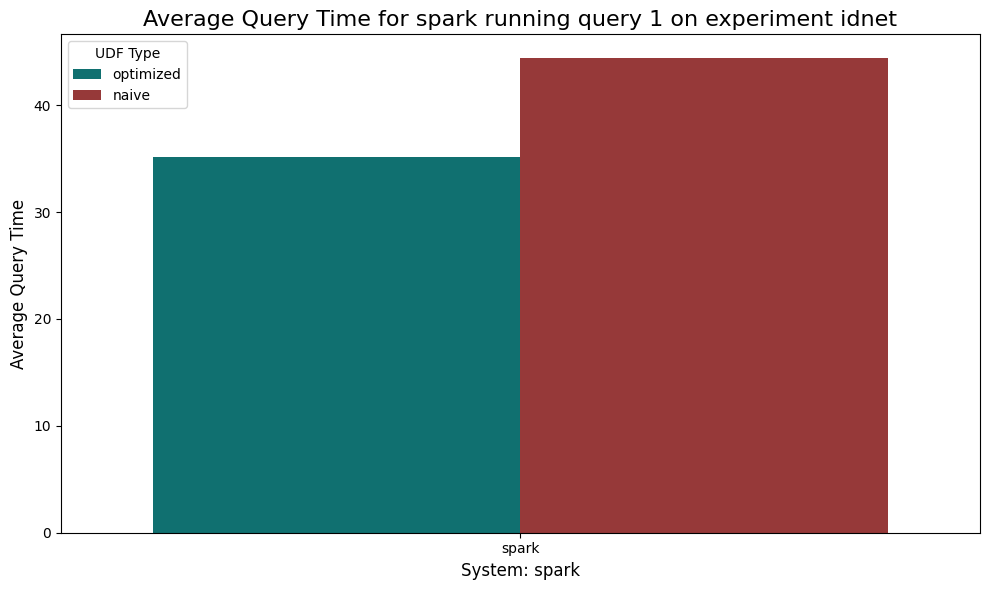

spark 2 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,2,optimized,35.0,39.950688,43.055421,167510.6,115023.5,56144.3,0.0,0.0,59.820348,0.228705,0.0,0.0,3.215830,0.0,9.921601,26.813999
1,idnet,spark,2,naive,29.0,39.755844,43.237293,130733.5,87352.9,44765.7,0.0,0.0,60.076441,0.168895,0.0,0.0,3.213055,0.0,6.449376,30.099197


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


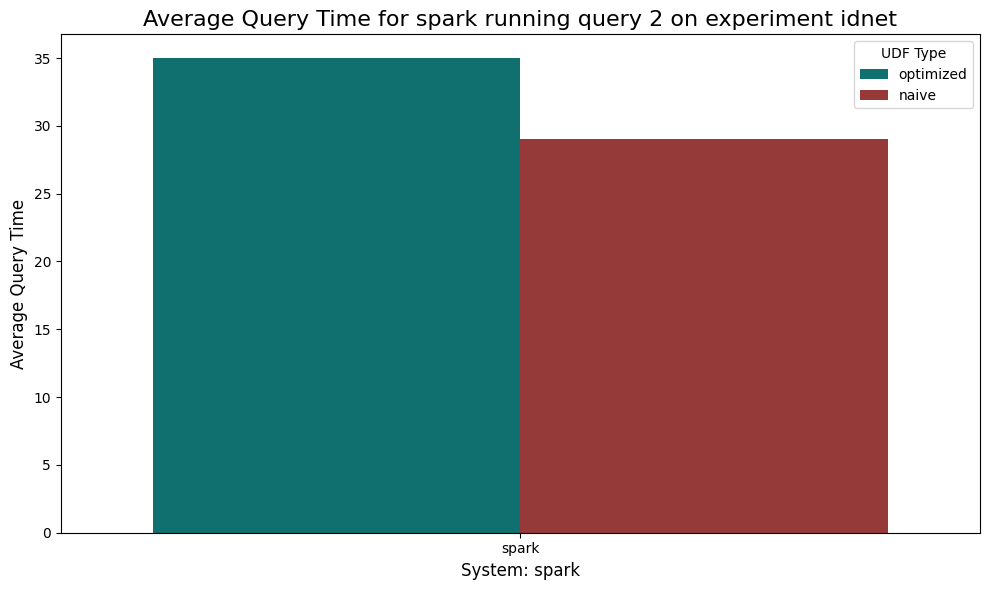

spark 3 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,3,optimized,4.0,29.588000,40.848000,22572.6,18710.5,9767.1,0.0,0.0,70.200000,0.2160,0.0,0.0,2.768000,0.0,5.674000,21.140000
1,idnet,spark,3,naive,7.0,30.974643,41.364643,35733.6,27622.6,13512.8,0.0,0.0,68.798036,0.2325,0.0,0.0,2.457143,0.0,4.814464,23.690179


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


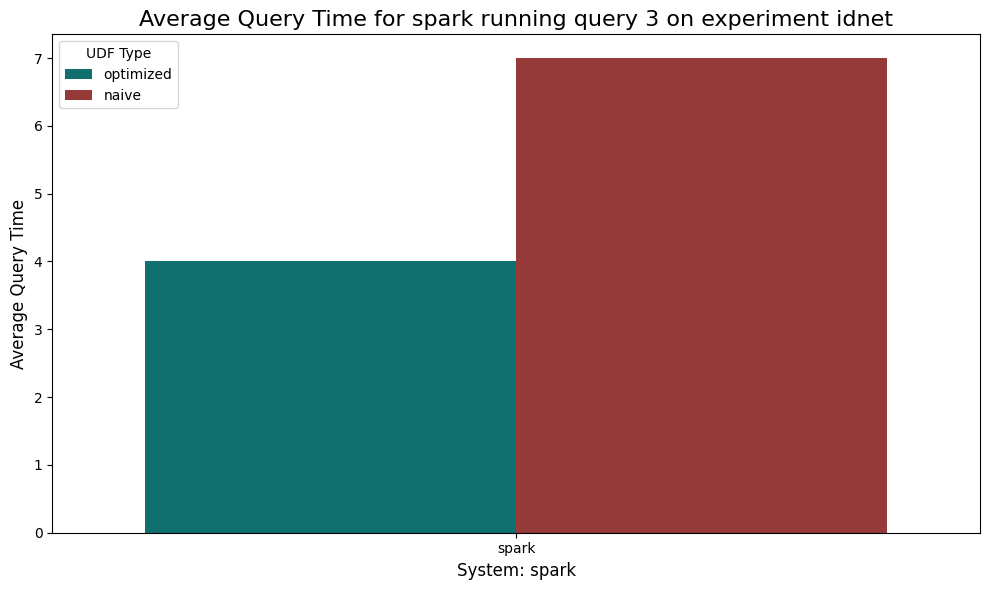

spark 4 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,4,optimized,4.2,30.305500,41.01350,21833.5,17827.5,9426.4,0.0,0.0,69.596500,0.096000,0.0,0.0,2.920500,0.0,6.1305,21.262500
1,idnet,spark,4,naive,7.3,32.367679,41.47375,37240.3,28394.3,14015.4,0.0,0.0,67.393214,0.241607,0.0,0.0,2.461429,0.0,4.6600,25.257679


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


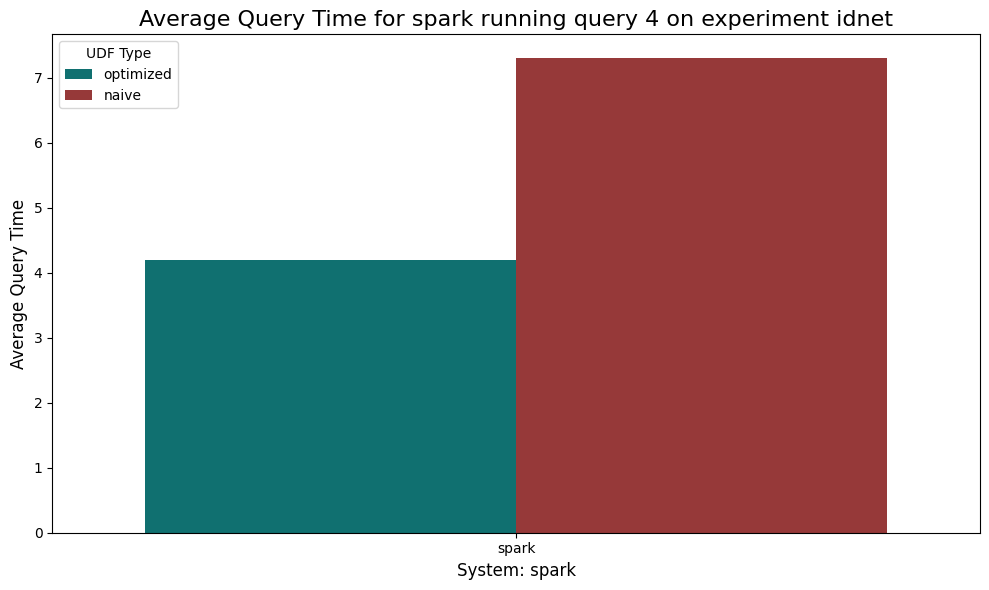

spark 5 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,5,naive,19.3,42.046333,42.222167,90599.9,60087.7,30836.7,0.0,0.0,57.546927,0.407737,0.0,0.0,3.454509,0.0,7.106287,31.48202
1,idnet,spark,5,optimized,23.3,39.842768,42.875626,109510.8,74158.7,37634.9,0.0,0.0,59.811196,0.349237,0.0,0.0,3.369891,0.0,9.536555,26.93587


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


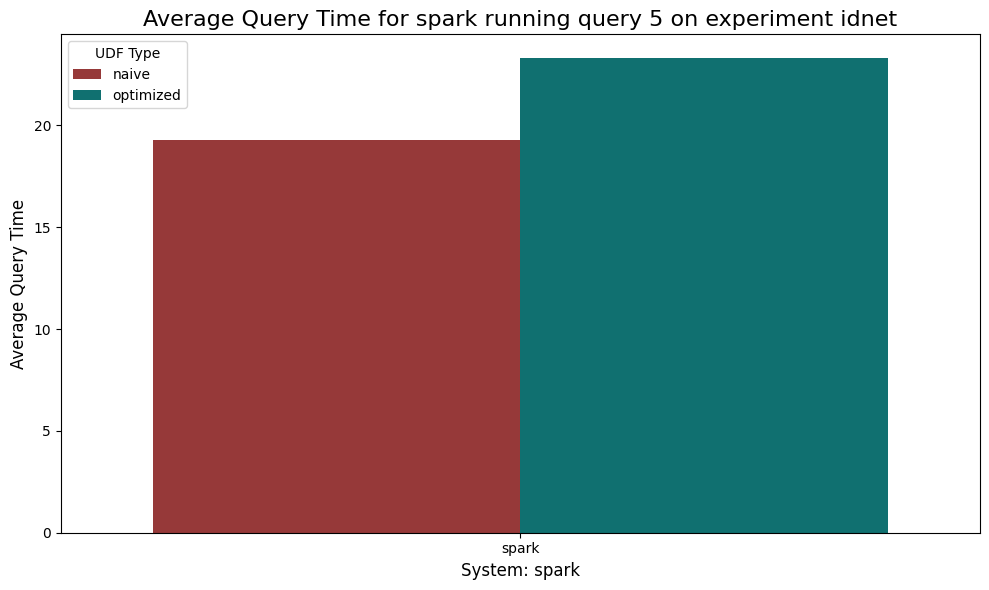

spark 6 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,6,optimized,221.3,34.194399,42.903422,1090178.9,767774.5,351110.3,0.0,0.0,65.546807,0.261175,0.0,0.0,2.585564,0.0,9.225125,22.388708
1,idnet,spark,6,naive,197.5,34.076313,43.243176,932763.5,648076.2,301621.2,0.0,0.0,65.723445,0.202158,0.0,0.0,2.462349,0.0,4.140282,27.479013


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


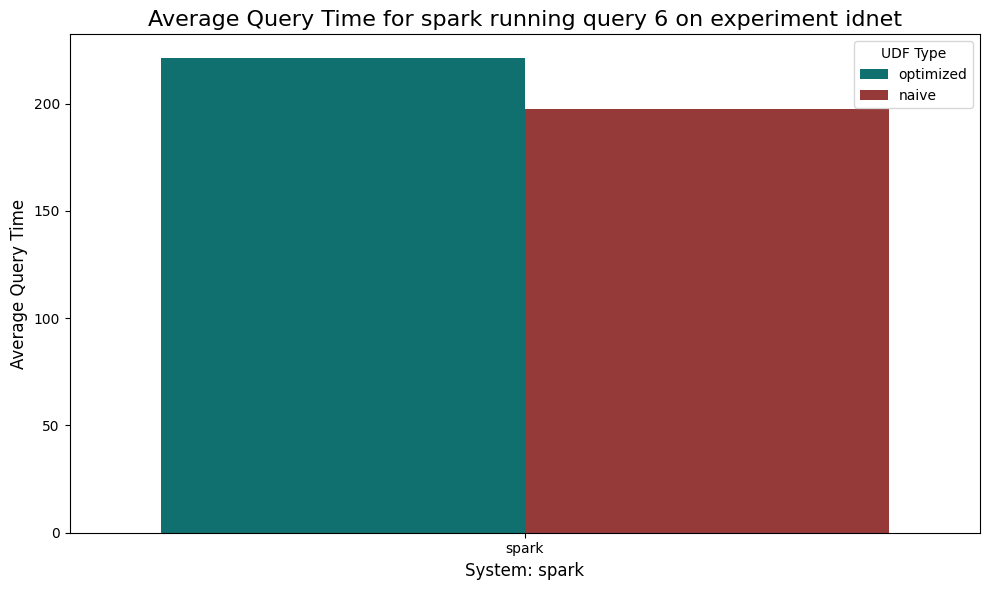

spark 7 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,7,naive,164.3,34.907064,44.169854,765677.6,529821.5,251051.8,0.0,0.0,64.944689,0.149300,0.0,0.000000,2.685279,0.0,4.450590,27.775884
1,idnet,spark,7,optimized,215.2,34.025351,43.166977,1054947.4,737032.5,340084.7,0.0,0.0,65.804830,0.171729,0.0,0.000101,2.580476,0.0,9.403329,22.044973


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


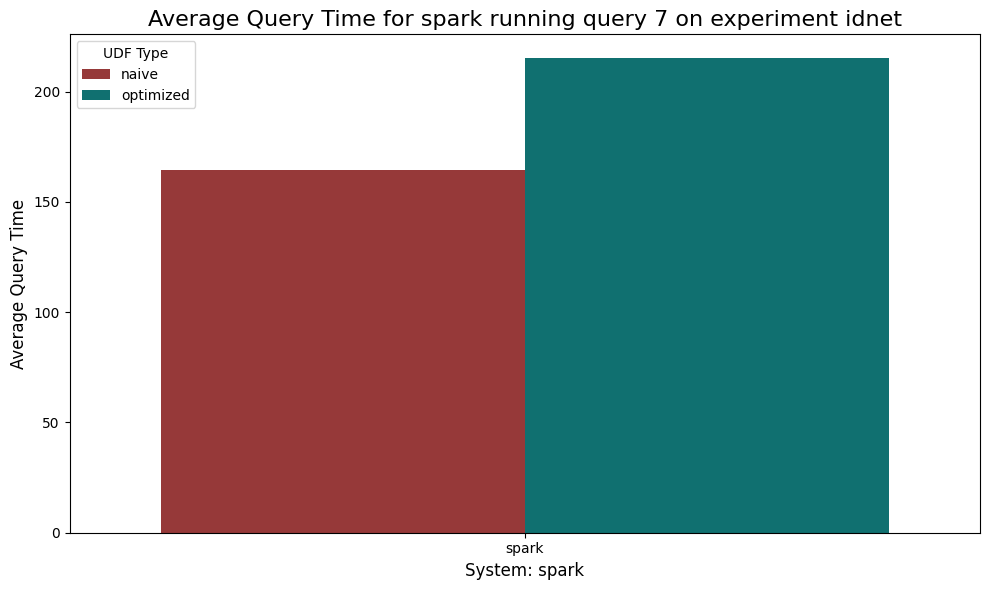

spark 8 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,8,naive,32.0,33.903923,42.684403,152077.0,109053.2,44717.4,0.0,0.0,65.971824,0.128869,0.0,0.0,2.660363,0.0,3.897686,27.353834
1,idnet,spark,8,optimized,11.8,42.206508,41.784555,55684.1,45701.0,18782.9,0.0,0.0,57.681161,0.112191,0.0,0.0,4.360231,0.0,7.033646,30.815082


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


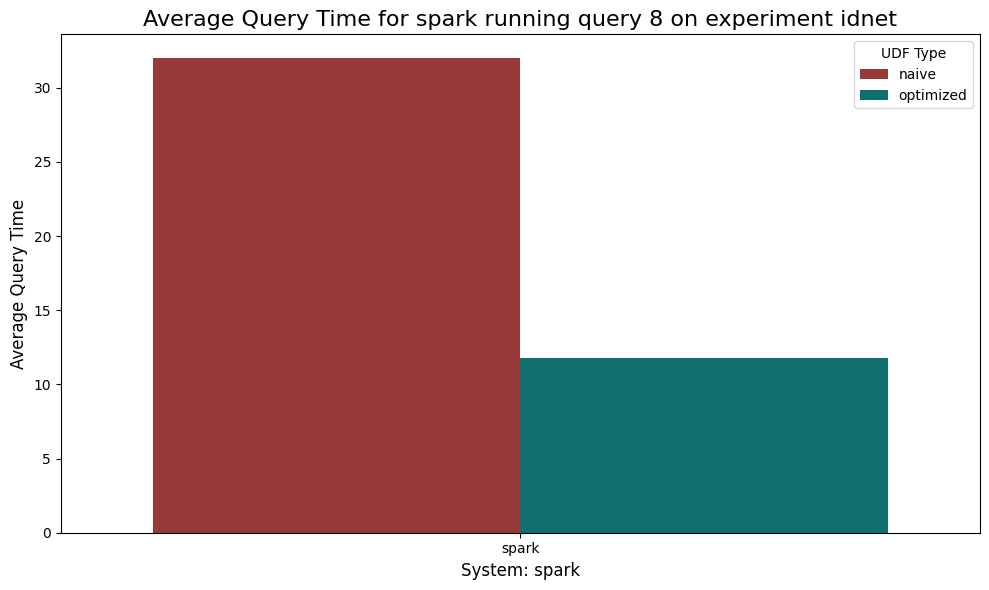

spark 9 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,9,optimized,35.0,40.553997,43.728304,166709.9,112610.2,55287.0,0.0,0.0,59.245924,0.196270,0.0,0.0,3.279537,0.0,9.763949,27.513892
1,idnet,spark,9,naive,29.8,41.057967,43.883869,135389.7,90584.6,45973.2,0.0,0.0,58.789819,0.151846,0.0,0.0,3.226905,0.0,6.119181,31.715484


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


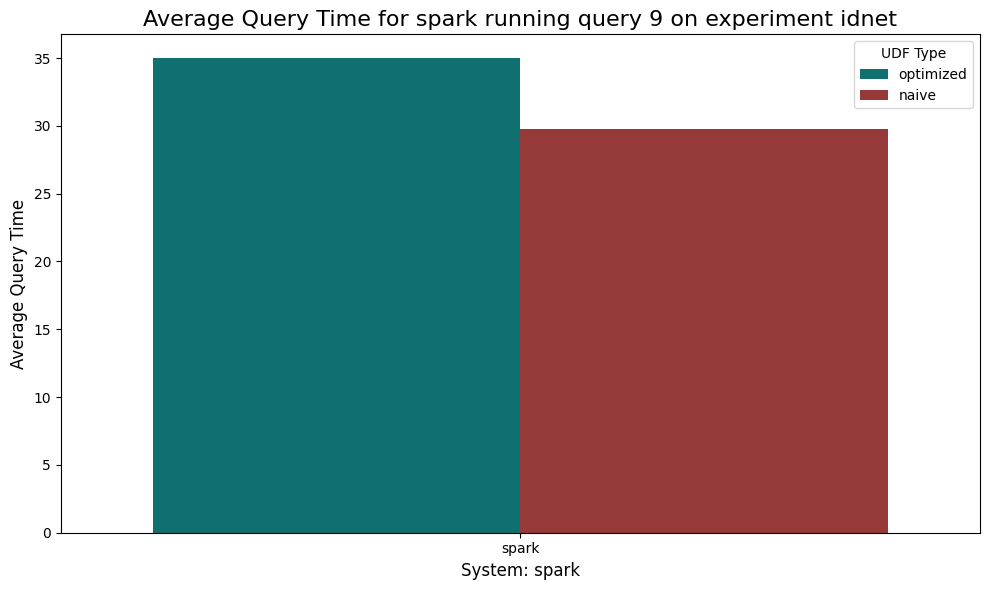

spark 10 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,10,optimized,10.9,39.702455,41.886364,49983.3,38168.8,17223.3,0.0,0.0,60.137273,0.159455,0.0,0.0,3.737182,0.0,6.595182,29.371273
1,idnet,spark,10,naive,31.9,32.976341,40.615975,152393.2,108986.8,45058.5,0.0,0.0,66.801057,0.226575,0.0,0.0,2.546023,0.0,3.994123,26.440991


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


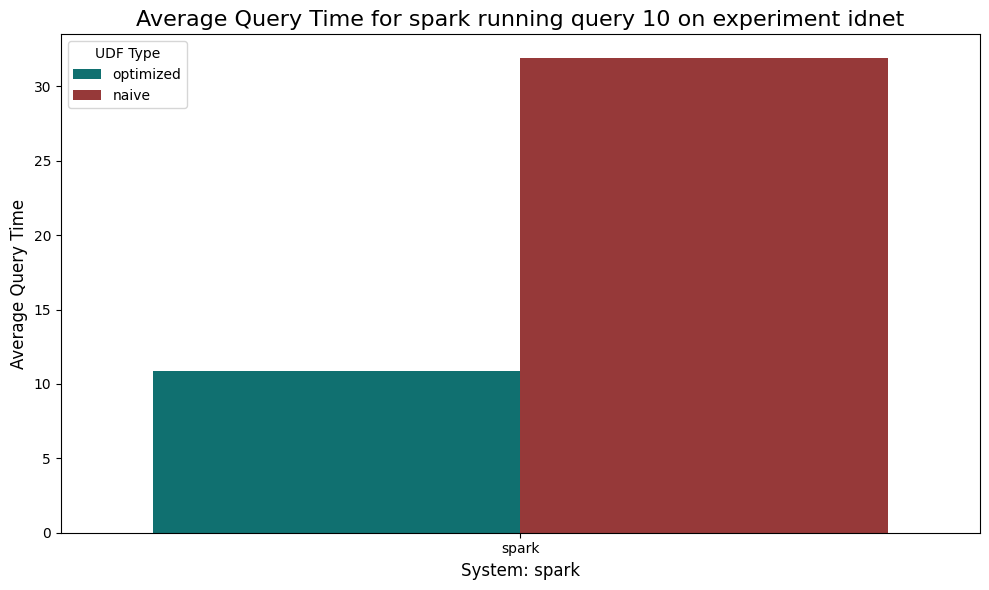

spark 11 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,11,optimized,36.9,41.631749,43.800174,178727.6,119238.5,59497.8,0.0,0.0,57.665550,0.704359,0.0,0.000000,3.404025,0.0,10.271631,27.957324
1,idnet,spark,11,naive,33.6,43.313414,42.359821,158294.9,106619.0,54186.5,0.0,0.0,54.499624,2.187578,0.0,0.155484,3.508681,0.0,7.195084,32.456594


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


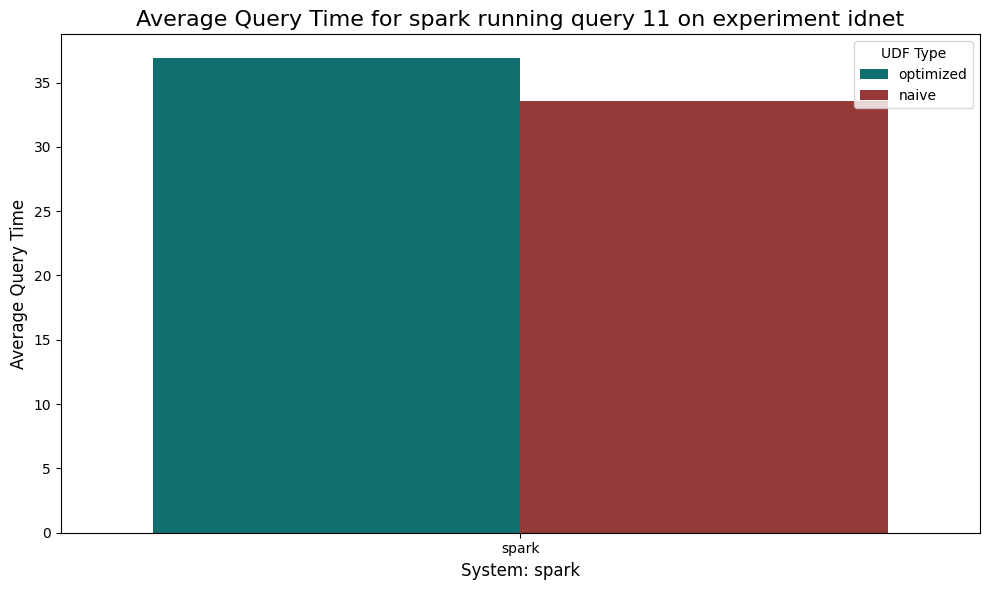

spark 12 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,12,naive,31.2,31.449175,40.750685,154867.4,110982.8,46299.4,0.0,0.0,68.386336,0.167123,0.0,0.0,2.143844,0.0,3.131425,26.177657
1,idnet,spark,12,optimized,10.1,32.337631,41.831187,51575.9,38931.7,18082.2,0.0,0.0,67.536520,0.124904,0.0,0.0,2.375515,0.0,4.543889,25.425808


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


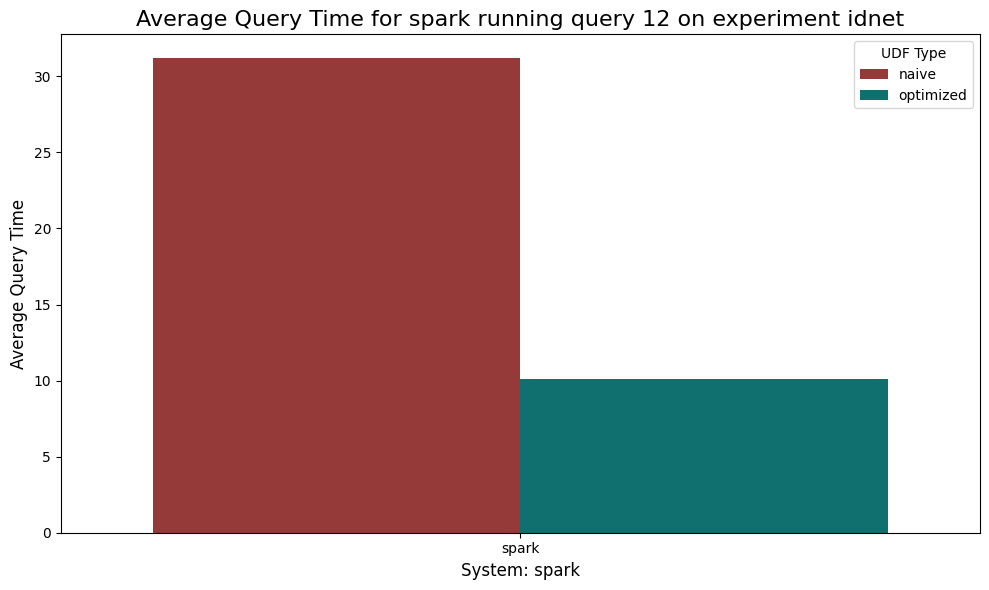

spark 13 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,13,optimized,434.5,34.971539,43.119063,2141637.8,1482200.8,689522.5,0.0,0.0,62.874495,2.155195,0.0,0.000048,2.709810,0.0,9.827675,22.437475
1,idnet,spark,13,naive,334.4,36.117135,42.586531,1574185.3,1085999.0,518016.4,0.0,0.0,61.438330,2.446403,0.0,0.000066,2.732265,0.0,4.813661,28.573664


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


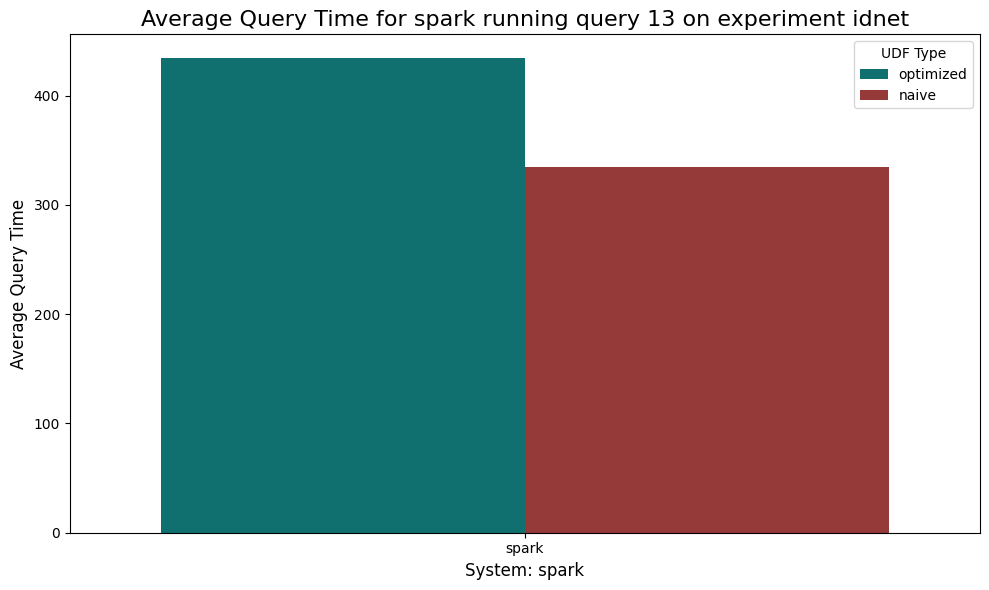

spark 14 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,14,naive,68.444444,33.440678,42.114316,328418.000000,235522.444444,99168.111111,0.0,0.0,61.035984,5.526921,0.0,0.0,2.808608,0.0,5.863841,24.773663
1,idnet,spark,14,optimized,25.222222,41.204418,42.374848,117865.777778,110232.444444,40536.222222,0.0,0.0,55.735460,3.058048,0.0,0.0,3.934938,0.0,10.869122,26.404511


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


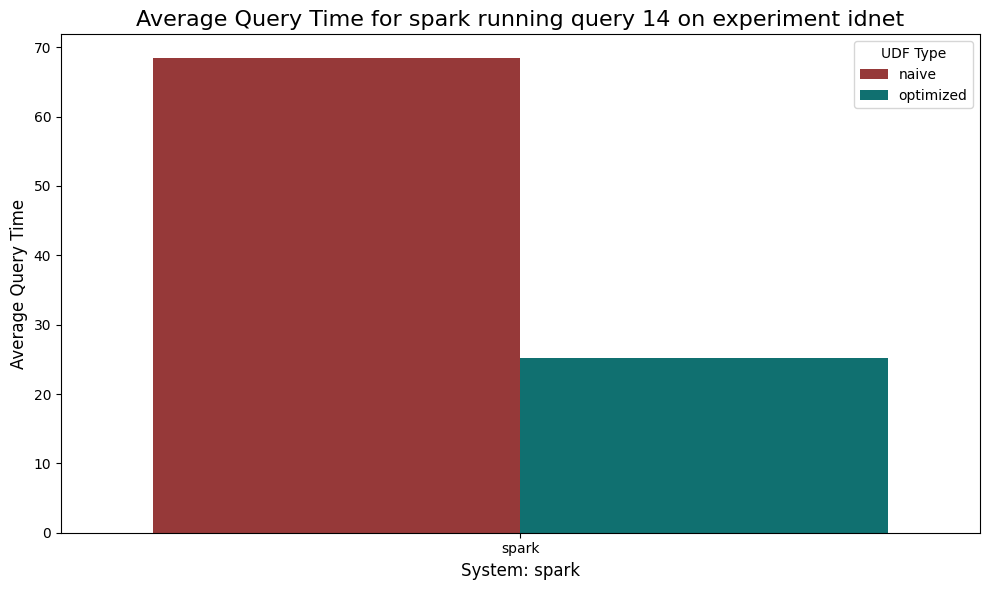

spark 1 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,1,optimized,201.8,65.092408,33.892231,941160.3,603389.0,270875.9,0.0,0.0,34.525552,0.382157,0.0,0.000000,5.559773,0.0,16.791594,42.740289
1,idnet10k,spark,1,naive,254.4,45.178496,31.517002,1279382.4,869749.3,455076.0,0.0,0.0,36.375769,18.445925,0.0,0.000077,4.073010,0.0,7.626420,33.477764


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


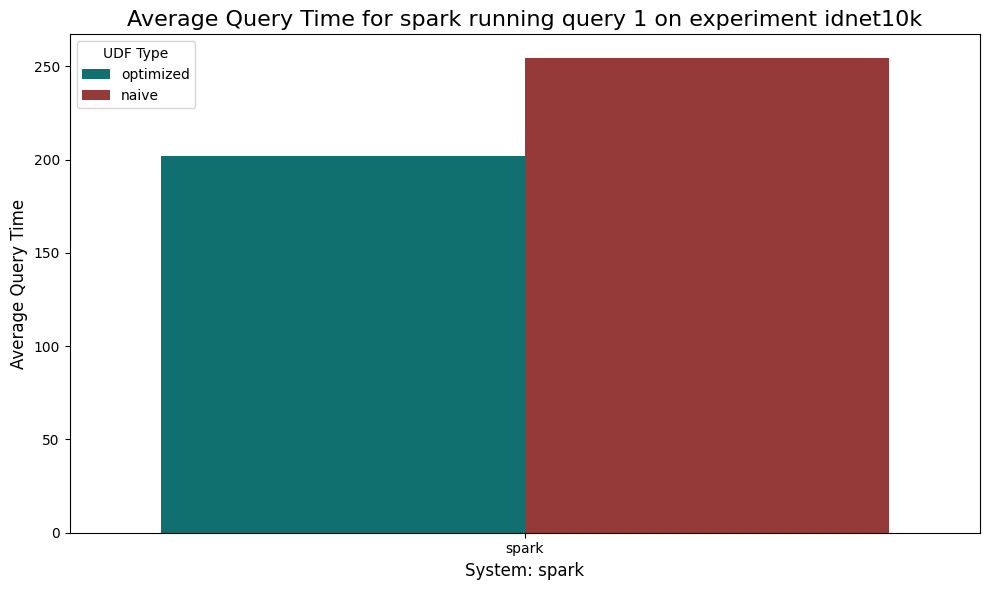

spark 2 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,2,naive,174.7,62.806460,33.143794,768212.7,400938.7,257461.7,0.0,0.0,36.925090,0.268797,0.0,0.0,5.061657,0.0,9.676918,48.066777
1,idnet10k,spark,2,optimized,204.6,64.287128,33.581052,935799.7,593369.8,267681.7,0.0,0.0,34.799169,0.913119,0.0,0.0,5.657405,0.0,17.144522,41.479106


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


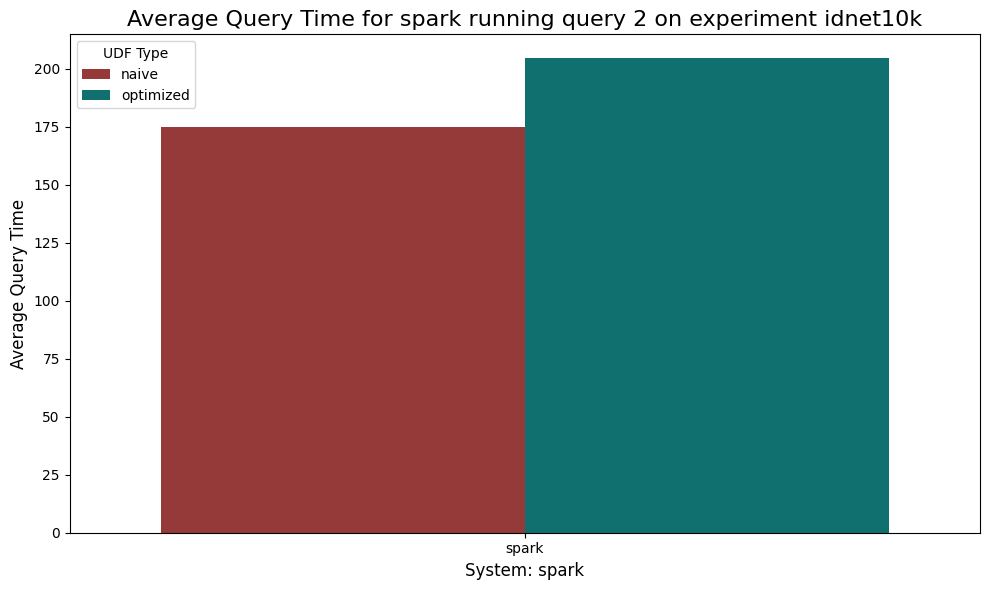

spark 3 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,3,naive,26.3,56.913688,30.935065,125876.2,70952.7,31579.9,0.0,0.0,42.606903,0.479379,0.0,0.002159,4.042594,0.0,5.517388,47.350896
1,idnet10k,spark,3,optimized,10.6,48.685894,29.075076,50302.7,33385.6,16214.5,0.0,0.0,50.661015,0.646106,0.0,0.000000,4.535318,0.0,6.688955,37.460788


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


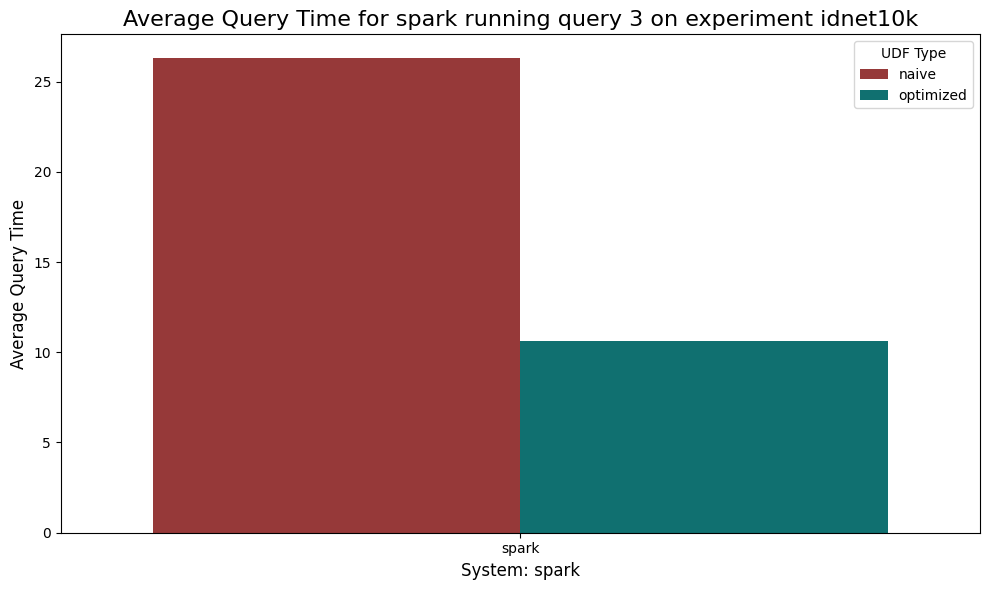

spark 4 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,4,naive,26.8,55.452491,29.151576,128097.5,71603.5,33160.4,0.0,0.0,43.979061,0.569656,0.0,0.0,4.092165,0.0,5.722601,45.642739
1,idnet10k,spark,4,optimized,10.9,51.738273,28.277636,53489.1,35514.8,17960.4,0.0,0.0,47.176000,1.085909,0.0,0.0,4.417818,0.0,6.616273,40.700818


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


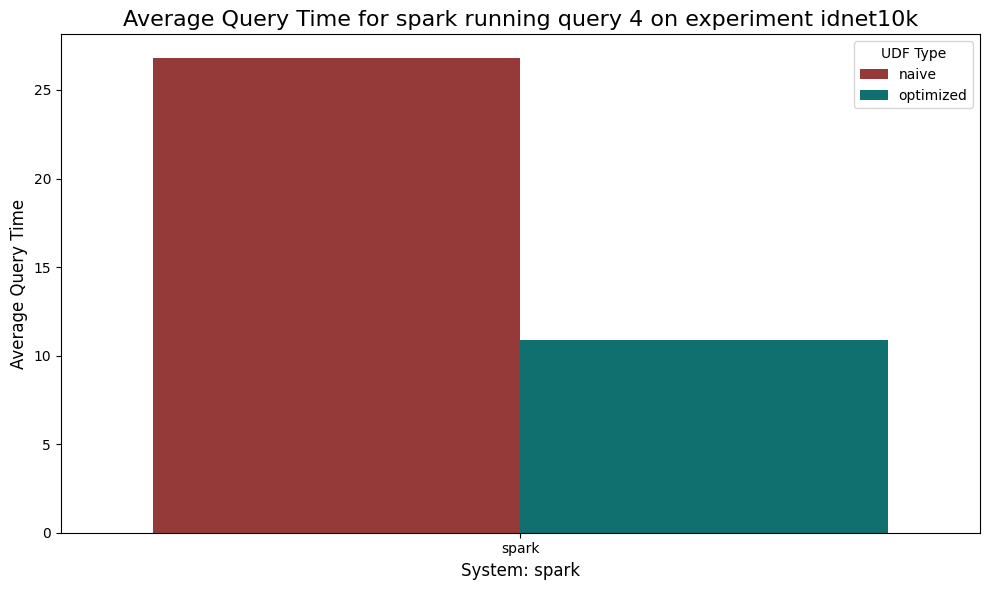

spark 5 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,5,optimized,125.6,64.438602,33.503772,559726.5,360584.2,162287.4,0.0,0.0,35.065193,0.496534,0.0,0.000000,5.992705,0.0,15.528254,42.914976
1,idnet10k,spark,5,naive,113.3,61.483219,32.196317,470768.0,255015.9,156269.3,0.0,0.0,38.271512,0.245094,0.0,0.000215,5.507187,0.0,10.851538,45.124720


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


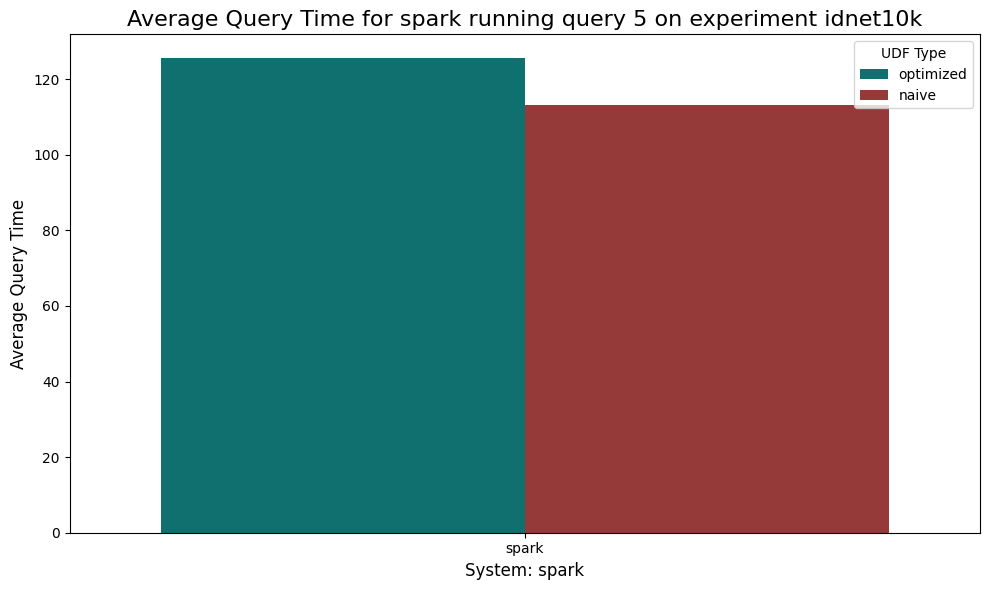

spark 6 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,6,naive,1077.4,48.807762,34.801279,3256261.0,1207454.80,1562408.8,0.0,0.0,50.407312,0.727058,0.0,0.000047,0.478807,0.0,4.265065,44.033629
1,idnet10k,spark,6,optimized,1176.5,55.347661,37.611637,4521022.5,1481890.75,2009174.0,0.0,0.0,44.326717,0.322374,0.0,0.000090,0.536304,0.0,14.893178,39.913568


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


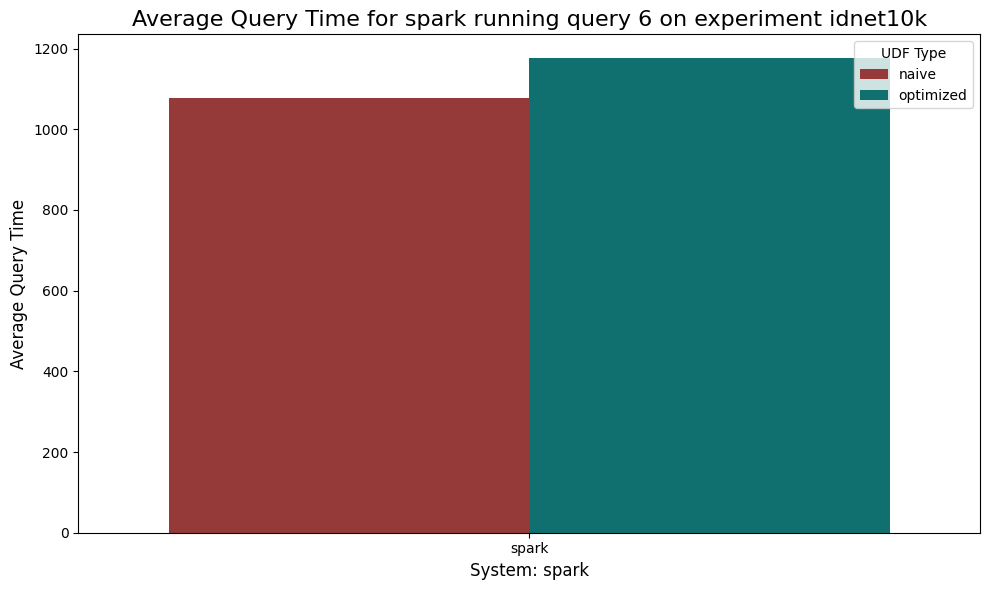

spark 7 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,7,optimized,1159.0,55.520347,31.604739,4563312.5,1490973.0,1986423.75,0.0,0.0,44.026623,0.445884,0.0,0.000230,0.537201,0.0,15.346228,39.624997
1,idnet10k,spark,7,naive,902.0,43.935220,33.998781,2360276.2,895125.6,1188903.00,0.0,0.0,55.781749,0.251590,0.0,0.000112,0.440371,0.0,2.997002,40.441842


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


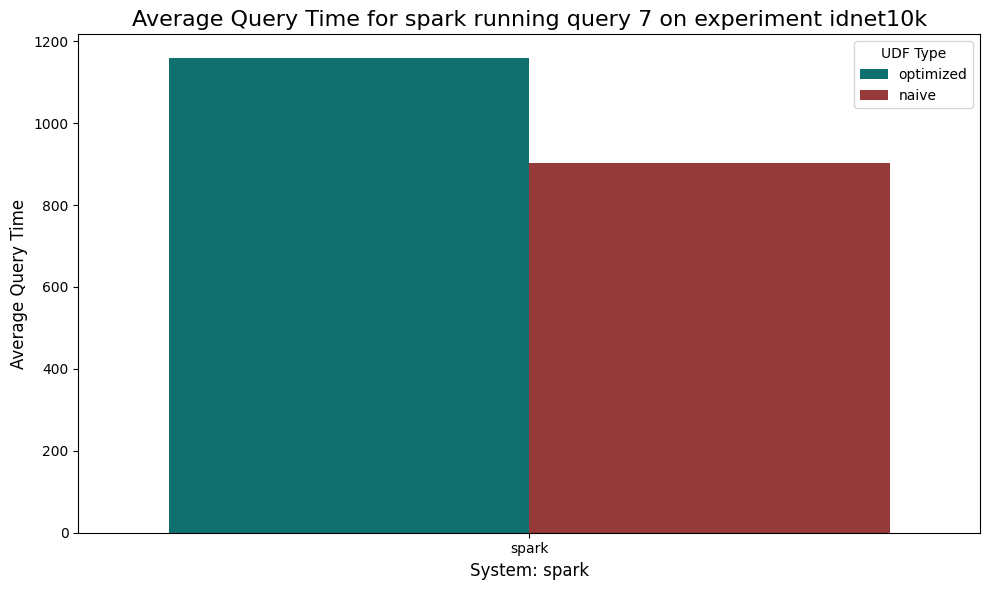

spark 8 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,8,optimized,43.5,33.839871,30.325127,60864.75,44182.0,26870.75,0.0,0.0,65.597377,0.259993,0.0,0.0,0.526002,0.0,3.063994,30.056682
1,idnet10k,spark,8,naive,130.0,36.192801,27.578163,260424.40,114696.2,81496.80,0.0,0.0,63.466882,0.320186,0.0,0.0,0.303423,0.0,1.557378,34.308552


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


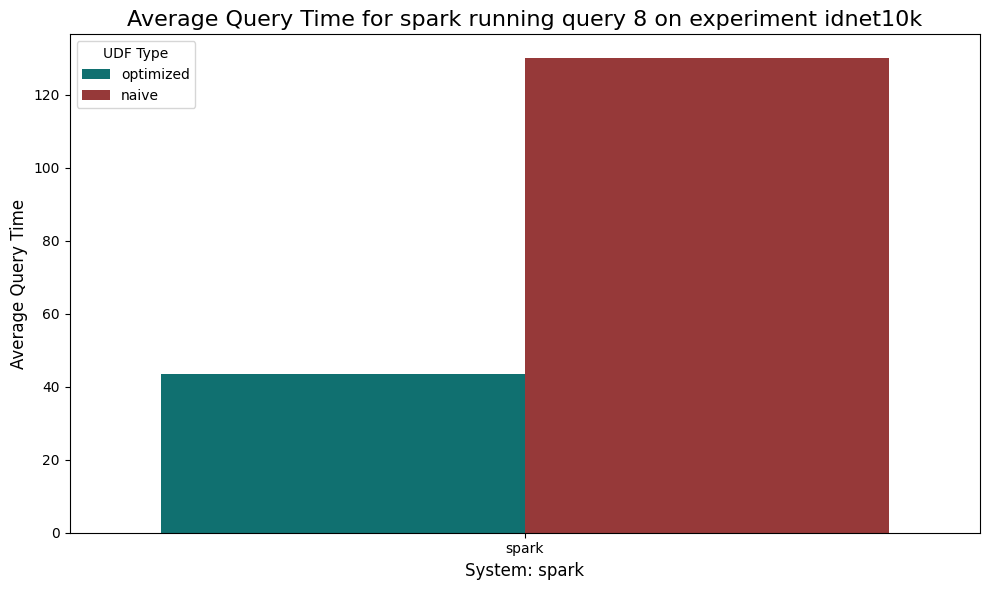

spark 9 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,9,naive,149.0,35.048626,25.800610,248044.00,136445.4,164688.60,0.0,0.0,64.466639,0.335348,0.0,0.383238,0.501894,0.0,2.992355,30.685489
1,idnet10k,spark,9,optimized,179.0,43.887567,31.131406,502194.75,198684.5,228171.25,0.0,0.0,55.693077,0.292949,0.0,0.000000,0.530277,0.0,11.797515,31.463040


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


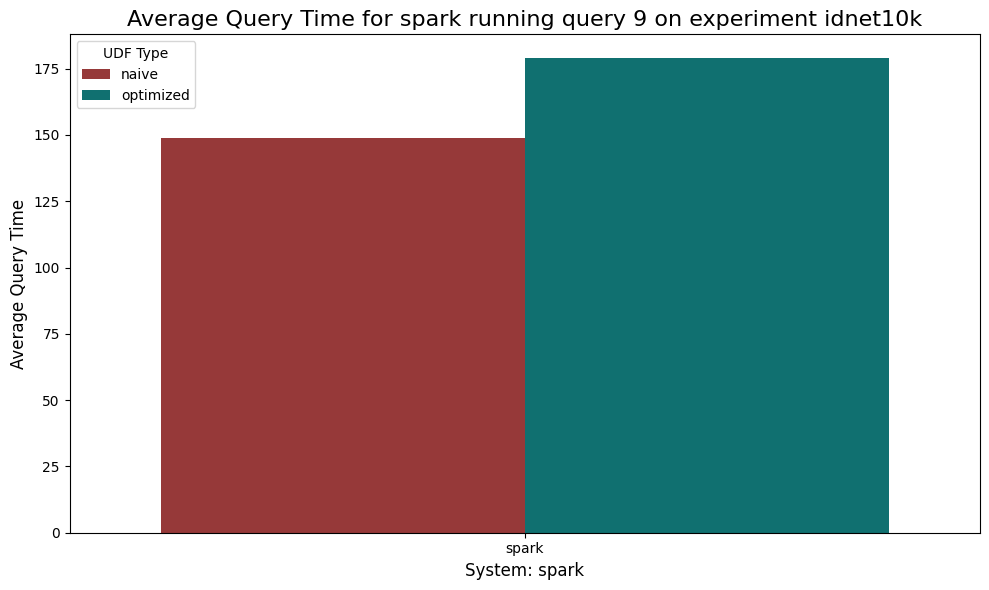

spark 10 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,10,naive,136.20,40.776999,25.669274,294650.00,138413.4,96513.60,0.0,0.0,58.319905,0.745501,0.0,0.608298,0.351881,0.0,1.981694,37.733856
1,idnet10k,spark,10,optimized,45.25,37.978112,26.805473,82010.75,51961.0,32751.25,0.0,0.0,61.499616,0.187061,0.0,0.000000,0.555232,0.0,3.805933,33.117272


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


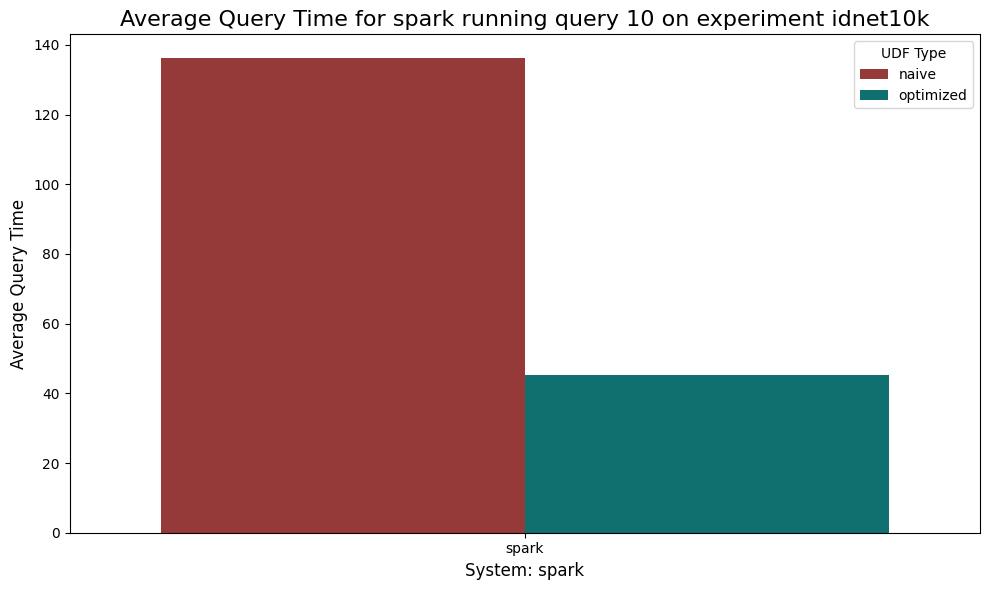

spark 11 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,11,naive,166.00,32.369469,26.822411,242755.20,174878.20,192028.8,0.0,0.0,54.211055,13.074812,0.0,0.943739,0.709570,0.0,4.935965,25.360075
1,idnet10k,spark,11,optimized,190.75,39.435112,27.850551,416125.25,201451.25,212897.0,0.0,0.0,52.287979,8.277645,0.0,0.000000,0.702847,0.0,9.984999,28.747382


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


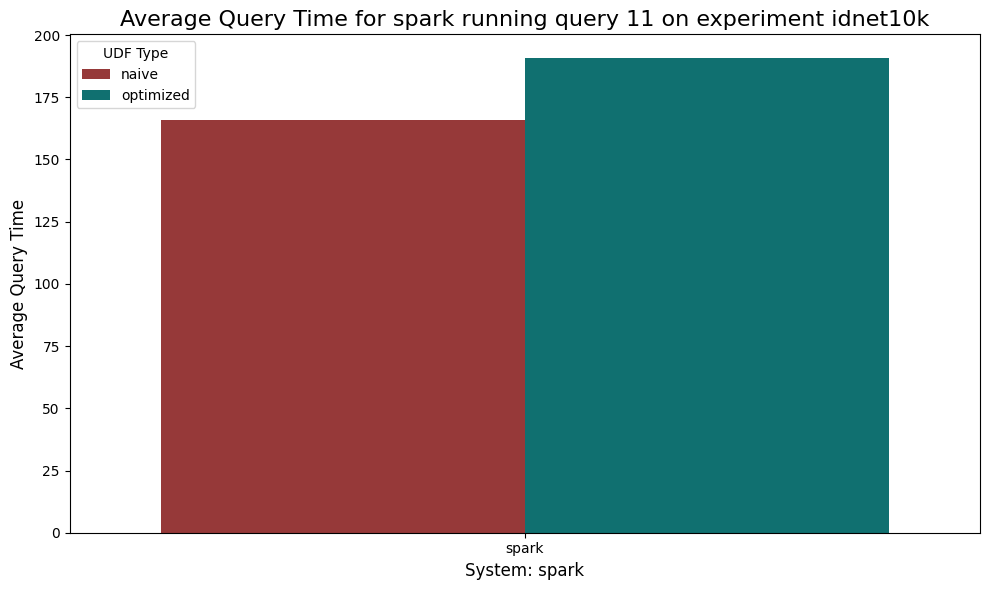

spark 12 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,12,optimized,31.25,43.234777,23.846089,92228.5,37665.0,33787.25,0.0,0.0,56.684793,0.085893,0.0,0.000000,0.297472,0.0,1.443994,41.499609
1,idnet10k,spark,12,naive,118.40,41.732189,22.358738,291841.8,131671.6,103103.40,0.0,0.0,57.099818,1.106744,0.0,0.388117,0.373368,0.0,1.477312,39.287743


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


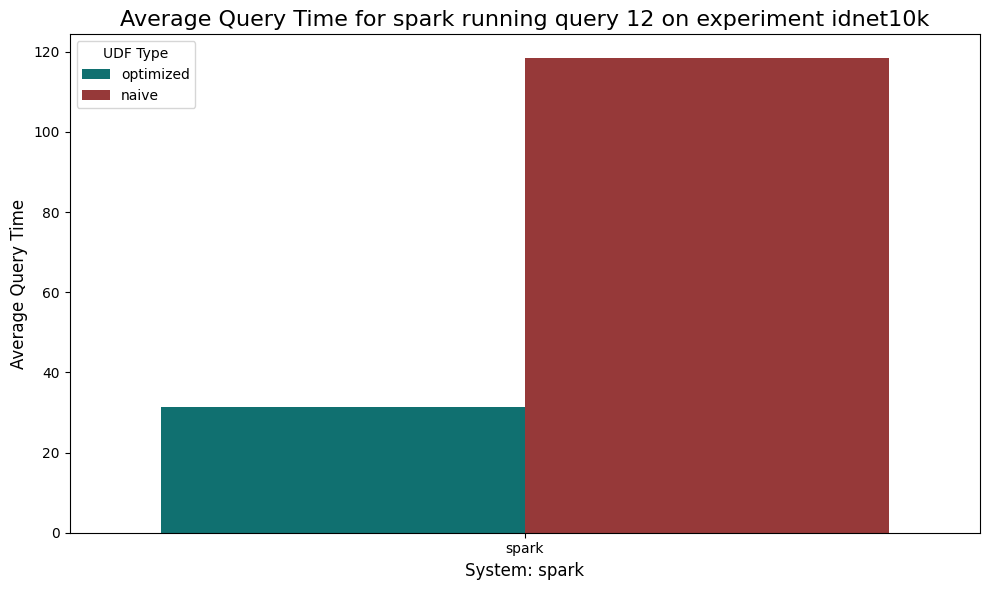

spark 13 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,13,naive,2550.80,28.263175,32.641166,6851237.80,5048411.0,3607266.4,0.0,0.0,57.735849,13.823933,0.0,0.268223,0.505312,0.0,3.533789,23.689558
1,idnet10k,spark,13,optimized,2777.25,41.587989,29.005629,9977484.25,5313601.5,4355307.0,0.0,0.0,48.715885,9.696047,0.0,0.000029,0.549877,0.0,11.962386,29.072099


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


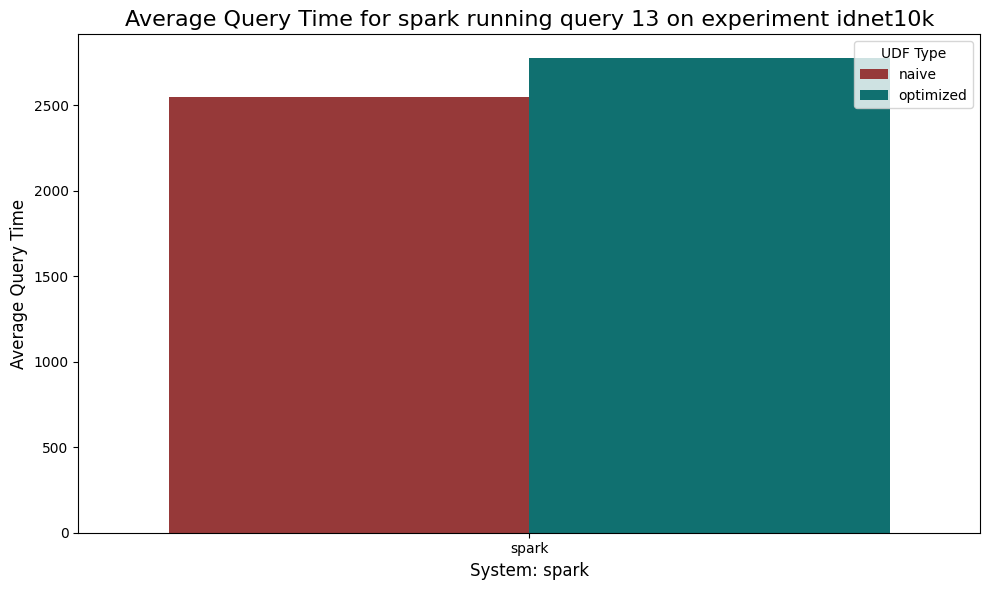

spark 14 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,14,naive,1266.6,14.011753,30.408252,4733952.6,4328684.8,2009856.40,0.0,0.0,56.394387,29.594029,0.0,0.000000,0.396627,0.0,3.273860,10.331818
1,idnet10k,spark,14,optimized,1200.5,7.860047,30.316615,4320243.5,4131643.0,2029572.25,0.0,0.0,56.980897,35.133575,0.0,0.000048,0.423708,0.0,3.338238,4.070028


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


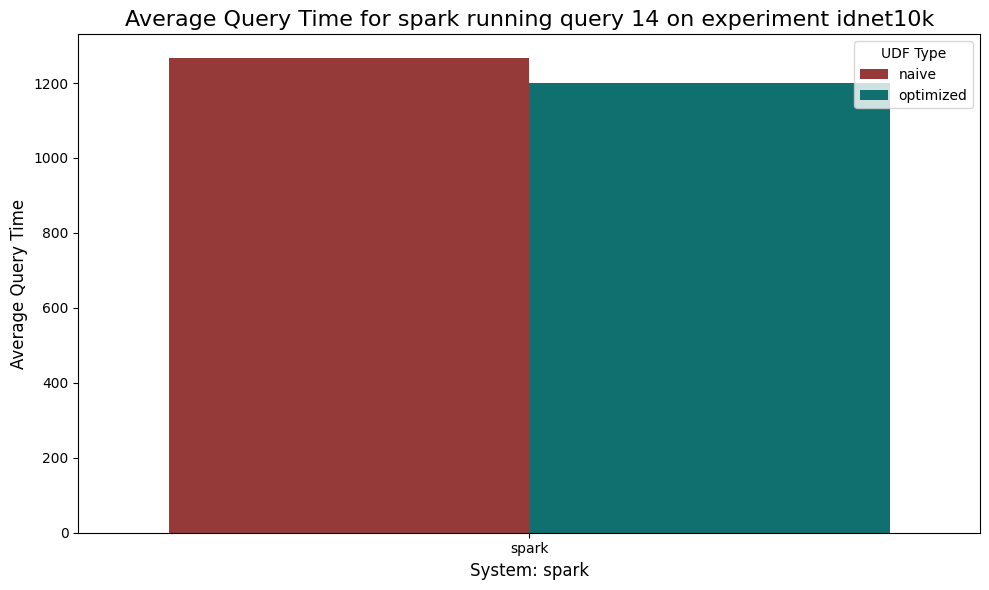

postgres 1 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,1,optimized,27.1,80.053963,40.123955,96466.8,60664.8,26980.2,0.0,0.0,19.901033,0.044257,0.0,0.000000,9.440527,0.0,13.168107,57.445337
1,idnet,postgres,1,naive,77.6,42.330436,34.543658,340370.5,255842.2,117197.7,0.0,0.0,55.964431,1.708655,0.0,0.001669,4.942549,0.0,10.340748,27.039953


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


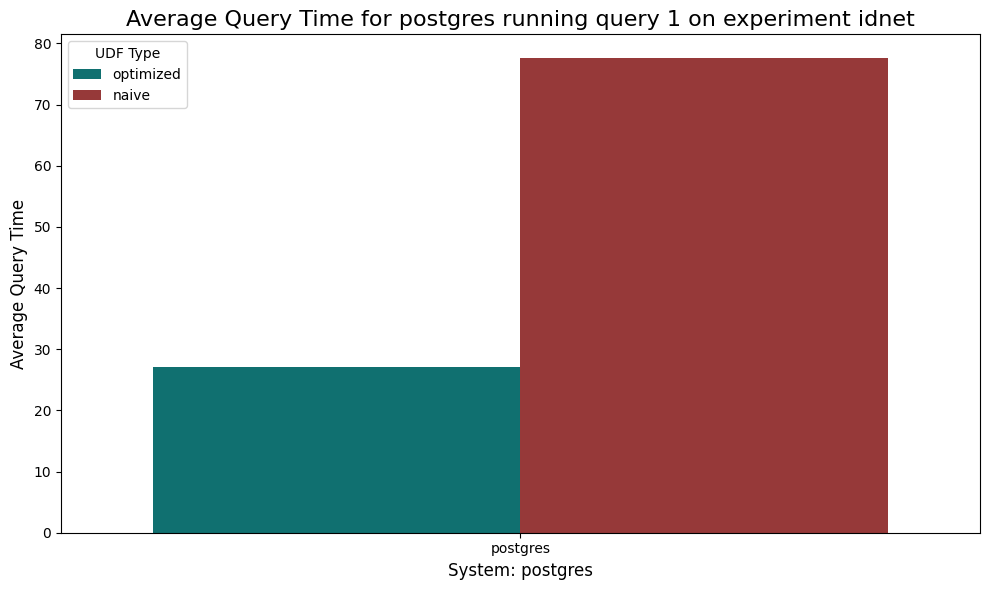

postgres 2 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,2,naive,71.1,45.071243,34.918272,302169.2,215439.2,101068.2,0.0,0.0,54.820118,0.109512,0.0,0.000375,4.891990,0.0,11.727611,28.449159
1,idnet,postgres,2,optimized,25.4,83.353208,39.962415,82974.5,49416.3,20013.4,0.0,0.0,16.587070,0.057069,0.0,0.000000,9.733576,0.0,13.440692,60.113763


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


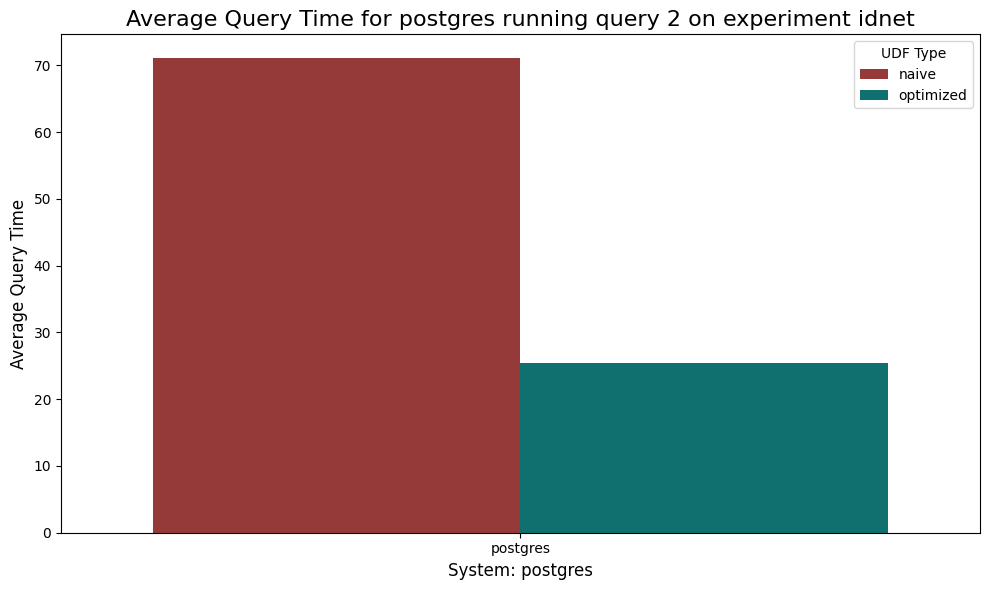

postgres 3 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,3,naive,16.8,69.417630,34.991612,65241.1,51130.1,19761.3,0.0,0.0,27.478327,3.10314,0.0,0.0,8.532558,0.0,11.471896,49.395315
1,idnet,postgres,3,optimized,10.4,82.205543,39.819737,35426.7,20498.5,7740.3,0.0,0.0,17.736336,0.05601,0.0,0.0,8.646934,0.0,14.890250,58.669331


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


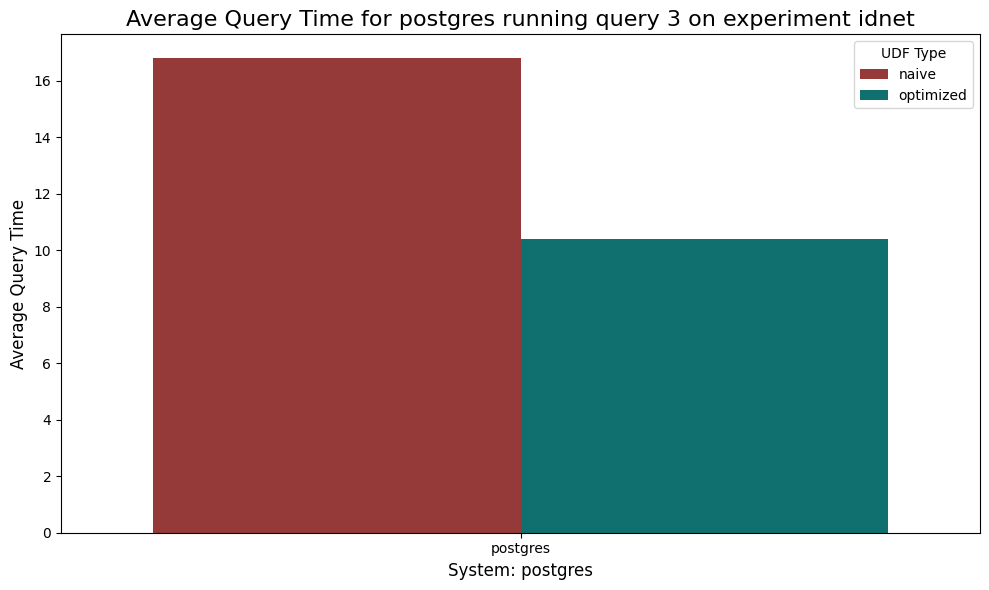

postgres 4 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,4,optimized,10.1,82.080444,39.461972,34105.1,17730.0,7446.8,0.0,0.0,17.906222,0.006667,0.0,0.0,8.777694,0.0,14.993500,58.120472
1,idnet,postgres,4,naive,13.2,84.064222,34.706211,44128.8,32488.0,10902.5,0.0,0.0,15.769684,0.167489,0.0,0.0,9.637161,0.0,12.537837,61.892990


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


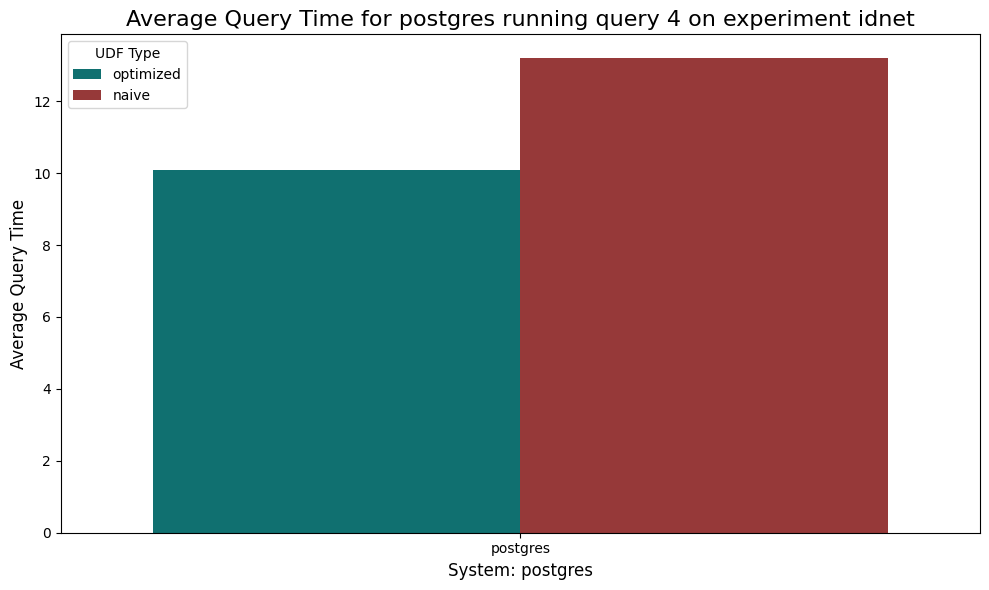

postgres 5 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,5,optimized,16.6,77.176820,39.711795,57161.6,37956.0,14864.2,0.0,0.0,22.776785,0.043654,0.0,0.0,8.957591,0.0,12.856952,55.335337
1,idnet,postgres,5,naive,41.4,45.195668,35.135668,170985.4,121357.9,55951.2,0.0,0.0,54.710680,0.095877,0.0,0.0,4.916805,0.0,11.099891,29.177995


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


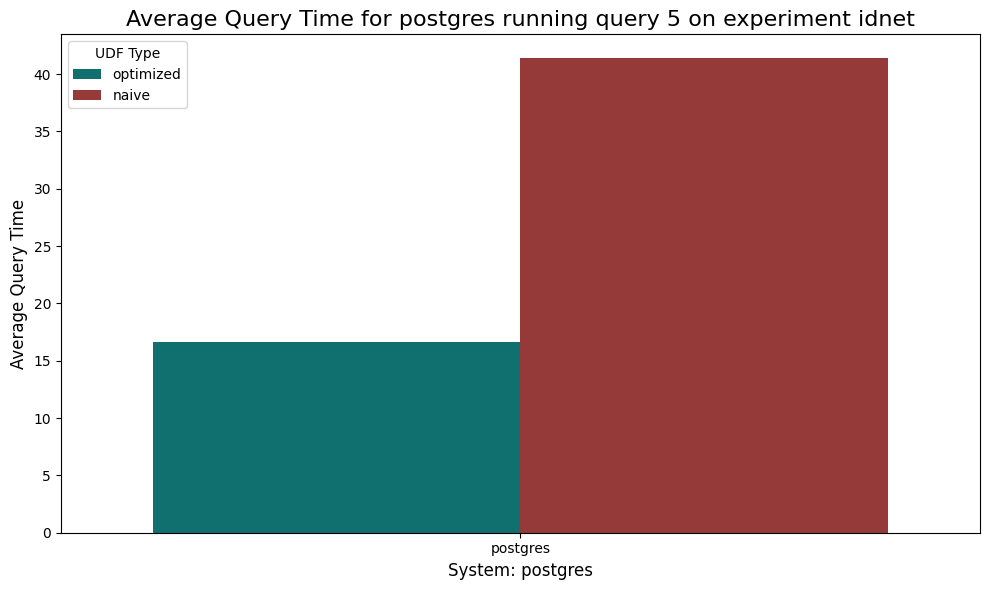

postgres 6 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,6,naive,511.9,55.752137,35.236009,1933467.7,1387324.0,1061834.5,0.0,0.0,44.153692,0.094760,0.0,0.000513,6.710994,0.0,11.405982,37.634398
1,idnet,postgres,6,optimized,276.4,82.840954,39.583009,1024085.4,747048.3,753853.1,0.0,0.0,17.120523,0.037889,0.0,0.000146,10.316173,0.0,14.071300,58.455512


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


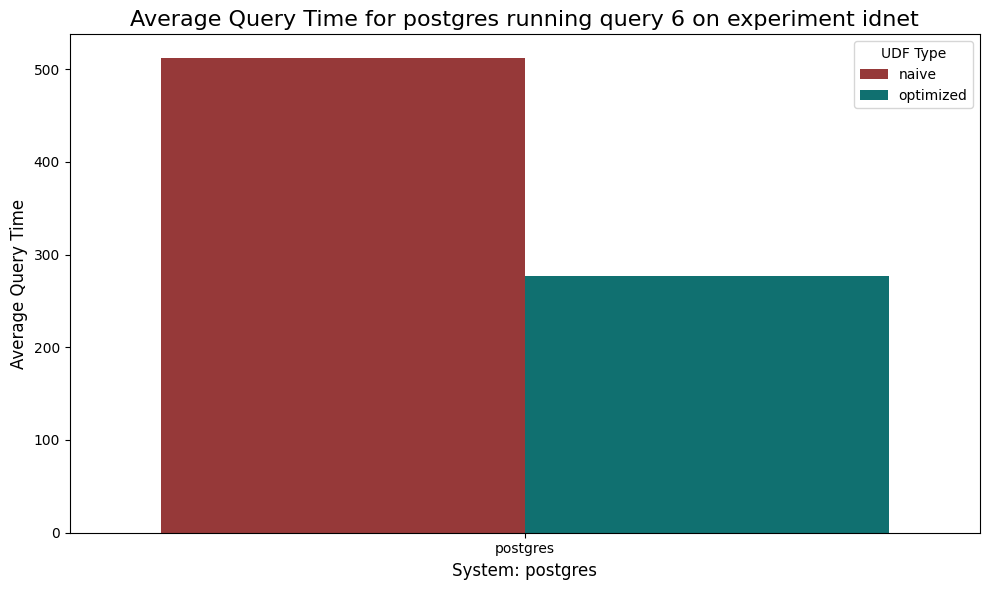

postgres 7 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,7,naive,444.1,45.43326,37.725106,1859950.7,1352711.1,1071366.2,0.0,0.0,54.467757,0.099990,0.0,0.000135,5.045540,0.0,11.177063,29.207768
1,idnet,postgres,7,optimized,187.8,83.26325,39.396391,735611.0,548582.8,656831.7,0.0,0.0,16.695500,0.040505,0.0,0.000680,9.866858,0.0,13.366869,60.024115


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


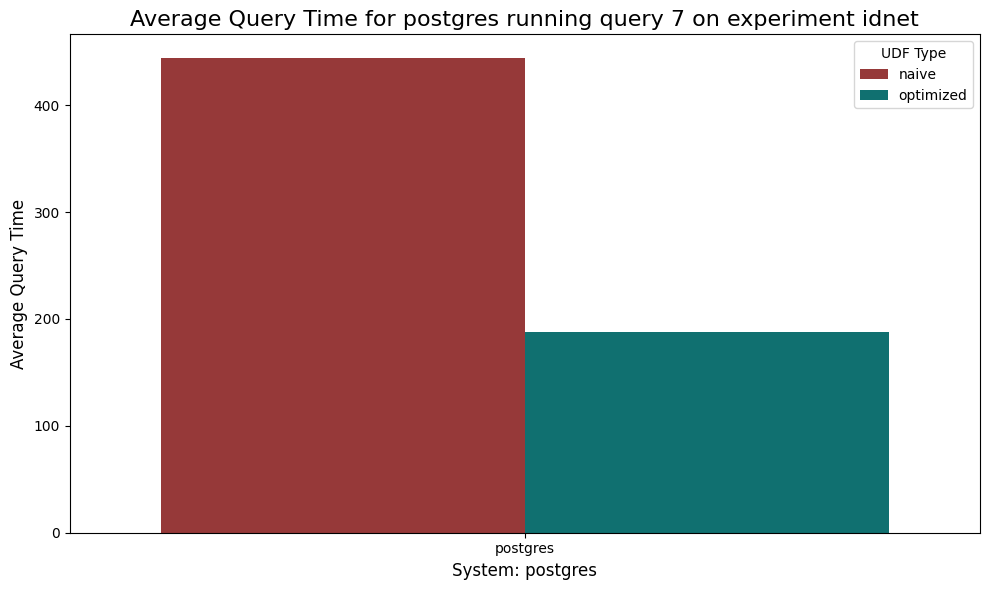

postgres 8 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,8,optimized,84.6,85.992686,39.559105,324430.6,308024.7,506261.4,0.0,0.0,13.967944,0.035467,0.0,0.000519,9.773693,0.0,13.680328,62.486968
1,idnet,postgres,8,naive,100.6,93.061535,37.825555,329399.1,443972.5,553741.4,0.0,0.0,6.906879,0.027242,0.0,0.000000,11.474985,0.0,14.941903,66.544014


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


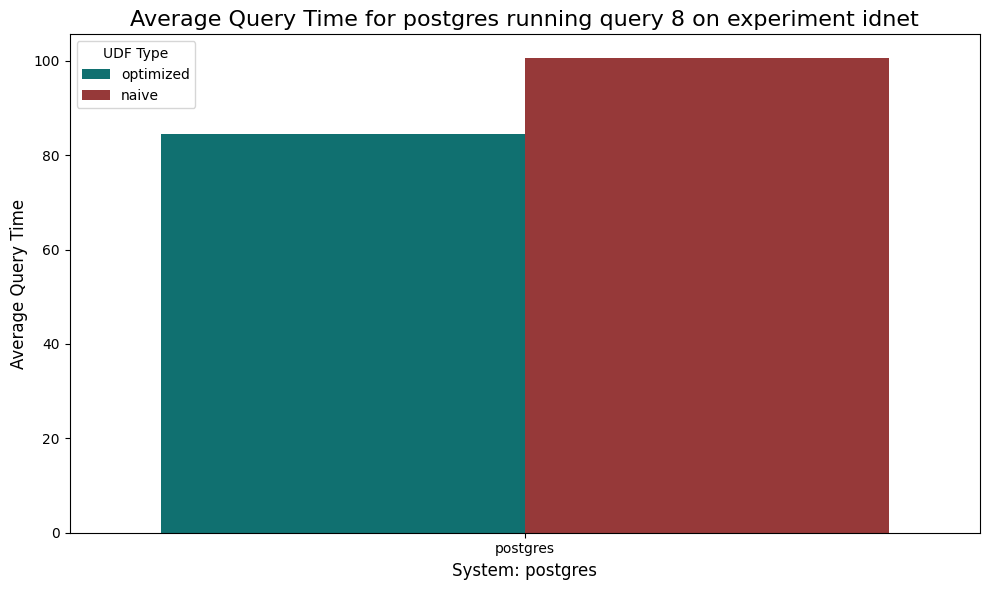

postgres 9 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,9,naive,73.1,43.852038,38.613852,318888.2,240219.8,483438.4,0.0,0.0,55.483649,0.664930,0.0,0.000400,5.207731,0.0,10.943381,27.702388
1,idnet,postgres,9,optimized,33.7,71.117577,40.537651,134375.2,106025.4,414326.0,0.0,0.0,28.783284,0.096989,0.0,0.002258,8.930876,0.0,12.798458,49.220524


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


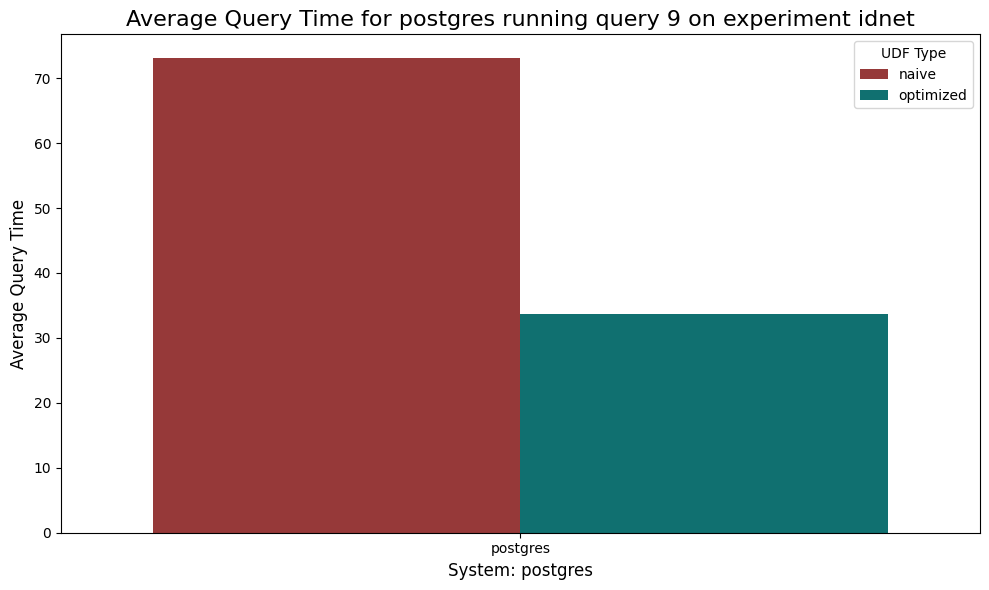

postgres 10 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,10,optimized,85.7,86.128287,40.042666,338625.4,308815.6,511259.6,0.0,0.0,13.834681,0.036754,0.0,0.000000,9.464003,0.0,13.712740,62.940509
1,idnet,postgres,10,naive,102.3,93.051590,38.212425,338871.3,468225.6,548147.4,0.0,0.0,6.806290,0.135798,0.0,0.000625,11.350302,0.0,15.186391,66.357341


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


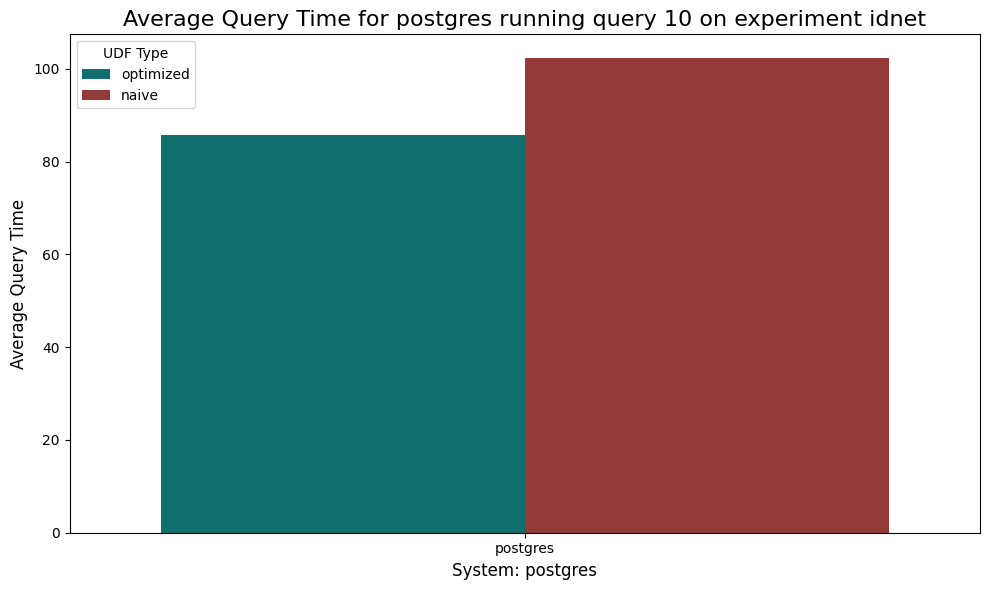

postgres 11 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,11,optimized,136.5,32.450607,40.282427,625442.4,473819.0,229260.3,0.0,0.0,67.437843,0.114465,0.0,0.0,3.234890,0.0,4.569627,24.629111
1,idnet,postgres,11,naive,173.7,29.536888,38.613529,793769.0,601946.3,288661.6,0.0,0.0,70.329991,0.134872,0.0,0.0,2.909928,0.0,5.418332,21.214336


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


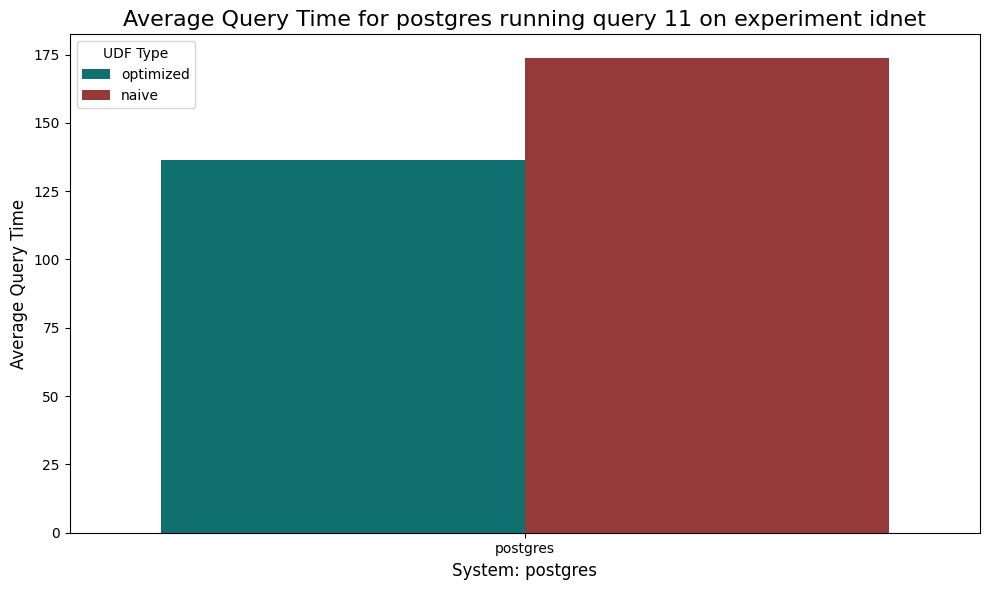

postgres 12 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,12,naive,13.6,81.983692,38.567311,44279.9,29671.8,10769.0,0.0,0.0,17.984527,0.031883,0.0,0.0,8.962256,0.0,12.288515,60.719643
1,idnet,postgres,12,optimized,67.6,93.738456,40.240181,212226.4,92482.0,36883.1,0.0,0.0,6.231216,0.025143,0.0,0.0,9.921058,0.0,16.345746,67.369725


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


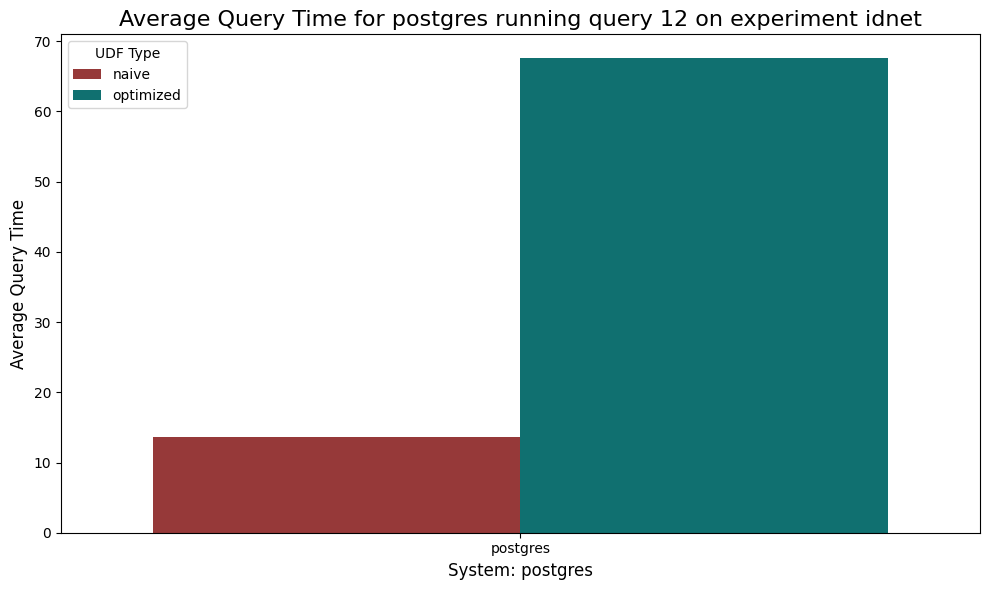

postgres 13 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,13,optimized,174.2,85.996548,40.677020,617957.8,388368.5,570824.3,0.0,0.0,13.962143,0.038523,0.0,0.000000,10.466348,0.0,14.749779,60.718435
1,idnet,postgres,13,naive,430.5,46.137511,38.985479,1770757.8,1211100.3,965394.8,0.0,0.0,53.768458,0.094817,0.0,0.000466,5.045370,0.0,11.155240,29.935374


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


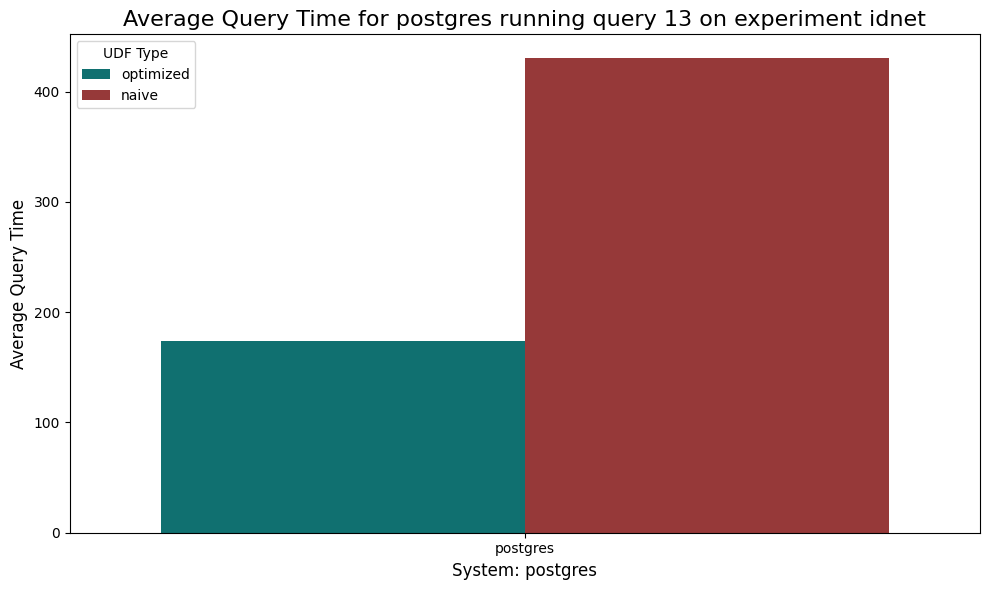

postgres 14 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,14,optimized,76.0,86.228617,40.772779,262823.1,153021.3,459330.9,0.0,0.0,13.733045,0.026435,0.0,0.0,9.463840,0.0,15.822194,60.784207
1,idnet,postgres,14,naive,91.6,87.281148,39.164643,310749.3,203958.9,472387.8,0.0,0.0,12.682868,0.035405,0.0,0.0,9.920878,0.0,13.788608,63.534294


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


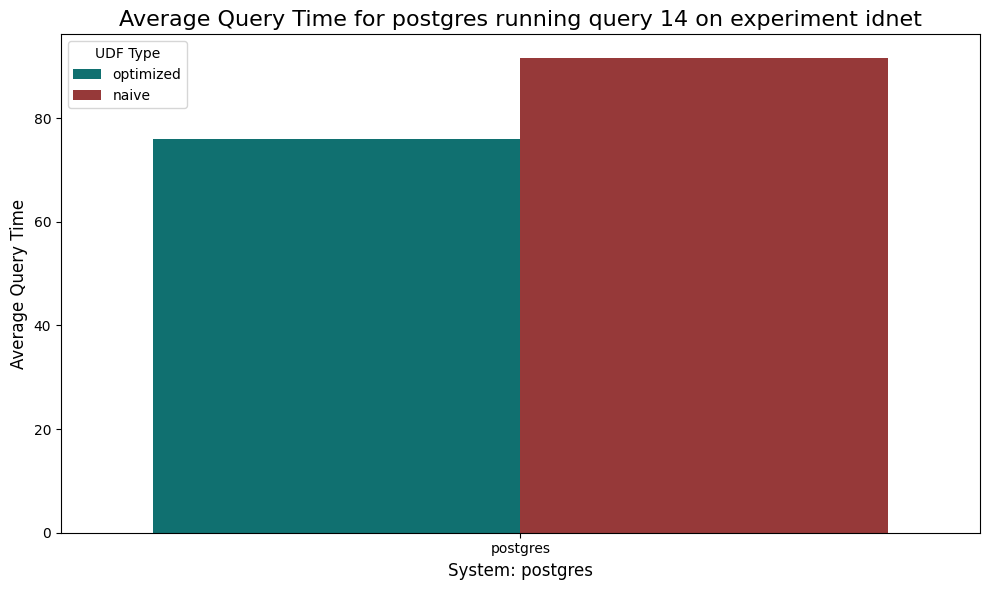

postgres 1 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,1,optimized,277.4,90.019927,12.279158,927058.4,569487.0,252098.3,0.0,0.0,9.740877,0.230594,0.0,0.000465,10.440010,0.0,14.869784,64.546736
1,idnet10k,postgres,1,naive,695.1,46.932389,26.774776,3178167.8,2210358.9,1023410.9,0.0,0.0,51.490762,1.575597,0.0,0.000186,5.159722,0.0,10.938005,30.832392


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


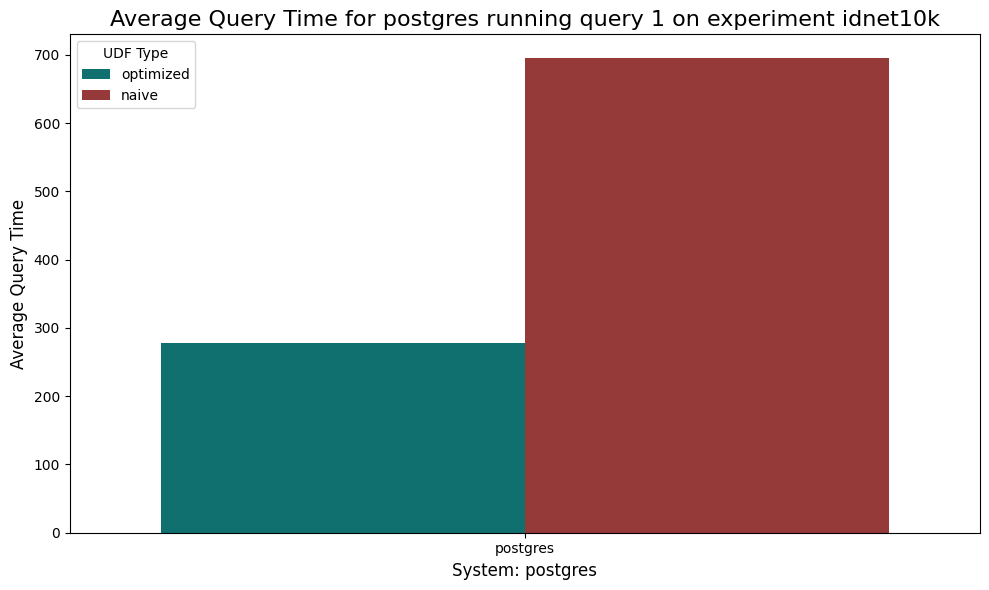

postgres 2 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,2,naive,629.0,49.845188,27.083022,2672340.1,1844692.3,830667.7,0.0,0.0,49.954211,0.202018,0.0,0.000046,5.581605,0.0,11.671832,32.590144
1,idnet10k,postgres,2,optimized,255.0,93.209222,12.143112,782103.1,450832.7,183450.6,0.0,0.0,6.768212,0.018585,0.0,0.000490,10.529234,0.0,15.058867,67.463172


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


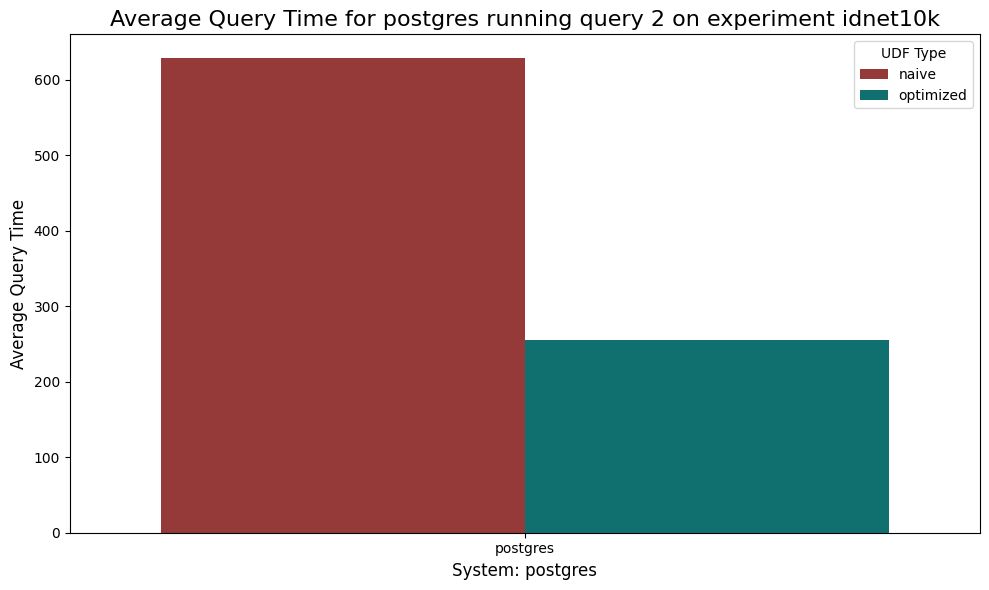

postgres 3 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,3,optimized,100.0,94.608905,12.003804,294021.7,129118.7,49194.7,0.0,0.0,5.368177,0.015901,0.0,0.000000,9.170596,0.0,19.864094,65.283486
1,idnet10k,postgres,3,naive,128.5,88.133316,27.166488,385820.6,227964.2,80246.0,0.0,0.0,10.975628,0.875114,0.0,0.001175,11.719558,0.0,14.198258,62.021481


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


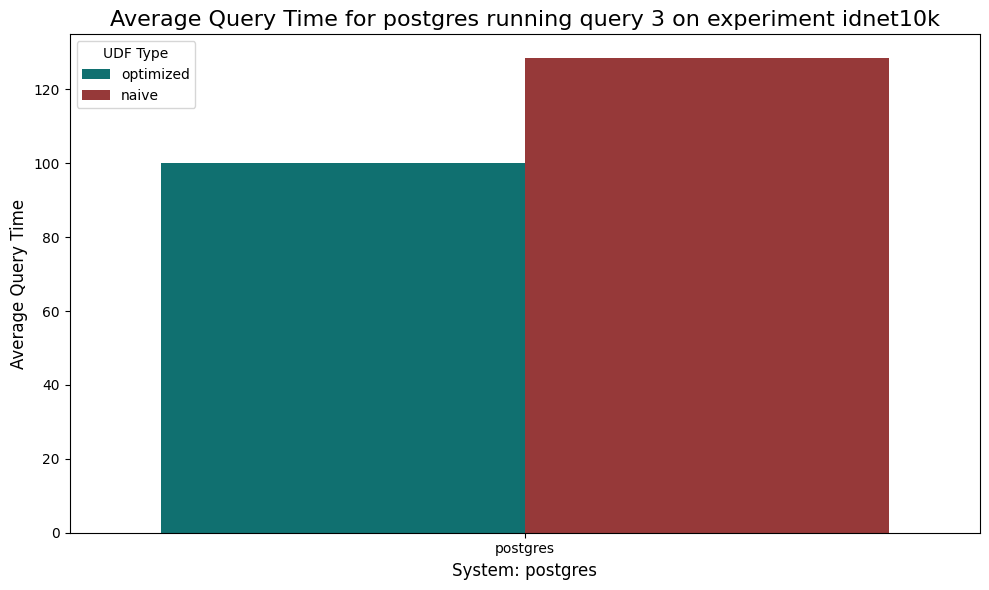

postgres 4 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,4,optimized,99.8,94.609901,11.782196,288468.9,131006.3,47838.8,0.0,0.0,5.360701,0.017484,0.0,0.000000,9.300339,0.0,19.671388,65.150248
1,idnet10k,postgres,4,naive,123.0,93.035855,27.161528,355759.0,191326.0,65586.6,0.0,0.0,6.910753,0.034239,0.0,0.000549,12.292970,0.0,14.934563,65.469626


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


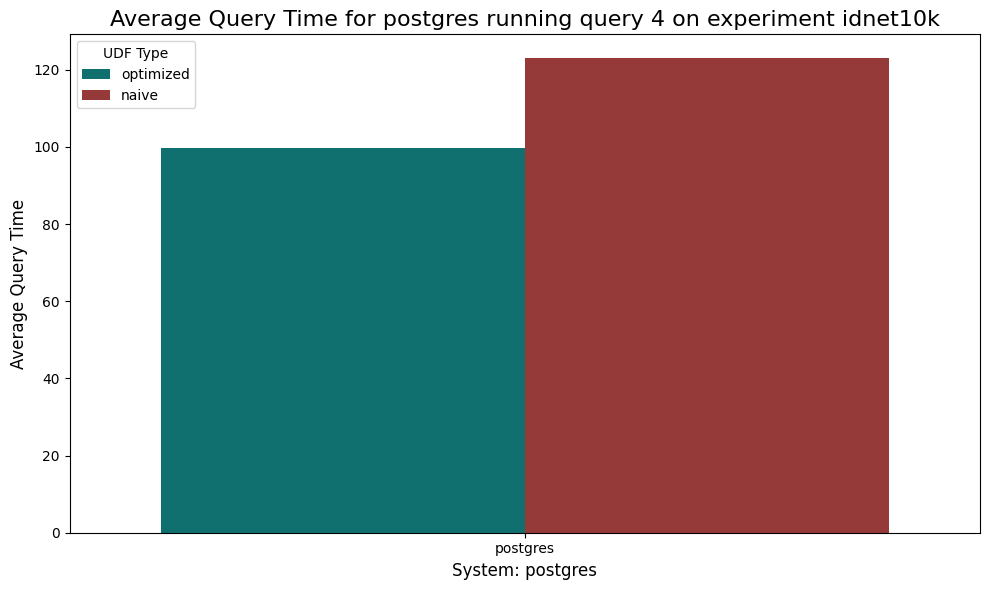

postgres 5 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,5,optimized,150.3,92.496061,12.174496,461521.1,274630.4,111716.2,0.0,0.0,7.478975,0.014557,0.0,0.000661,10.427595,0.0,15.018944,66.844809
1,idnet10k,postgres,5,naive,396.7,48.632767,27.571515,1725829.7,1183909.6,546080.9,0.0,0.0,51.252341,0.115463,0.0,0.000144,5.307466,0.0,12.197372,31.127535


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


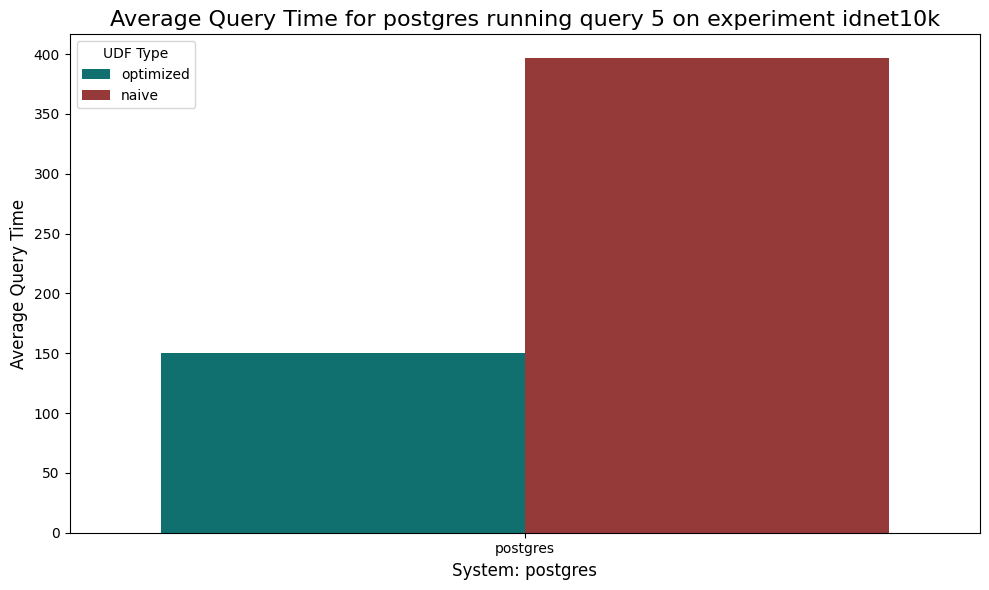

postgres 6 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,6,optimized,2098.4,80.749654,68.784055,5616883.8,6236388.8,7310194.0,0.0,0.0,18.141894,1.074964,0.0,0.000775,9.829204,0.0,9.57148,61.03791


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


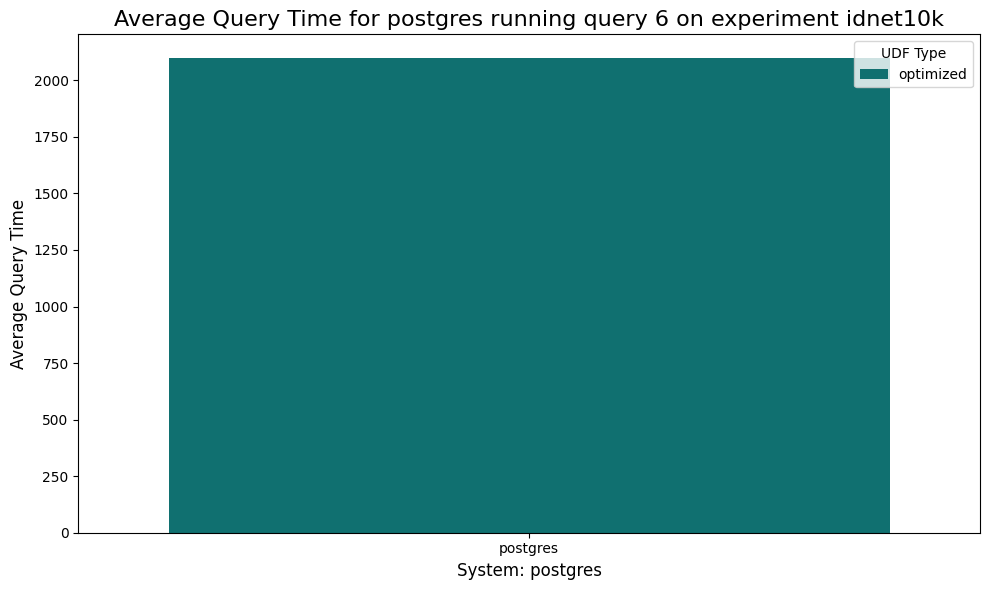

postgres 7 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,7,optimized,1559.8,76.791206,83.206696,4450295.8,4656391.6,6517796.2,0.0,0.0,21.888485,1.316112,0.0,0.0002,8.804574,0.0,9.017467,58.706005


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


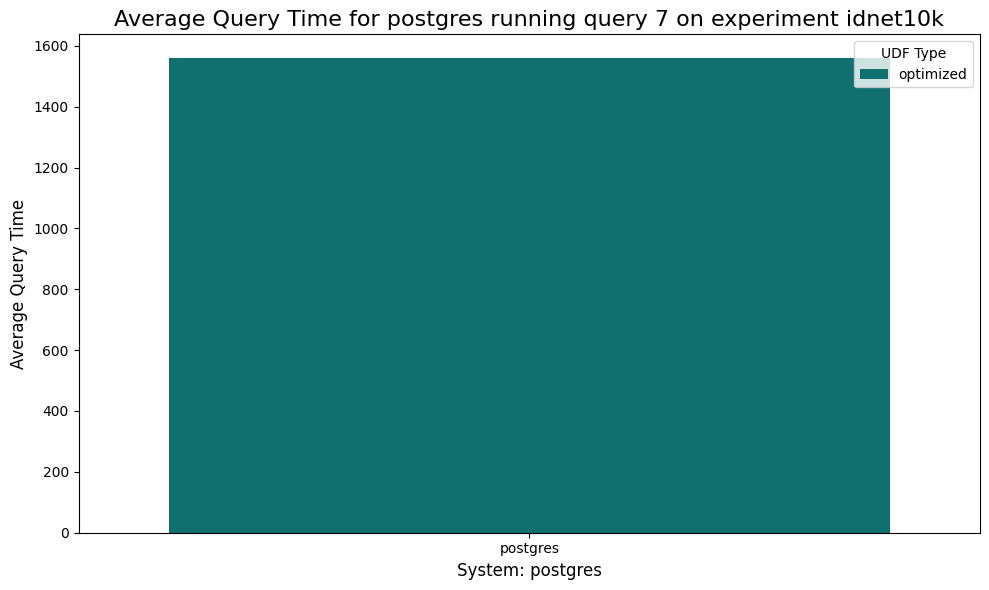

postgres 8 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,8,optimized,587.8,69.12945,82.246497,1681143.4,2008292.8,5146334.0,0.0,0.0,24.074498,6.69574,0.0,0.000434,7.918757,0.0,9.899068,50.139603


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


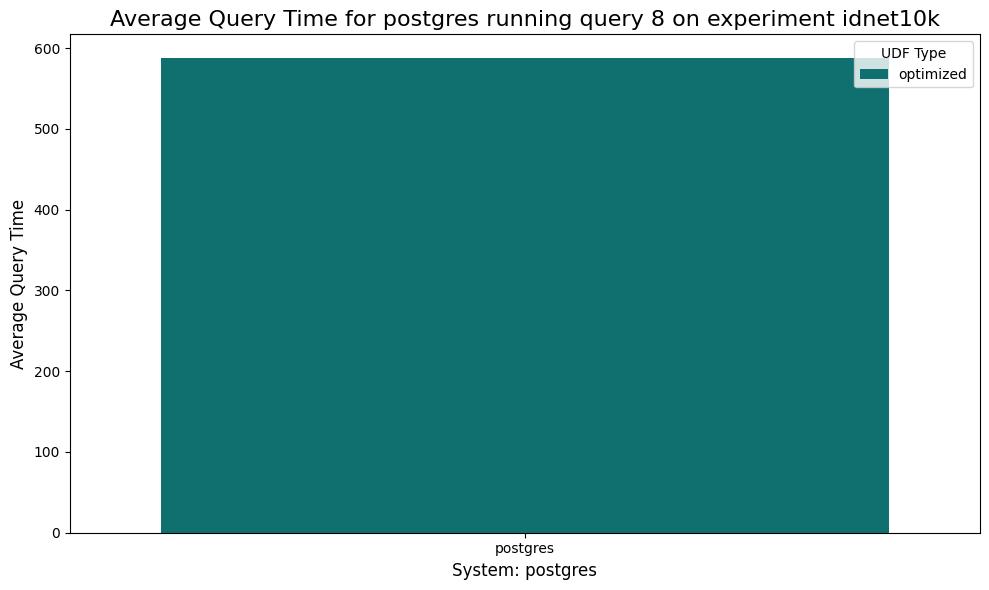

postgres 9 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,9,optimized,346.6,53.017257,82.280012,1175599.0,1046023.0,4108347.6,0.0,0.0,44.216363,2.766273,0.0,0.000177,6.94764,0.0,8.181542,37.858771


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


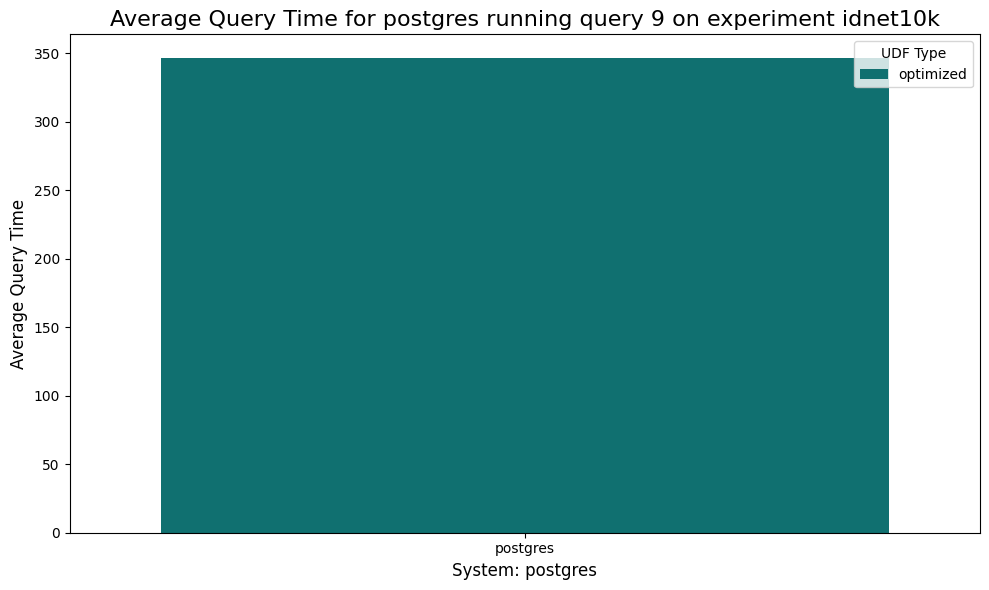

postgres 10 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,10,optimized,663.8,83.452763,81.554713,1809271.2,2349064.4,5056244.0,0.0,0.0,14.744613,1.622617,0.0,0.0,9.221061,0.0,11.00409,61.620923


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


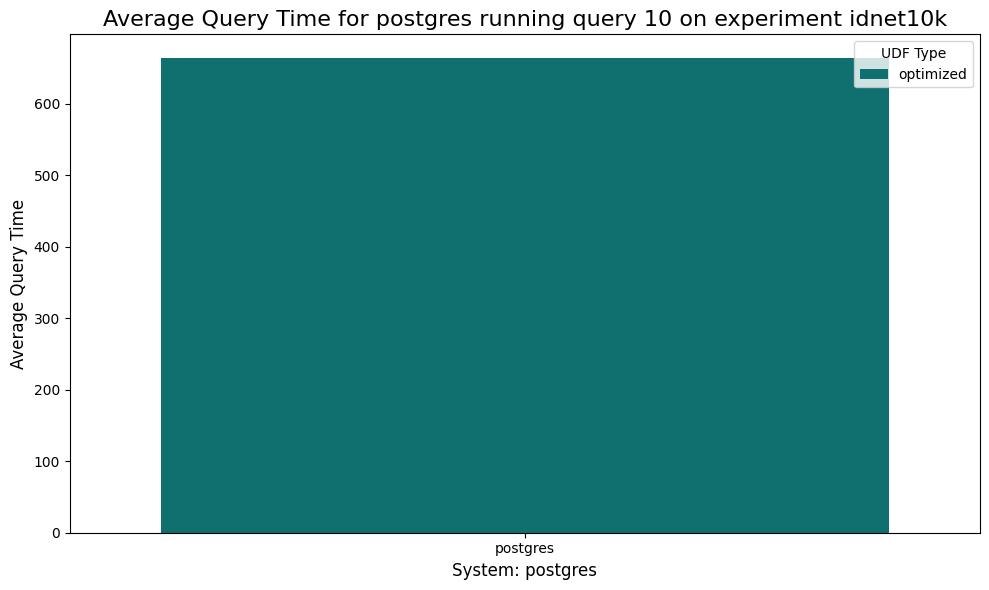

postgres 11 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,11,optimized,1290.4,21.914029,81.446869,3415336.6,2004847.0,1635866.6,0.0,0.0,71.677446,6.406865,0.0,0.000073,2.364379,0.0,2.681359,16.830588


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


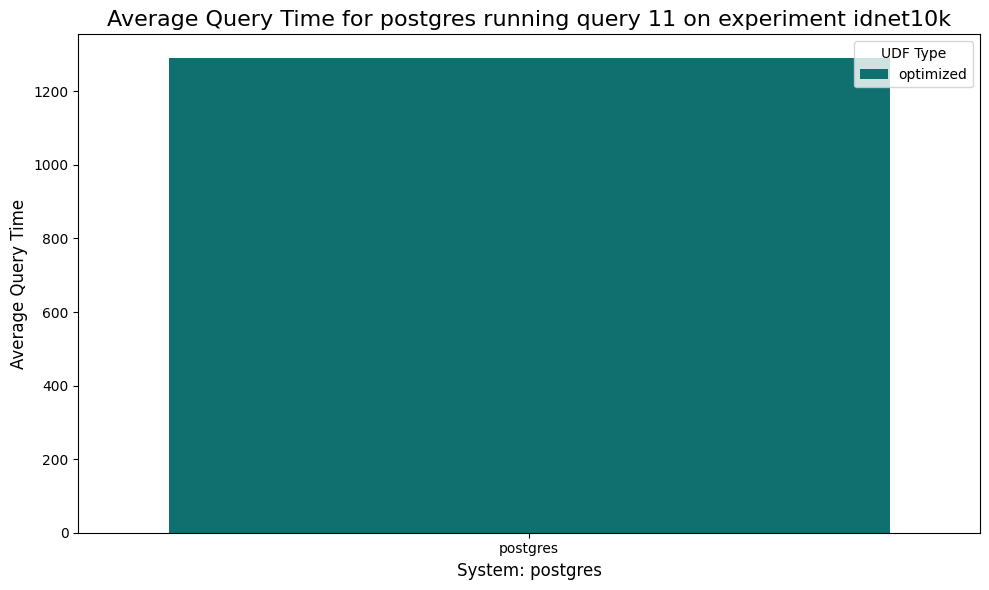

postgres 12 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,12,optimized,508.2,92.406748,80.983751,1183173.6,288443.6,177678.2,0.0,0.0,6.695966,0.803281,0.0,0.000677,7.635715,0.0,11.298171,71.968332


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


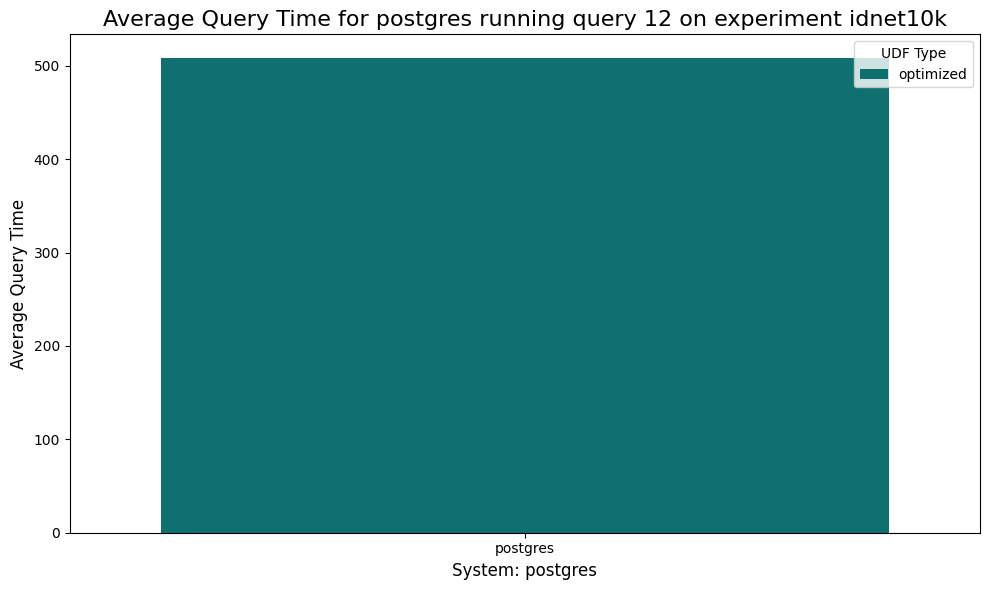

postgres 13 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,13,optimized,1617.8,78.211272,81.324223,4549257.4,2304168.4,6058664.0,0.0,0.0,19.532384,2.248778,0.0,0.000236,10.040787,0.0,10.62848,57.329372


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


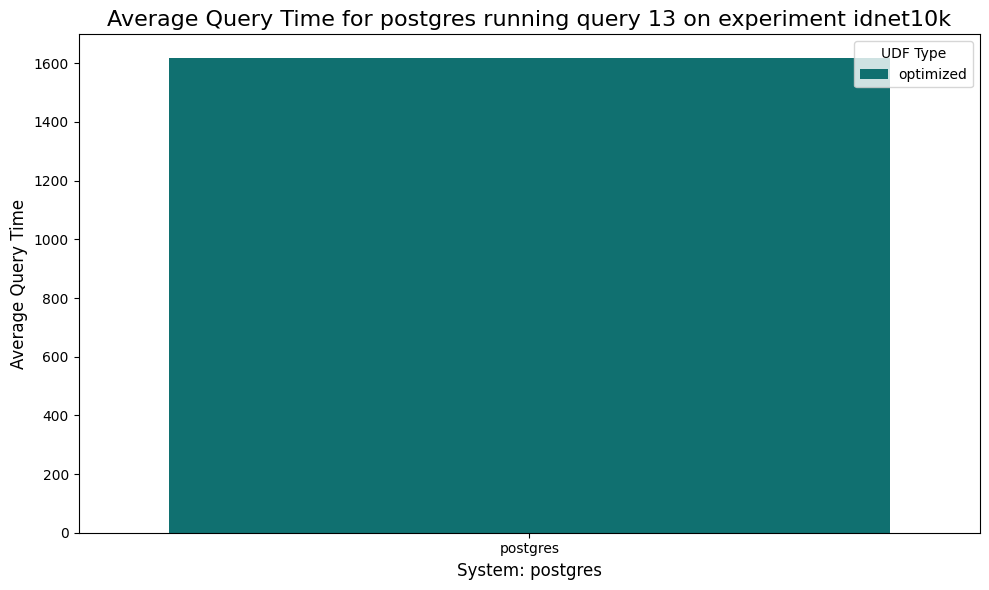

postgres 14 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,14,optimized,614.6,74.991383,81.682601,1643197.2,745635.0,4872154.8,0.0,0.0,22.064942,2.892305,0.0,0.000619,6.552939,0.0,10.004164,57.378041


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


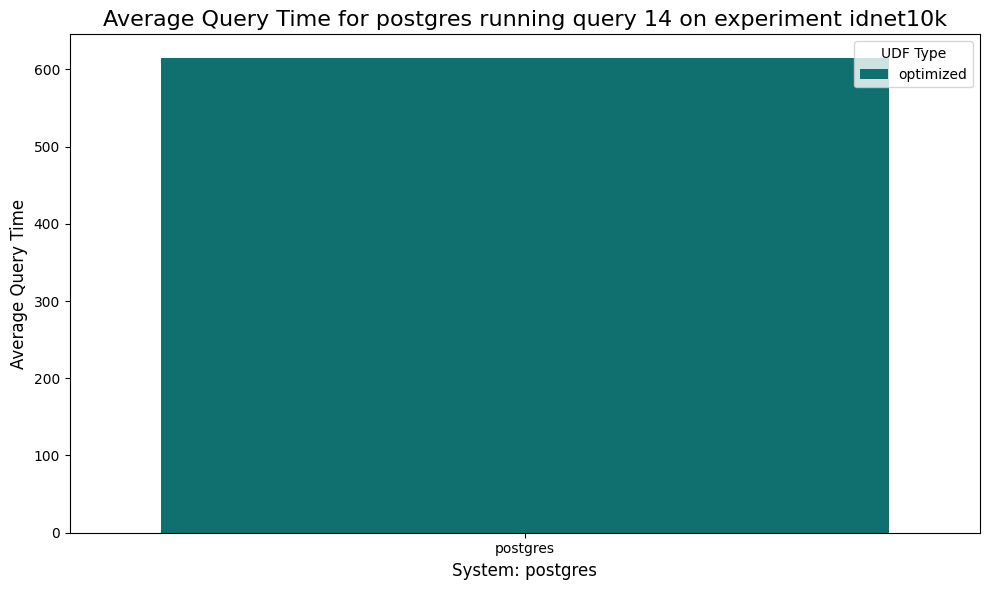

evadb 1 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,1,naive,31.0,58.812761,33.372197,125580.6,88788.8,109517.9,0.0,0.0,38.652007,2.531197,0.0,0.0,7.720081,0.0,11.635766,39.455421
1,idnet,evadb,1,optimized,23.6,70.768579,34.026151,85101.4,55967.9,93623.8,0.0,0.0,28.476446,0.338434,0.0,0.0,8.343287,0.0,12.503000,49.920457


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


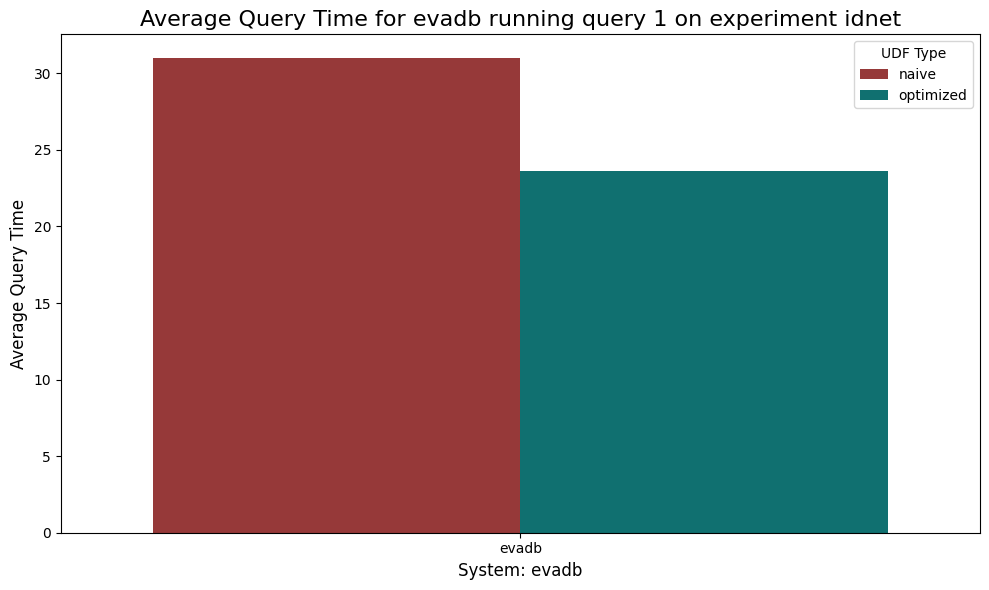

evadb 2 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


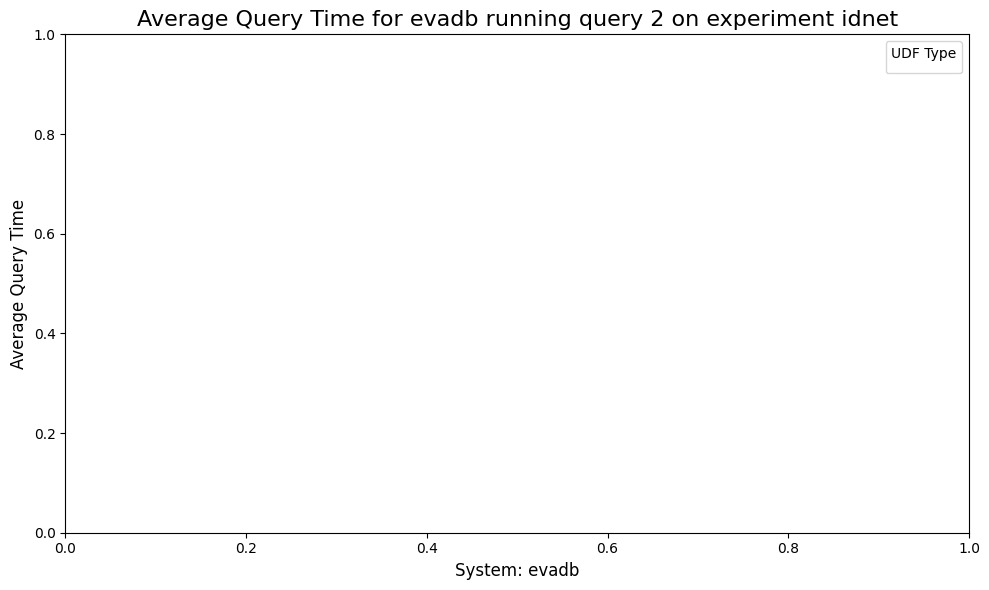

evadb 3 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,3,optimized,2.7,29.768333,34.057500,18089.1,18545.7,73562.6,0.0,0.0,69.956667,0.283333,0.0,0.0,5.292500,0.0,9.224167,15.255000
1,idnet,evadb,3,naive,3.5,30.630500,33.928667,21882.2,22849.4,78733.6,0.0,0.0,67.899167,1.464167,0.0,0.0,4.700333,0.0,9.275333,16.667833


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


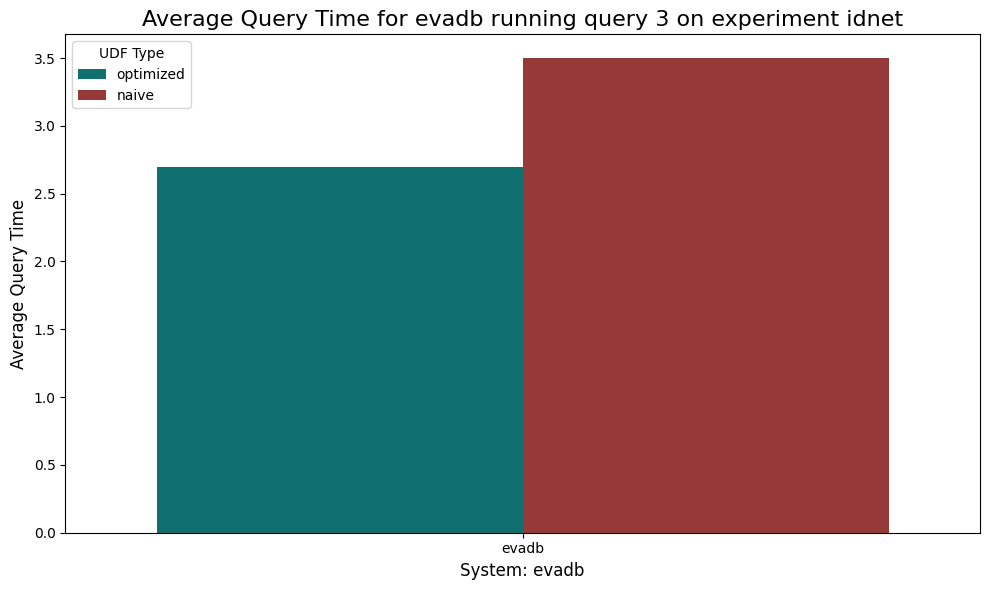

evadb 4 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


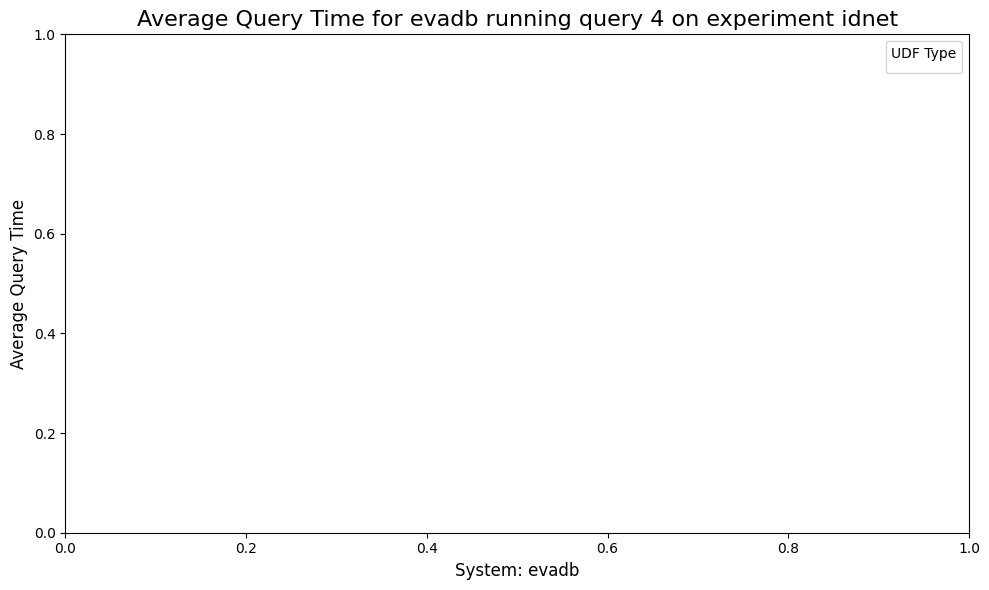

evadb 5 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


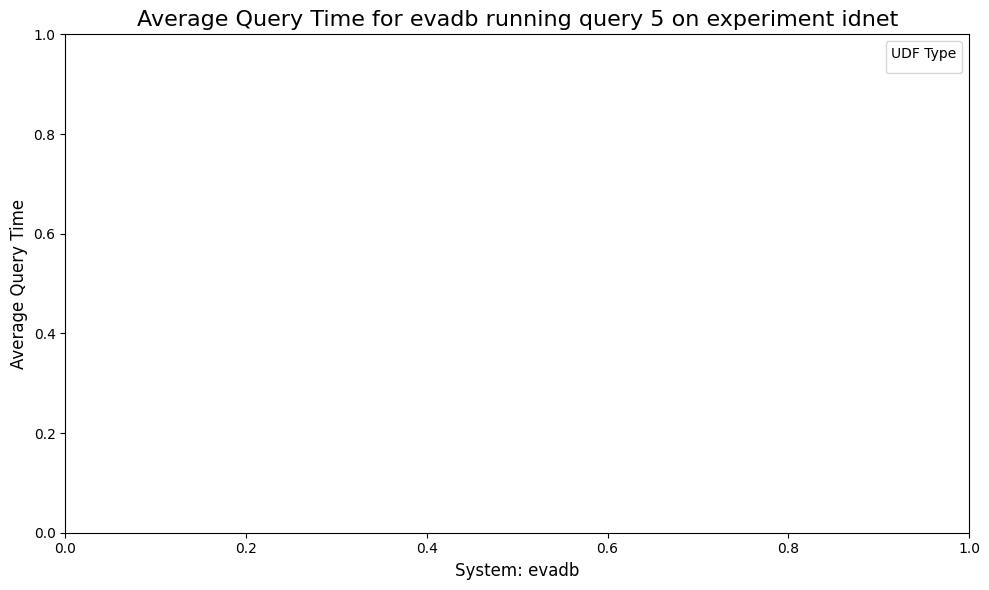

evadb 6 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,6,optimized,3.4,27.033167,12.509333,22616.6,24278.0,75961.6,0.0,0.0,72.896333,0.077667,0.0,0.0,4.718333,0.0,10.306333,12.0125
1,idnet,evadb,6,naive,4.7,26.032542,12.191708,32483.6,32799.0,82639.8,0.0,0.0,72.232083,1.115583,0.0,0.0,4.570083,0.0,10.637250,10.8180


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


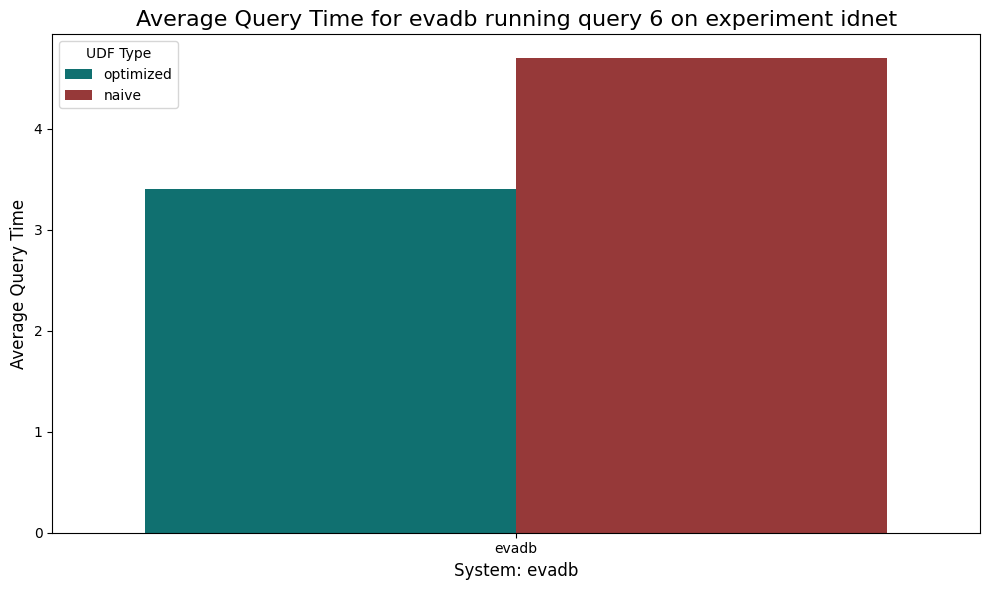

evadb 7 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,7,naive,3.0,27.533333,11.887500,20471.7,21779.3,75687.9,0.0,0.0,72.240833,0.223333,0.0,0.0,4.476667,0.0,11.121667,11.939167
1,idnet,evadb,7,optimized,3.0,25.700833,11.826667,20389.5,21654.6,76451.7,0.0,0.0,74.152500,0.140000,0.0,0.0,4.969167,0.0,10.242500,10.492500


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


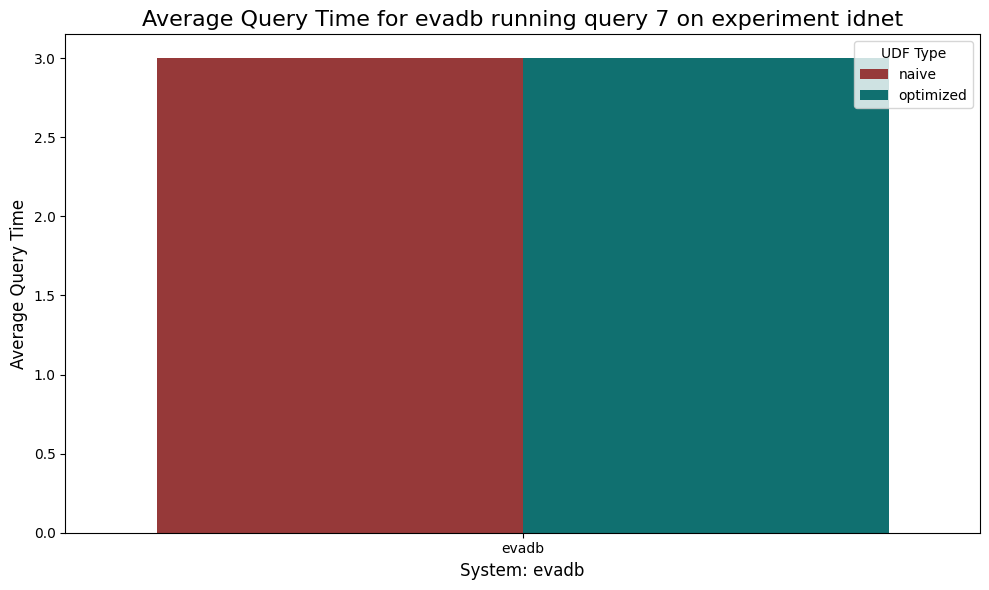

evadb 8 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,8,optimized,3.3,25.519167,11.795833,21844.2,22413.1,79859.1,0.0,0.0,74.408333,0.0750,0.0,0.0,4.931667,0.0,9.966667,10.608333
1,idnet,evadb,8,naive,2.8,28.870000,11.637500,20037.2,21514.6,74876.3,0.0,0.0,70.723333,0.4075,0.0,0.0,5.045000,0.0,11.471667,12.360000


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


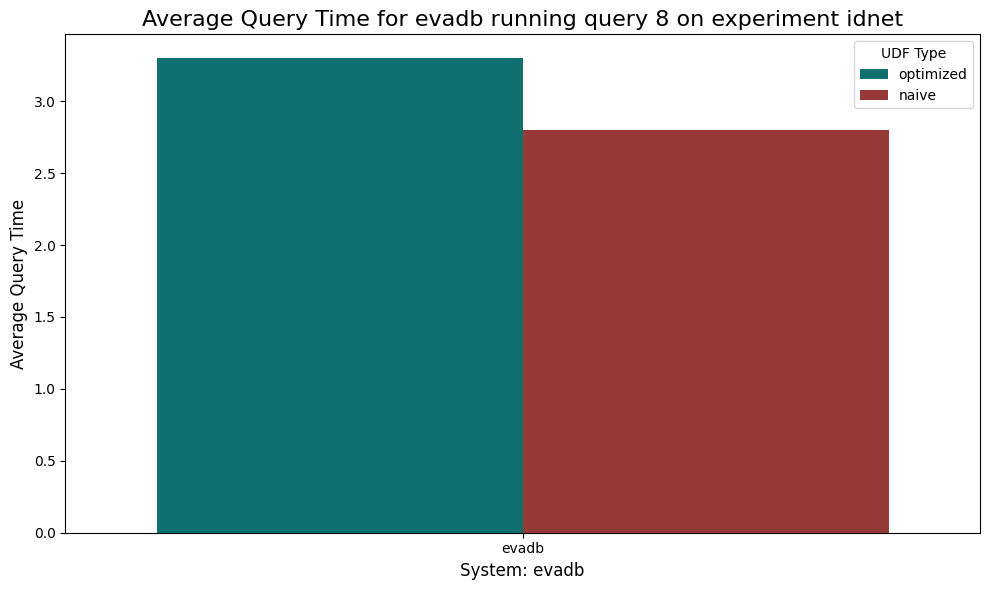

evadb 9 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,9,optimized,29.9,66.839792,13.942615,123954.8,90022.4,109846.4,0.0,0.0,33.098934,0.060695,0.0,0.0,7.836805,0.0,20.382528,38.615517
1,idnet,evadb,9,naive,30.4,66.110223,13.815237,123661.8,88149.2,110042.4,0.0,0.0,33.761048,0.126977,0.0,0.0,7.791377,0.0,20.647639,37.673808


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


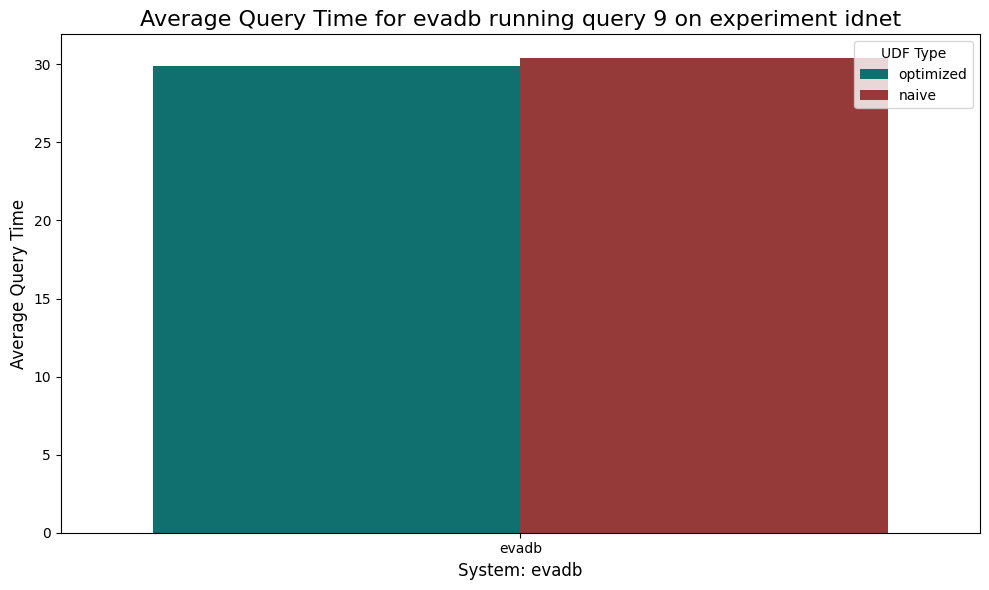

evadb 10 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,10,optimized,4.1,35.193,13.114,25501.0,28819.8,82725.7,0.0,0.0,64.6555,0.1565,0.0,0.0,5.713,0.0,11.7255,17.7445
1,idnet,evadb,10,naive,3.4,29.865,13.520,22272.3,23055.3,81662.2,0.0,0.0,70.0050,0.1375,0.0,0.0,4.940,0.0,11.0475,13.8900


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


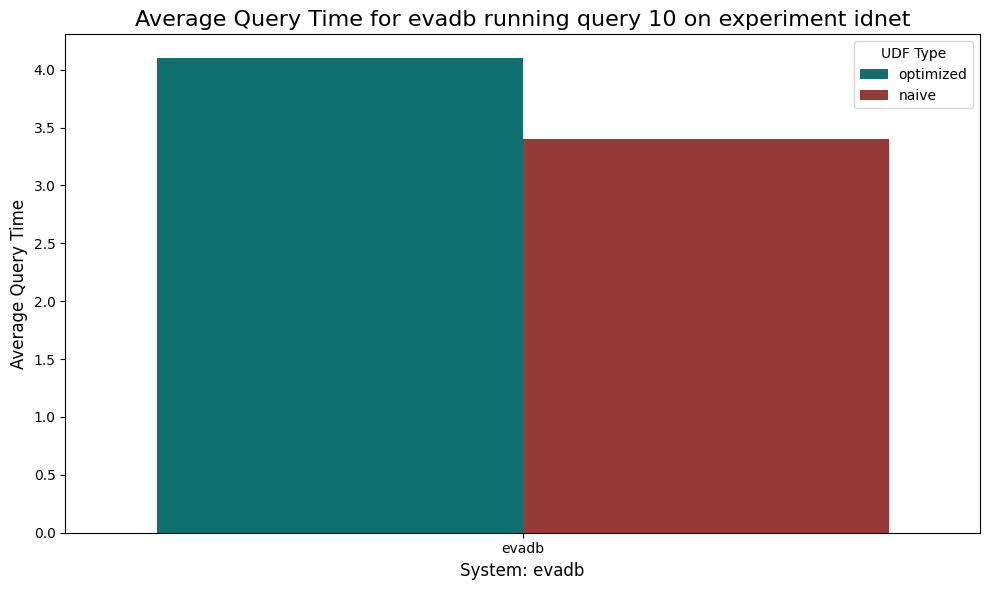

evadb 11 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


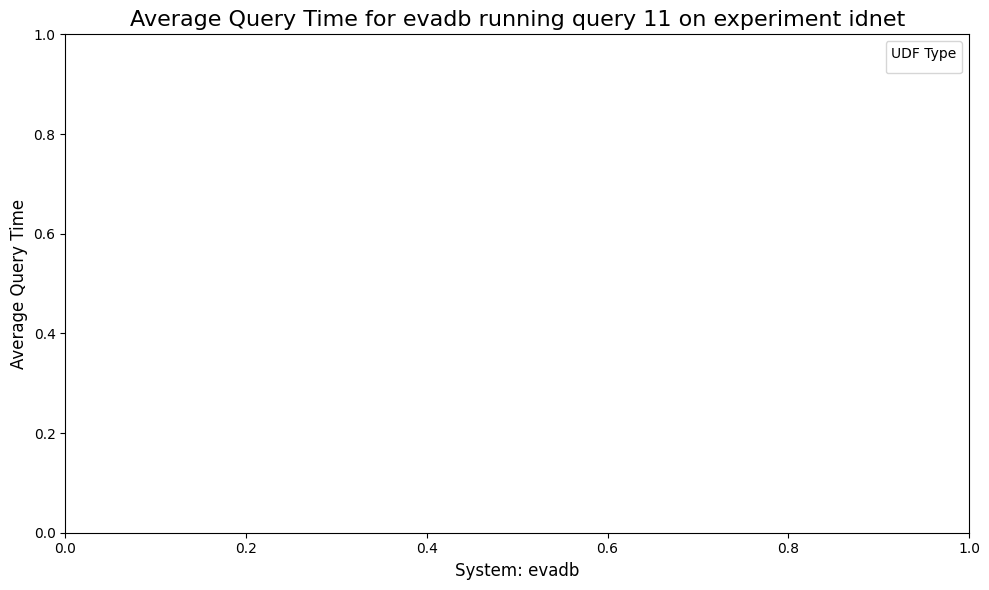

evadb 12 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


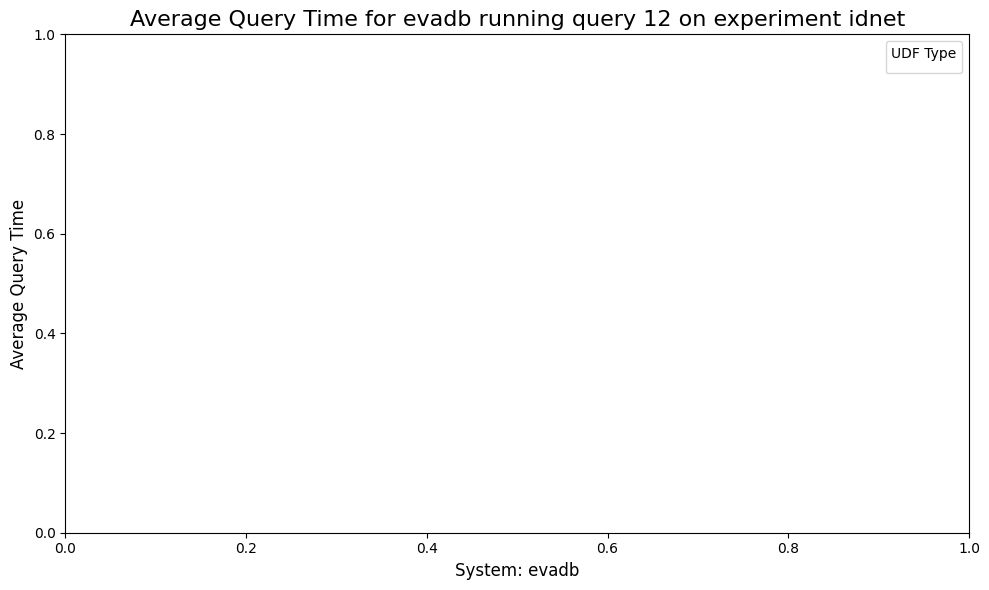

evadb 13 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


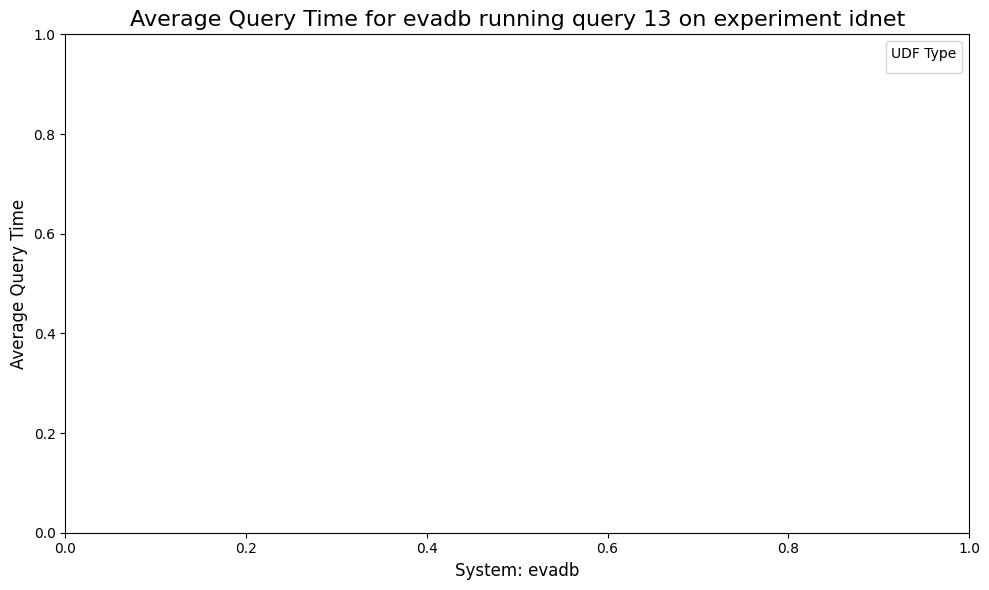

evadb 14 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


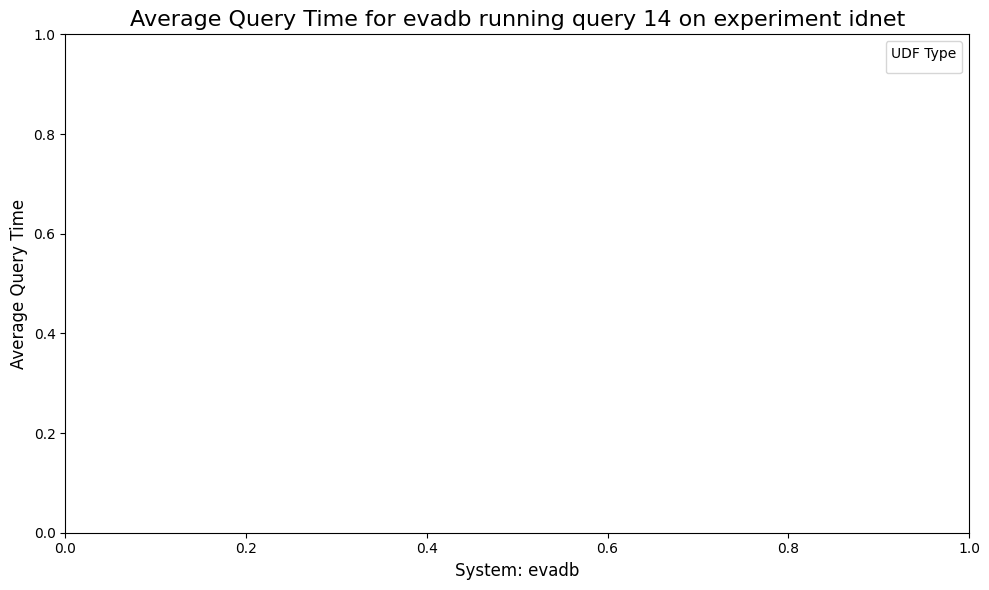

evadb 1 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,1,optimized,225.7,73.335090,32.312614,759210.3,470722.0,927829.9,0.0,0.0,26.364400,0.299526,0.0,0.001268,9.788604,0.0,12.996197,50.546404
1,idnet10k,evadb,1,naive,309.7,56.236399,28.878343,1255652.3,890679.9,1119018.9,0.0,0.0,39.576944,4.186776,0.0,0.027696,8.129777,0.0,11.021963,37.051038


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


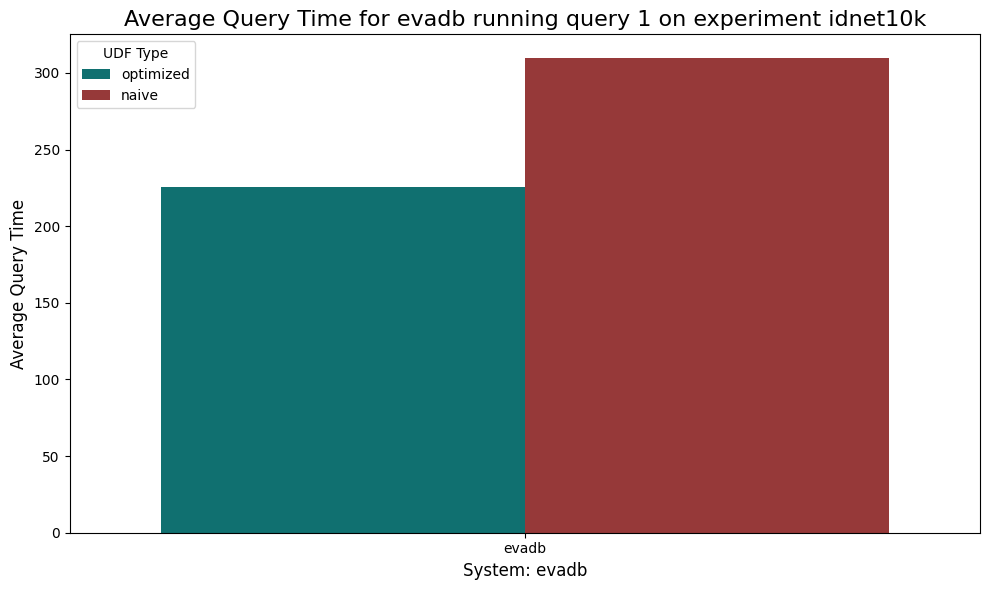

evadb 2 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


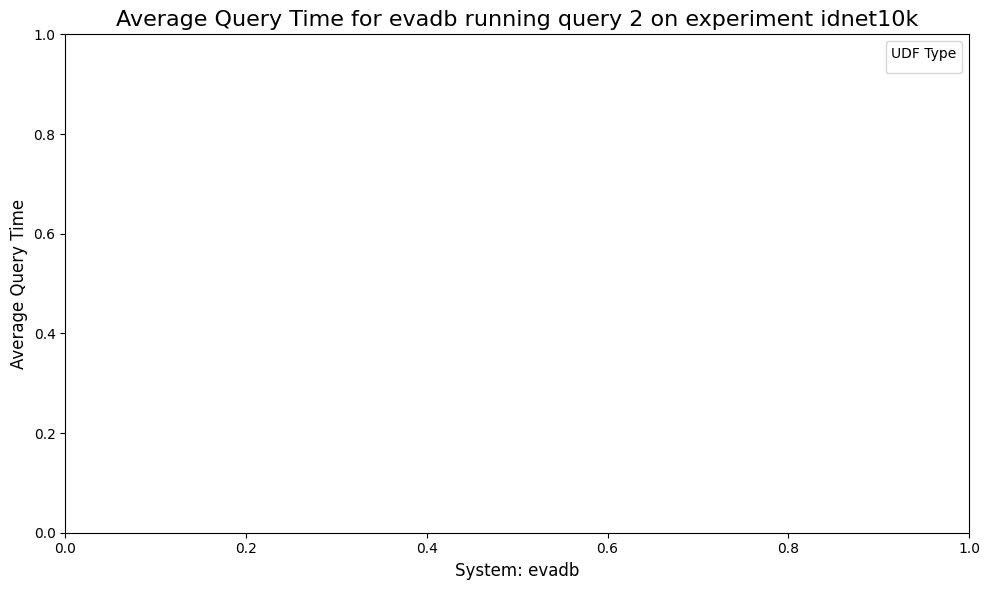

evadb 3 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,3,optimized,27.9,32.106559,27.094611,175765.2,185830.5,817920.0,0.0,0.0,67.478676,0.417269,0.0,0.0,6.240763,0.0,11.710122,14.150914
1,idnet10k,evadb,3,naive,27.8,32.777265,27.014956,177920.5,182446.1,814924.7,0.0,0.0,66.500350,0.724370,0.0,0.0,5.577449,0.0,12.490872,14.711881


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


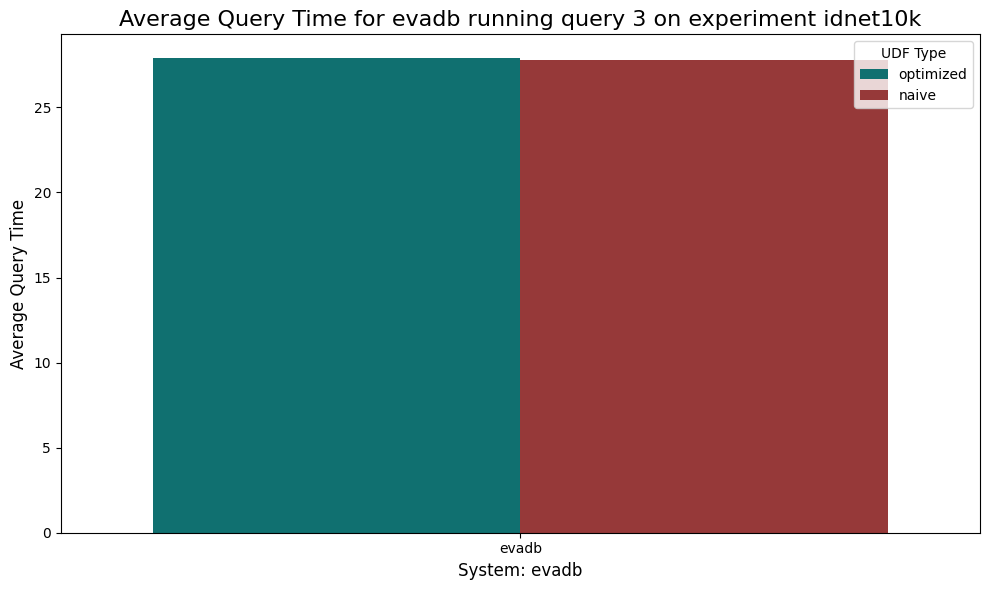

evadb 4 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


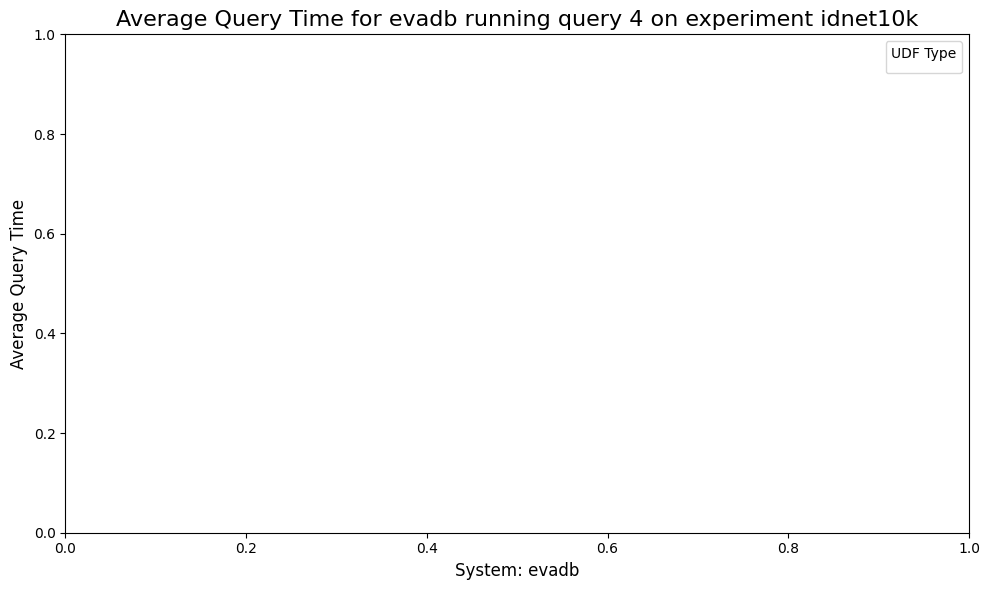

evadb 5 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


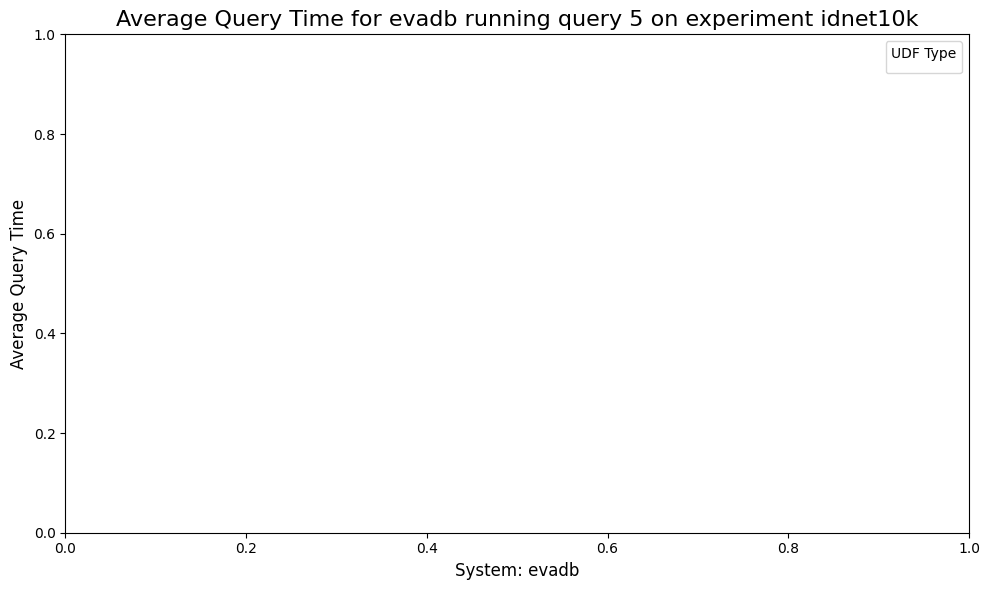

evadb 6 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,6,optimized,30.5,24.206667,17.175594,163933.1,174380.2,819153.2,0.0,0.0,74.491667,1.186663,0.0,0.0,5.390688,0.0,10.826154,7.986451
1,idnet10k,evadb,6,naive,51.2,30.802426,16.597412,362004.4,369174.2,855539.8,0.0,0.0,66.930026,1.251600,0.0,0.0,7.071532,0.0,14.226235,9.508095


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


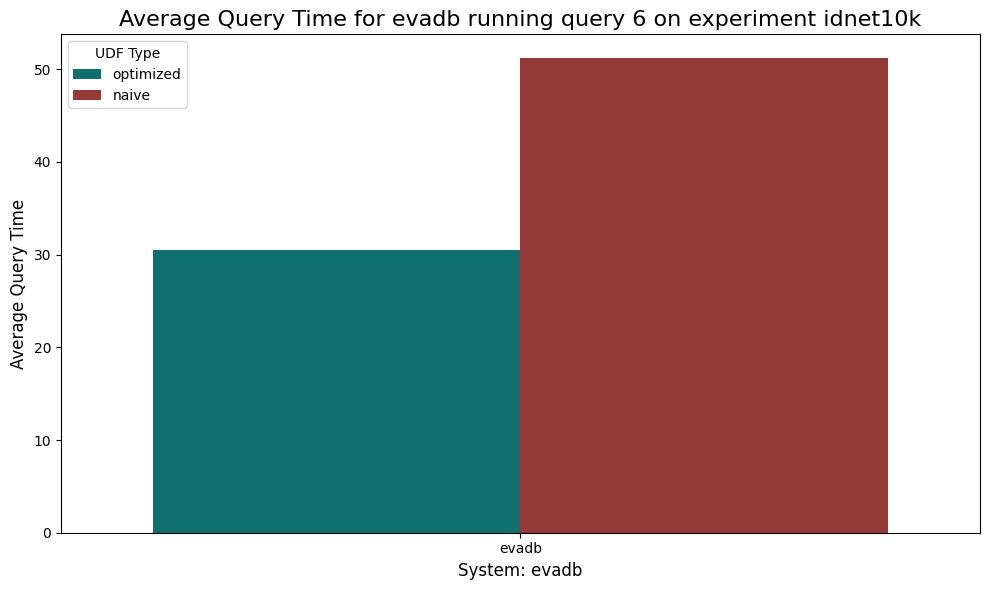

evadb 7 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,7,naive,26.8,31.151700,18.287194,196899.0,220277.6,803363.4,0.0,0.0,68.696324,0.152806,0.0,0.0,6.283874,0.0,14.134585,10.737708
1,idnet10k,evadb,7,optimized,24.2,25.755348,17.727527,143268.9,163836.5,799630.1,0.0,0.0,73.866978,0.379697,0.0,0.0,6.212288,0.0,11.122126,8.423558


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


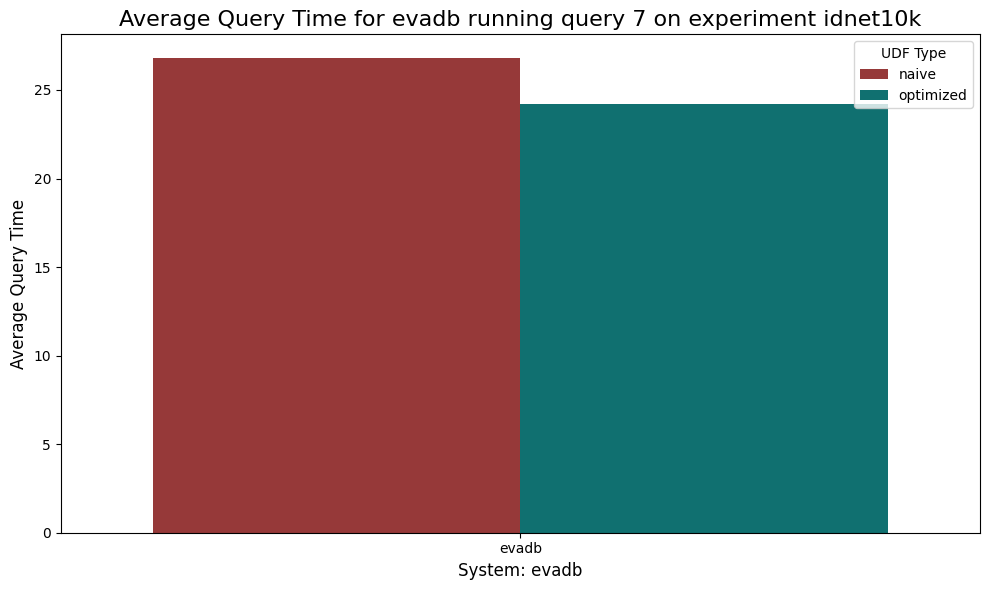

evadb 8 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,8,optimized,23.8,25.612052,17.884807,141428.6,156966.1,814128.7,0.0,0.0,74.166668,0.225092,0.0,0.0,5.753257,0.0,11.434952,8.423891
1,idnet10k,evadb,8,naive,27.2,30.448300,18.438775,196583.2,225379.2,803070.8,0.0,0.0,69.419723,0.131067,0.0,0.0,6.784822,0.0,13.443083,10.227273


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


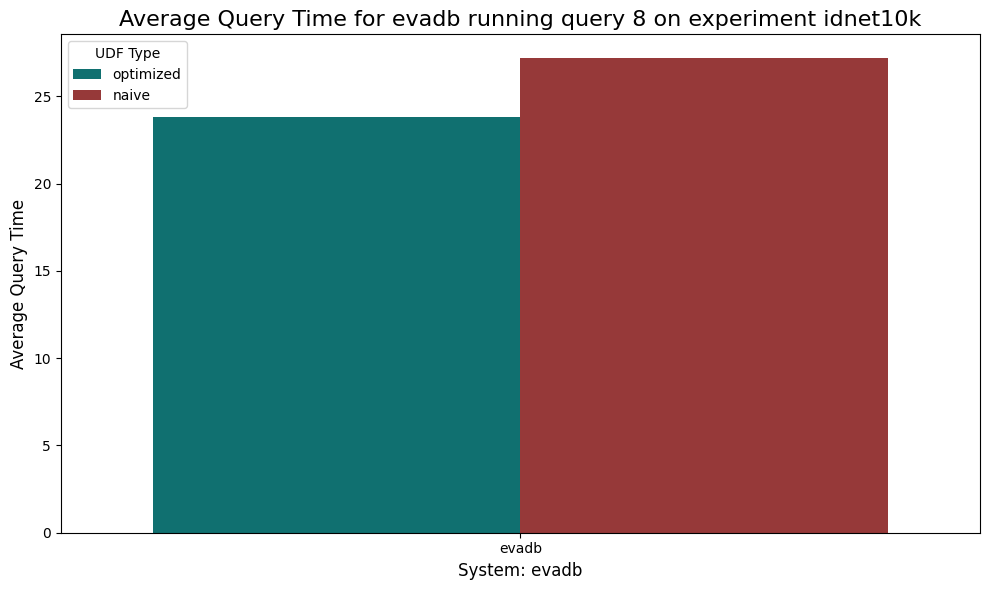

evadb 9 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,9,naive,233.6,76.593044,24.799025,872147.0,705983.6,950579.4,0.0,0.0,23.290410,0.116246,0.0,0.000000,8.315670,0.0,20.798535,47.480150
1,idnet10k,evadb,9,optimized,215.7,72.512923,23.839042,652037.3,467418.3,922305.2,0.0,0.0,27.261758,0.116694,0.0,0.000733,7.789171,0.0,14.550751,49.949814


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


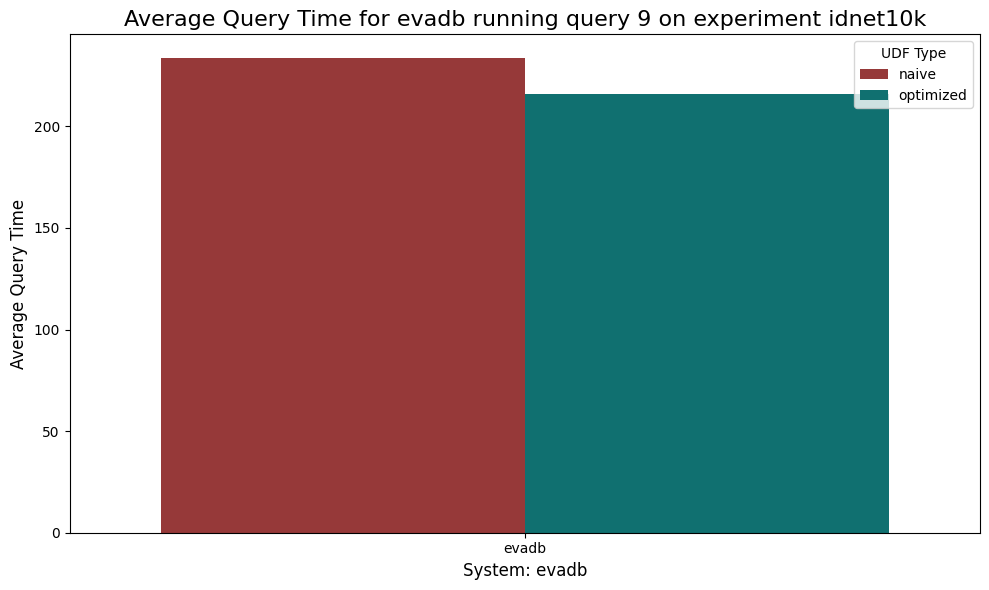

evadb 10 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,10,naive,27.2,31.483152,18.292645,200141.8,224399.2,807480.4,0.0,0.0,68.404928,0.116232,0.0,0.0,7.171196,0.0,13.479638,10.829674
1,idnet10k,evadb,10,optimized,23.9,25.920936,17.304016,140989.3,159237.6,805532.1,0.0,0.0,73.934807,0.147524,0.0,0.0,5.414342,0.0,11.589408,8.915694


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


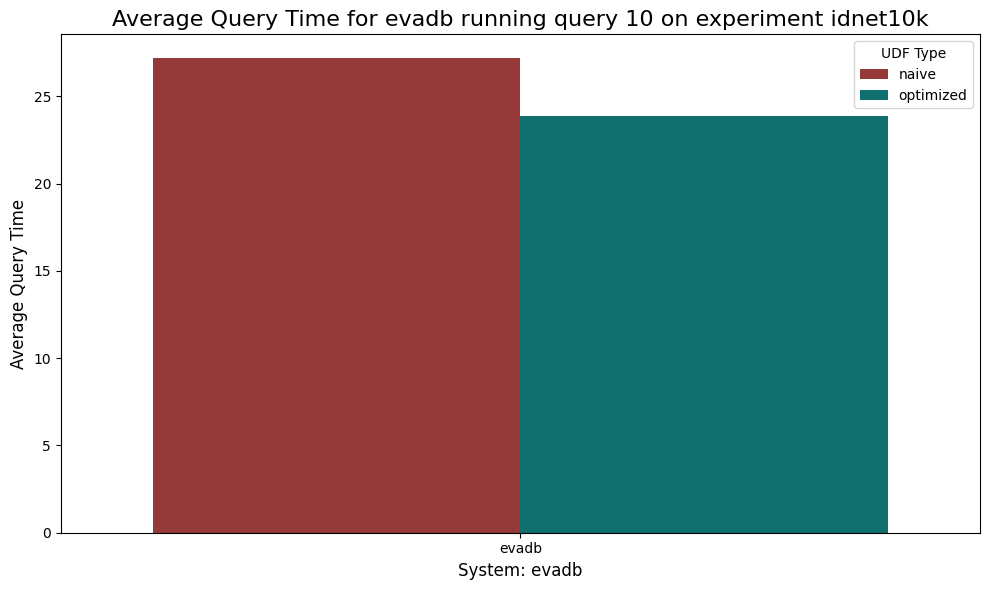

evadb 11 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


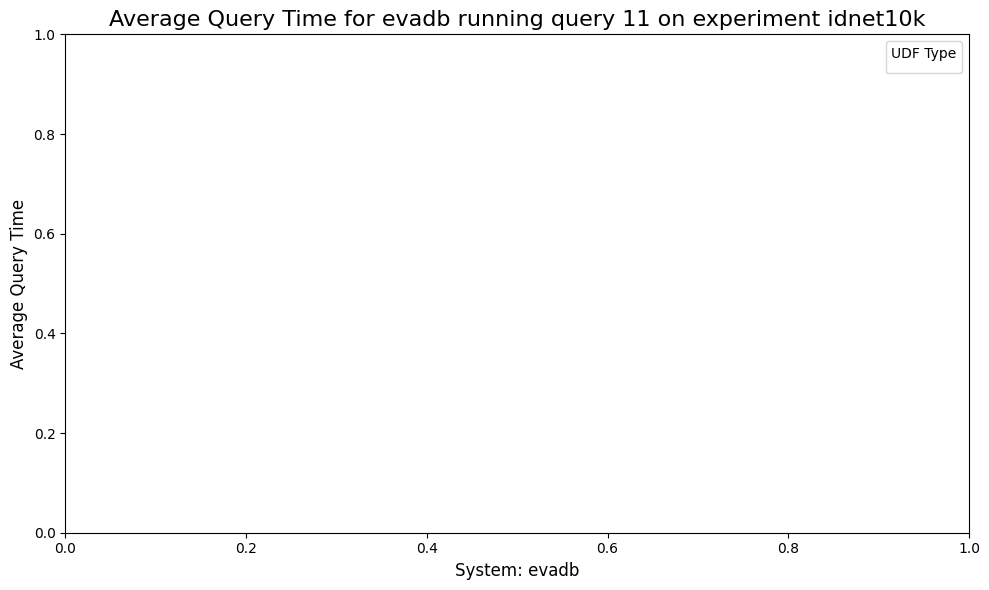

evadb 12 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


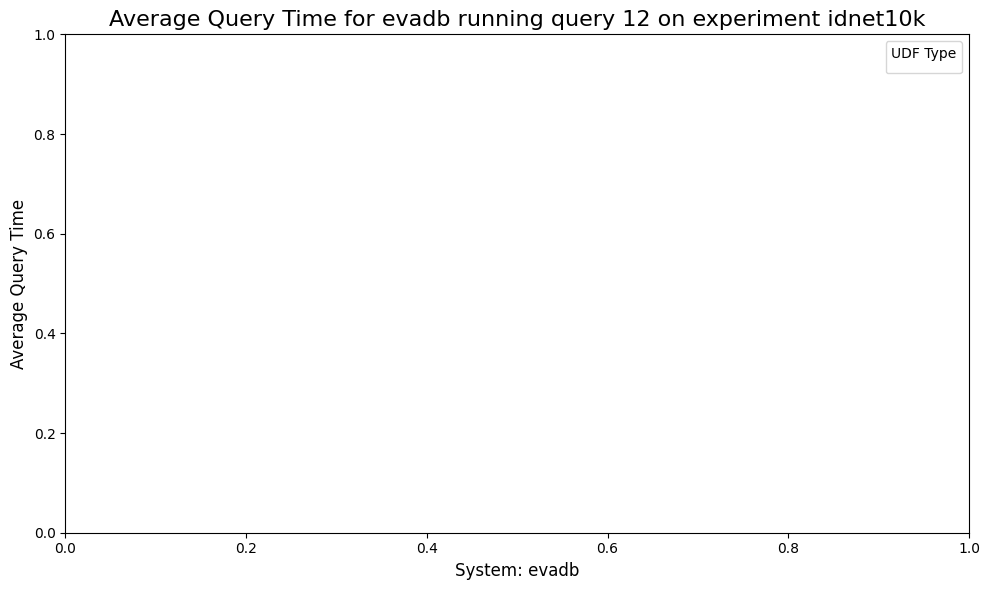

evadb 13 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


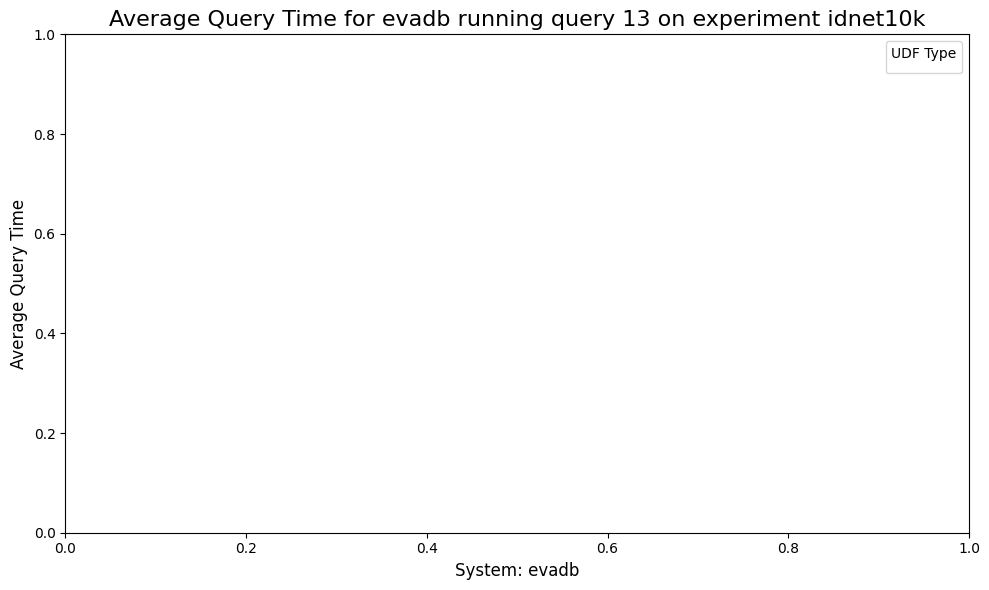

evadb 14 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


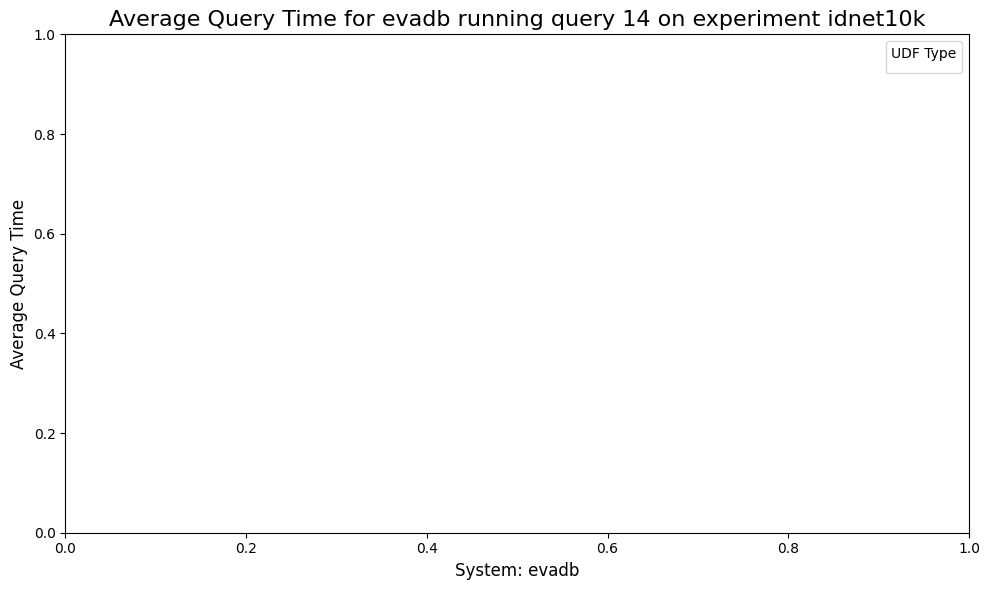

duckdb 1 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,1,optimized,37.4,55.134162,42.018182,174891.9,149000.6,42984.0,0.0,0.0,44.788349,0.076226,0.0,0.001111,5.079852,0.0,20.492992,29.518077
1,idnet,duckdb,1,naive,103.3,51.842317,31.736423,612568.8,732064.4,161562.3,0.0,0.0,48.011622,0.113546,0.0,0.000000,4.406929,0.0,11.236696,36.202304


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


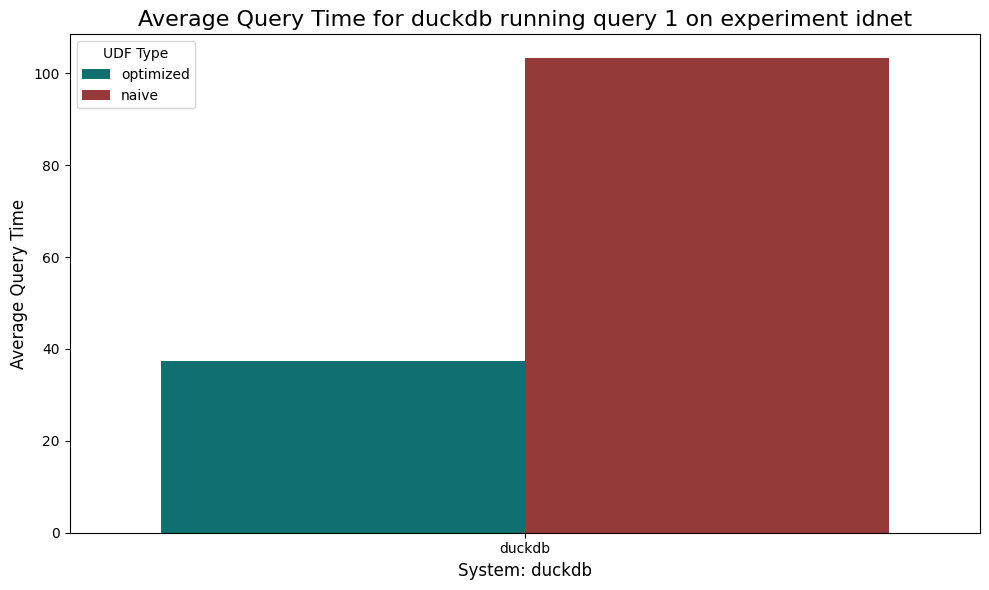

duckdb 2 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,2,naive,113.0,48.939201,31.484663,756789.2,968238.0,199438.9,0.0,0.0,50.913964,0.148003,0.0,0.003636,3.542638,0.0,11.417025,33.979039
1,idnet,duckdb,2,optimized,42.2,46.901022,42.459541,240641.0,248804.6,63384.9,0.0,0.0,52.990216,0.106177,0.0,0.000000,3.229156,0.0,18.439394,25.213022


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


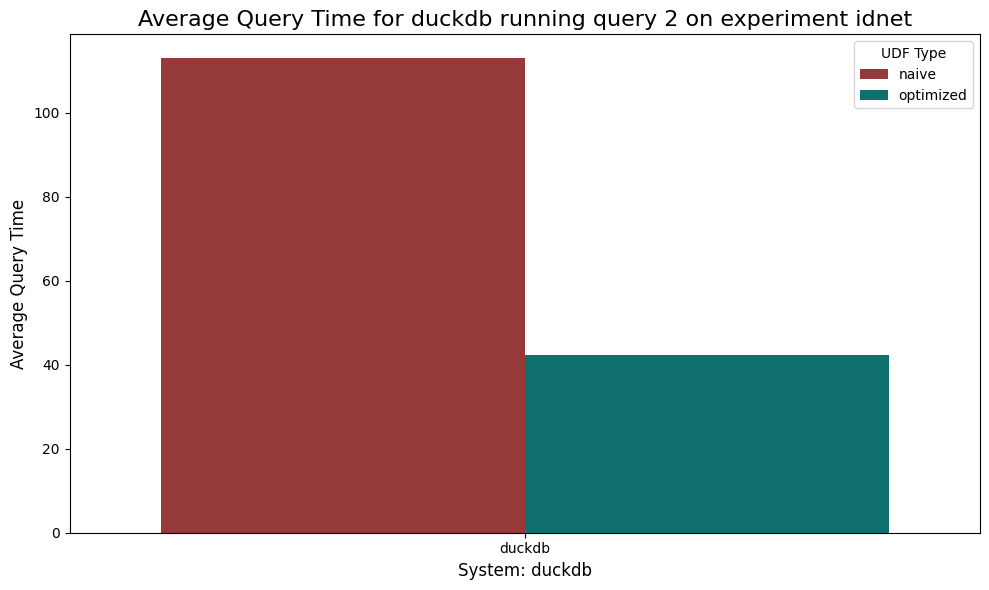

duckdb 3 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,3,optimized,0.0,14.570000,32.920000,0.0,0.0,0.0,0.0,0.0,85.200000,0.250000,0.0,0.0,1.720000,0.0,9.290000,3.550000
1,idnet,duckdb,3,naive,13.8,50.816456,29.873564,95463.8,121719.0,22726.8,0.0,0.0,49.094473,0.089423,0.0,0.0,4.330855,0.0,12.227029,34.255406


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


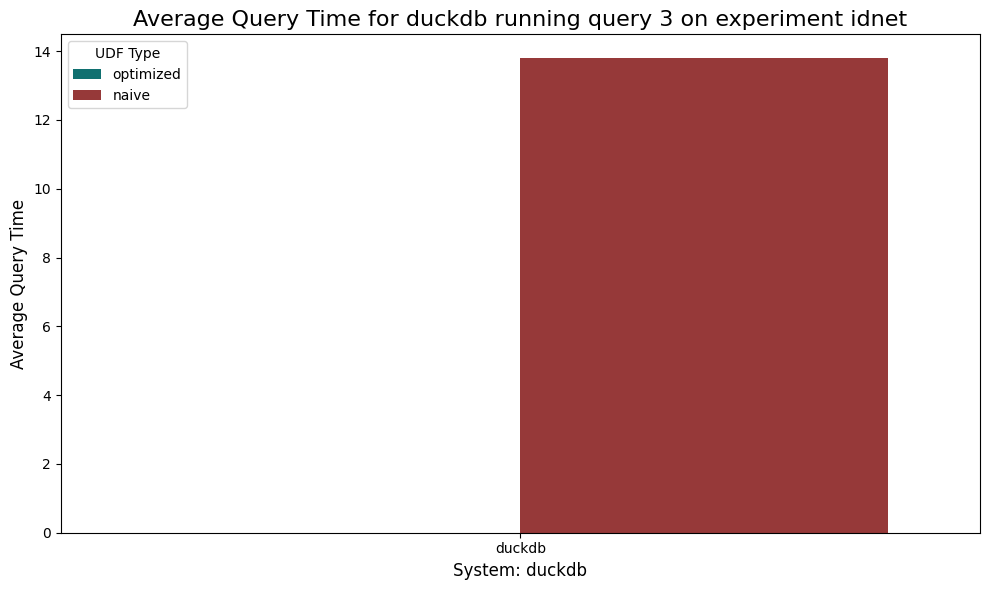

duckdb 4 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,4,optimized,0.0,9.900000,32.790000,0.0,0.0,0.0,0.0,0.0,89.990000,0.11000,0.0,0.0,1.770000,0.0,3.460000,4.670000
1,idnet,duckdb,4,naive,12.7,57.002196,29.863408,85091.0,105354.3,20143.1,0.0,0.0,42.884744,0.08746,0.0,0.0,5.454568,0.0,12.885345,38.373547


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


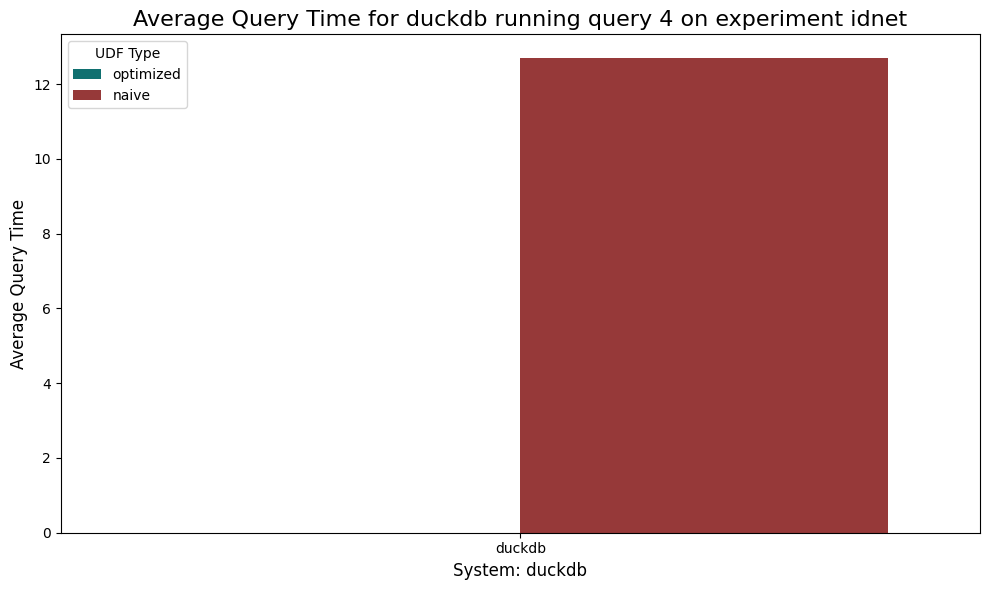

duckdb 5 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,5,optimized,41.5,48.240271,42.755741,228942.5,231160.7,60143.1,0.0,0.0,51.632727,0.125662,0.0,0.0,3.729992,0.0,18.481978,26.025337
1,idnet,duckdb,5,naive,77.8,48.649897,31.450863,552978.1,734969.6,149227.4,0.0,0.0,51.223932,0.128146,0.0,0.0,3.873331,0.0,10.948105,33.831914


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


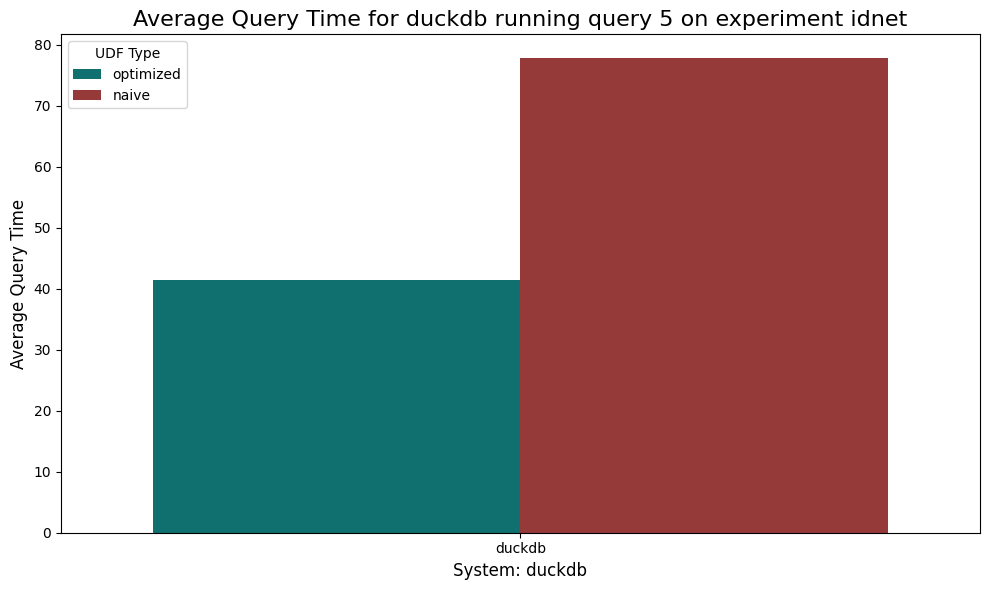

duckdb 6 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,6,optimized,261.0,50.470818,55.123665,1461252.8,1476575.6,377656.6,0.0,0.0,48.019249,1.510397,0.0,0.000000,3.812329,0.0,19.442634,27.184027
1,idnet,duckdb,6,naive,776.1,37.729594,33.165073,6947693.0,10198319.8,1810090.4,0.0,0.0,62.106644,0.166558,0.0,0.018364,1.203544,0.0,10.608272,25.902770


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


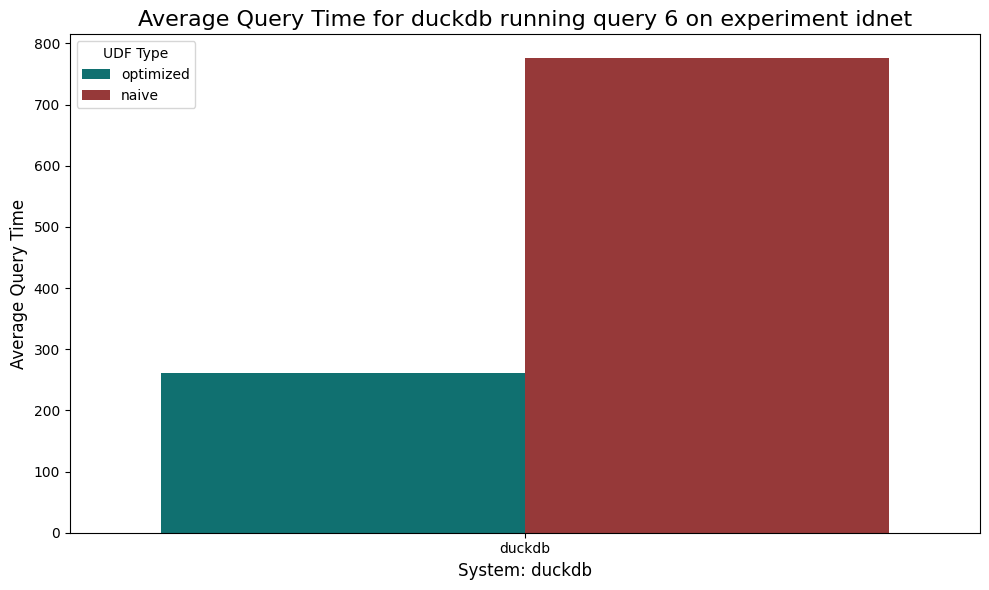

duckdb 7 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,7,naive,624.5,41.122423,31.876134,5452050.9,7982112.4,1430669.2,0.0,0.0,58.736456,0.144074,0.0,0.013966,1.773475,0.0,10.784942,28.553811
1,idnet,duckdb,7,optimized,263.9,48.834632,54.151965,1531970.0,1591938.8,397433.8,0.0,0.0,50.716746,0.449857,0.0,0.000000,3.486407,0.0,18.845082,26.491883


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


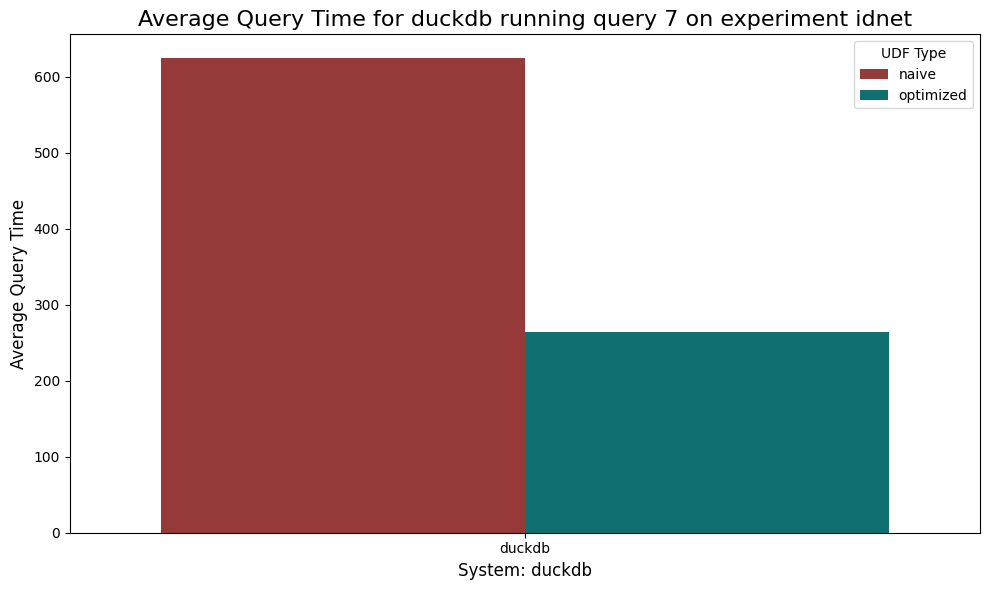

duckdb 8 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,8,naive,116.1,34.250692,31.474405,941902.9,1274700.8,236956.4,0.0,0.0,65.595500,0.149686,0.0,0.155287,2.119067,0.0,9.614276,22.363320
1,idnet,duckdb,8,optimized,4.8,25.898143,34.092857,27736.1,23486.0,7969.5,0.0,0.0,72.843286,1.255571,0.0,0.000000,1.862857,0.0,13.975714,10.060571


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


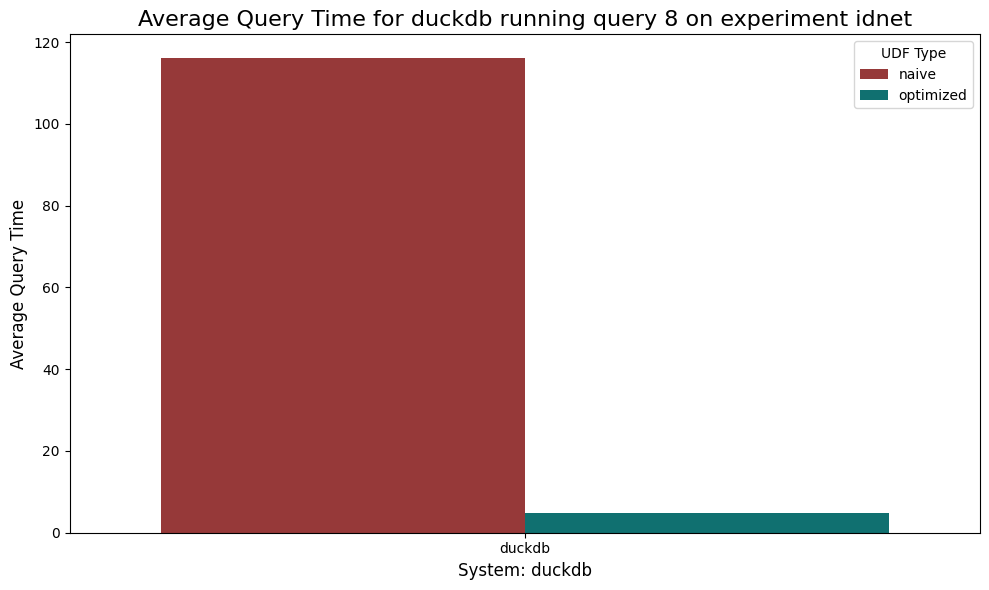

duckdb 9 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,9,optimized,40.8,51.765835,42.168022,202578.2,181869.9,51588.2,0.0,0.0,48.127185,0.108412,0.0,0.000000,4.346576,0.0,20.436475,26.985018
1,idnet,duckdb,9,naive,86.7,45.506774,29.488163,643281.0,868495.9,172784.2,0.0,0.0,54.386089,0.109594,0.0,0.000571,3.222671,0.0,11.000567,31.287161


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


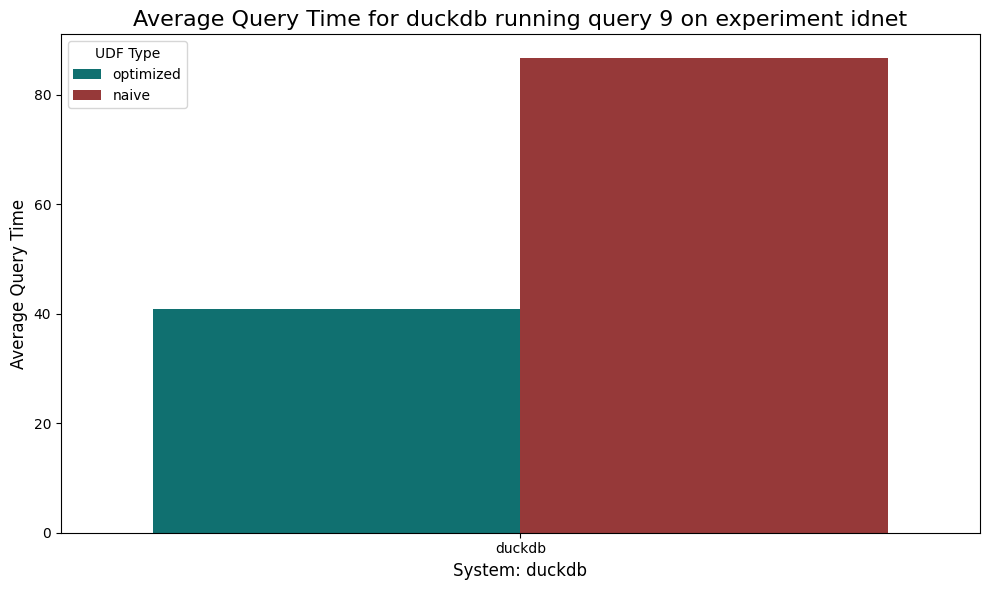

duckdb 10 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,10,naive,120.3,28.092172,31.732535,1014748.4,1399220.8,255147.2,0.0,0.0,71.777794,0.125192,0.0,0.0,1.088499,0.0,8.950629,18.055497
1,idnet,duckdb,10,optimized,3.3,25.680000,34.007500,17711.0,15519.3,4740.3,0.0,0.0,74.172500,0.152500,0.0,0.0,1.735000,0.0,13.435000,10.497500


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


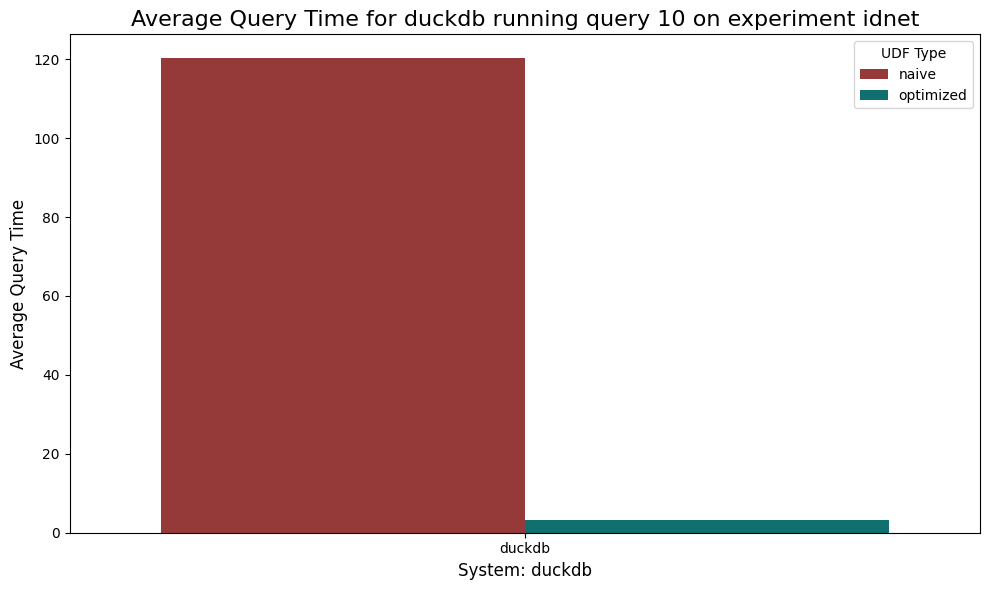

duckdb 11 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,11,naive,648.2,41.042407,30.554925,5566711.6,8079373.1,1465510.5,0.0,0.0,58.834104,0.126959,0.0,0.000000,1.770165,0.0,11.021158,28.253936
1,idnet,duckdb,11,optimized,259.5,49.426571,53.411593,1522054.3,1574438.7,388961.6,0.0,0.0,50.401168,0.173427,0.0,0.000089,3.404083,0.0,19.419354,26.605929


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


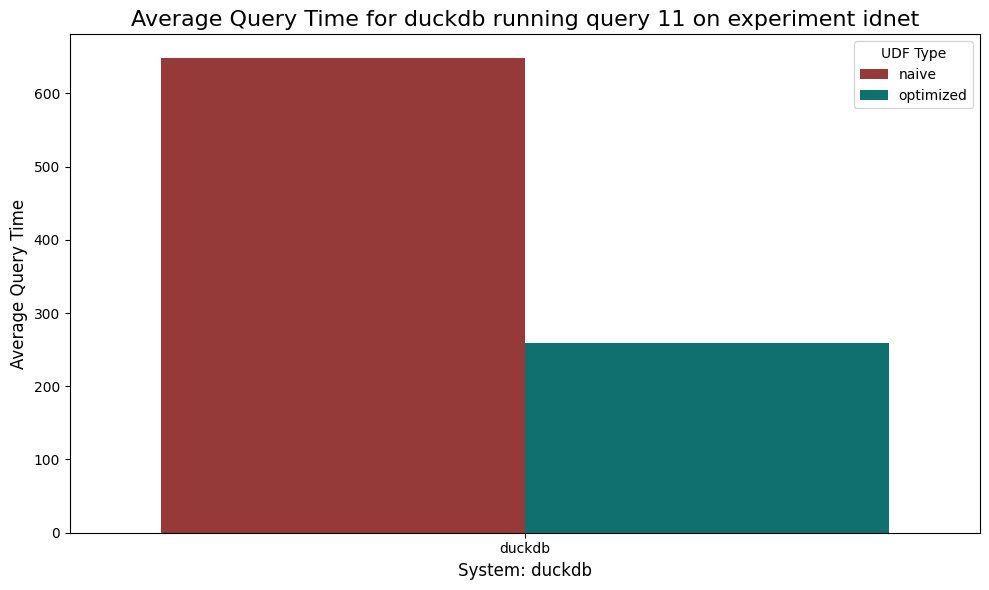

duckdb 12 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,12,optimized,0.0,16.600000,32.060000,0.0,0.0,0.0,0.0,0.0,81.890000,1.52000,0.0,0.0,1.99000,0.0,10.74000,3.850000
1,idnet,duckdb,12,naive,110.1,34.359752,27.740108,908457.7,1245644.7,225650.7,0.0,0.0,65.529811,0.10419,0.0,0.0,1.91522,0.0,9.65547,22.792542


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


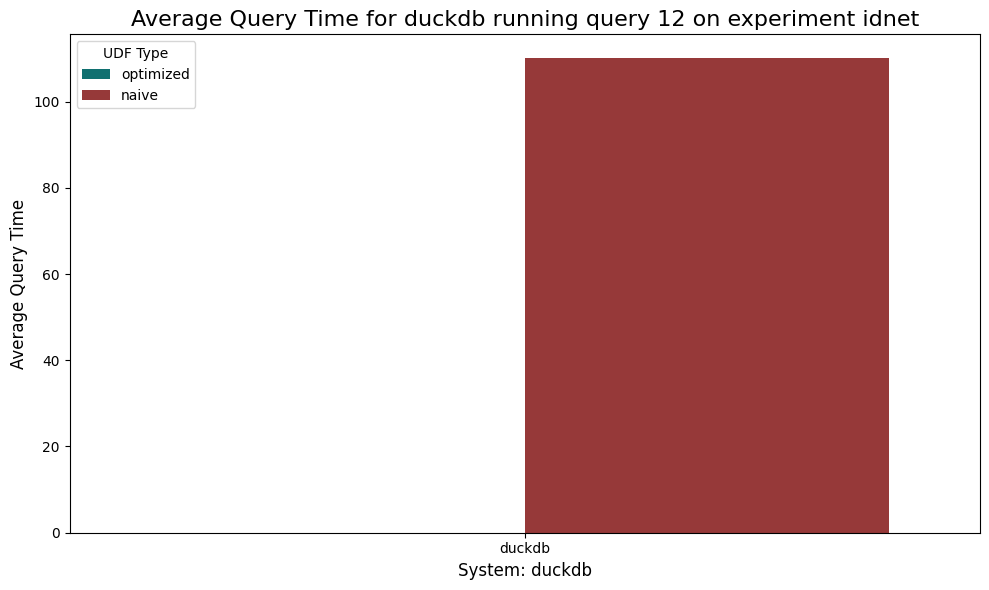

duckdb 13 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,13,optimized,266.1,49.173686,54.037026,1556833.3,1648714.0,407664.0,0.0,0.0,50.506194,0.320915,0.0,0.000000,3.663516,0.0,19.332105,26.161685
1,idnet,duckdb,13,naive,592.6,44.790986,31.597846,4683580.1,6548721.1,1246847.7,0.0,0.0,55.097641,0.114062,0.0,0.000154,2.829064,0.0,11.234933,30.729075


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


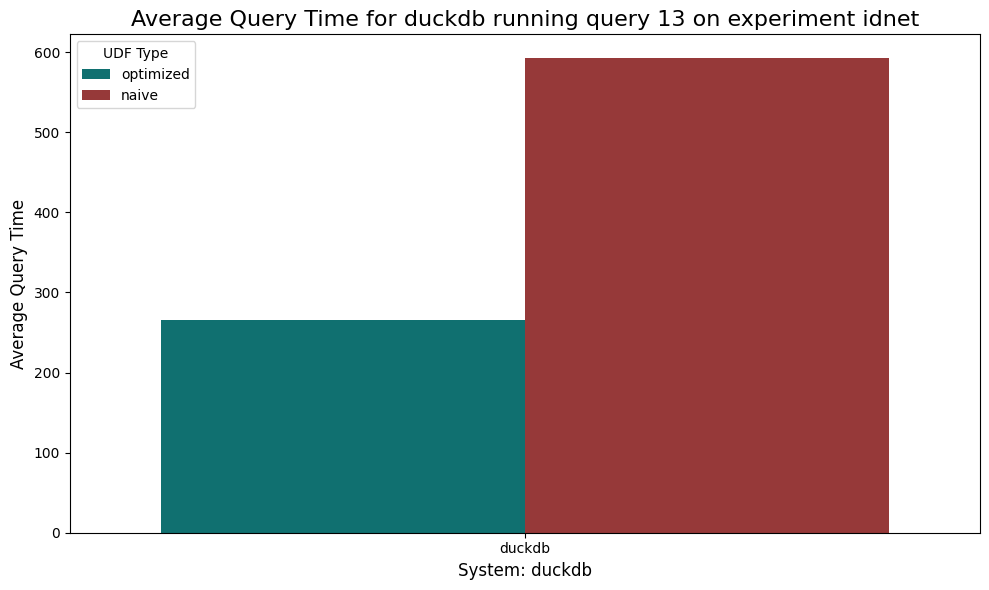

duckdb 14 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,14,naive,117.4,33.652246,32.006545,945878.7,1277144.3,236229.2,0.0,0.0,66.230567,0.114189,0.0,0.000112,1.882034,0.0,9.992973,21.777488
1,idnet,duckdb,14,optimized,7.5,29.006964,35.518214,40806.6,32987.8,10695.5,0.0,0.0,70.556071,0.438214,0.0,0.000000,1.821071,0.0,14.955357,12.235357


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


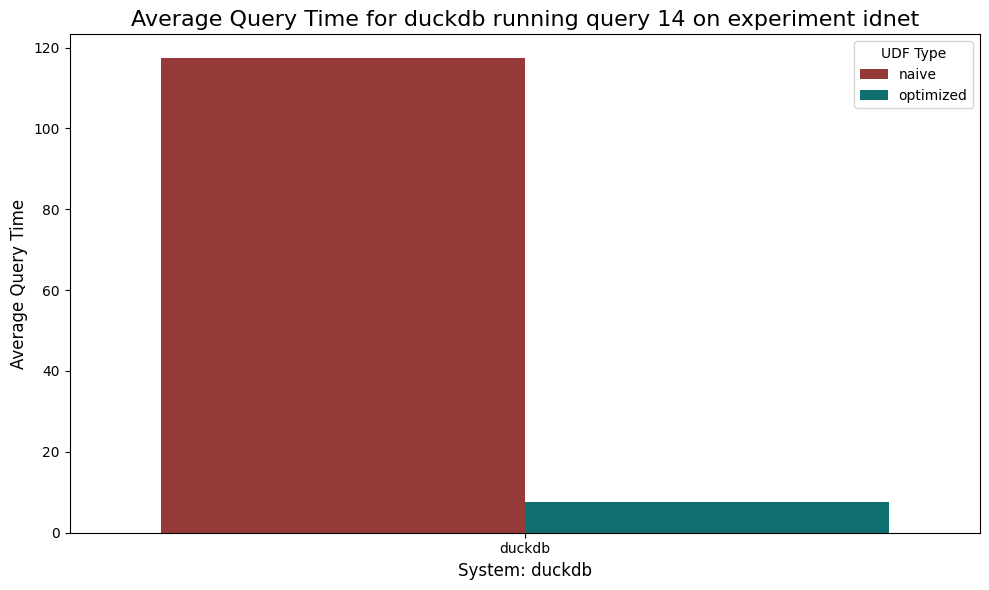

duckdb 1 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,1,optimized,417.7,52.367579,50.844168,2247133.4,2070859.1,565953.4,0.0,0.0,44.998763,2.631104,0.0,0.000054,4.959938,0.0,19.958009,27.382703
1,idnet10k,duckdb,1,naive,1060.5,53.248121,25.772979,6799003.6,8348743.8,1746571.7,0.0,0.0,46.480503,0.269767,0.0,0.000109,4.534091,0.0,11.224183,37.492224


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


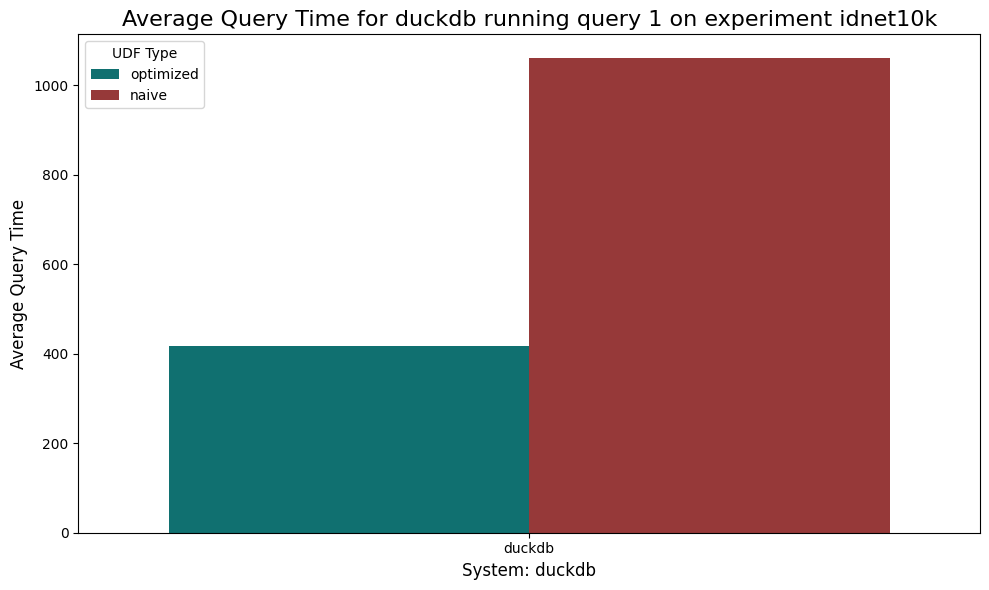

duckdb 2 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,2,naive,1177.8,46.484069,25.336598,8836262.7,11760843.5,2267444.6,0.0,0.0,53.257059,0.260834,0.0,0.000085,2.612794,0.0,11.194167,32.680833
1,idnet10k,duckdb,2,optimized,406.9,51.817068,50.529112,2271486.4,2161950.2,555125.4,0.0,0.0,47.041081,1.139224,0.0,0.000799,4.456005,0.0,19.557263,27.745149


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


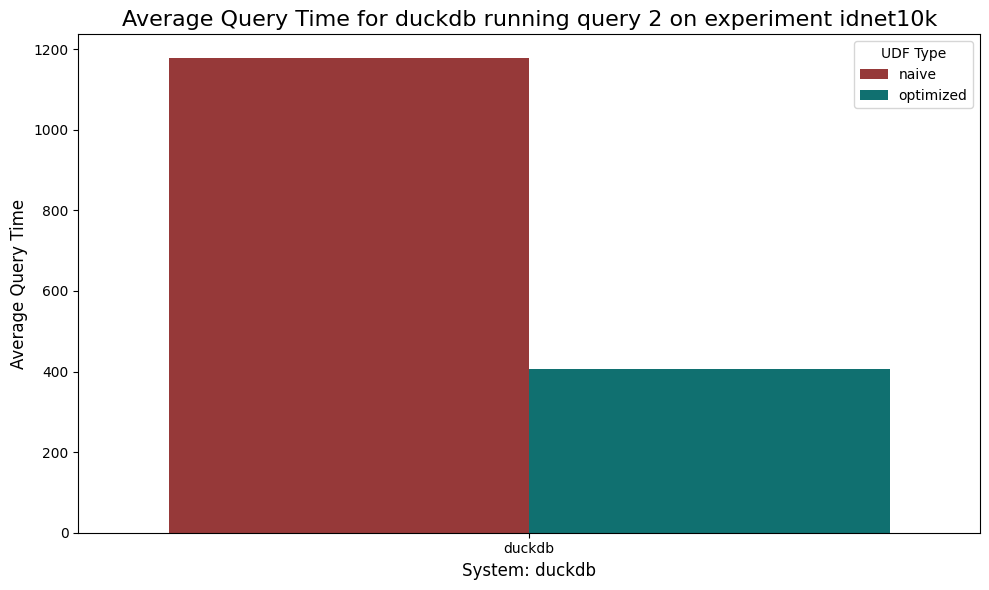

duckdb 3 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,3,optimized,0.1,15.715000,22.61000,562.9,547.4,193.7,0.0,0.0,82.695000,1.610000,0.0,0.000000,1.830000,0.0,10.100000,3.770000
1,idnet10k,duckdb,3,naive,124.4,67.073093,18.41859,752261.0,881757.3,170504.5,0.0,0.0,32.829751,0.094673,0.0,0.000417,7.741236,0.0,15.810034,43.500027


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


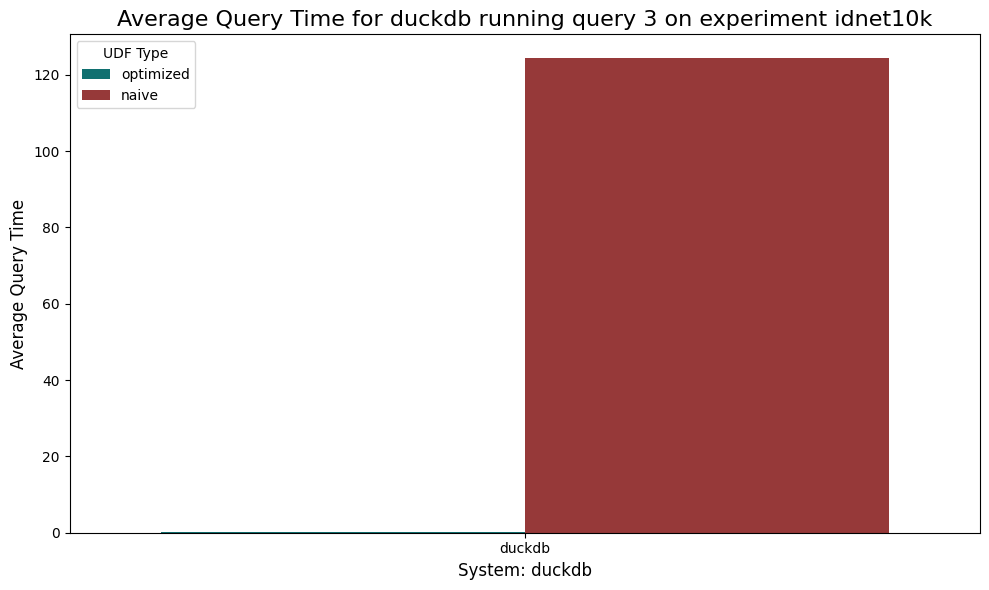

duckdb 4 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,4,optimized,0.0,15.580000,22.520000,0.0,0.0,0.0,0.0,0.0,81.030000,3.400000,0.0,0.0,1.670000,0.0,4.460000,9.470000
1,idnet10k,duckdb,4,naive,131.8,60.576277,18.417512,862034.6,1063485.6,200377.1,0.0,0.0,39.320734,0.096133,0.0,0.0,6.799111,0.0,14.457343,39.143915


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


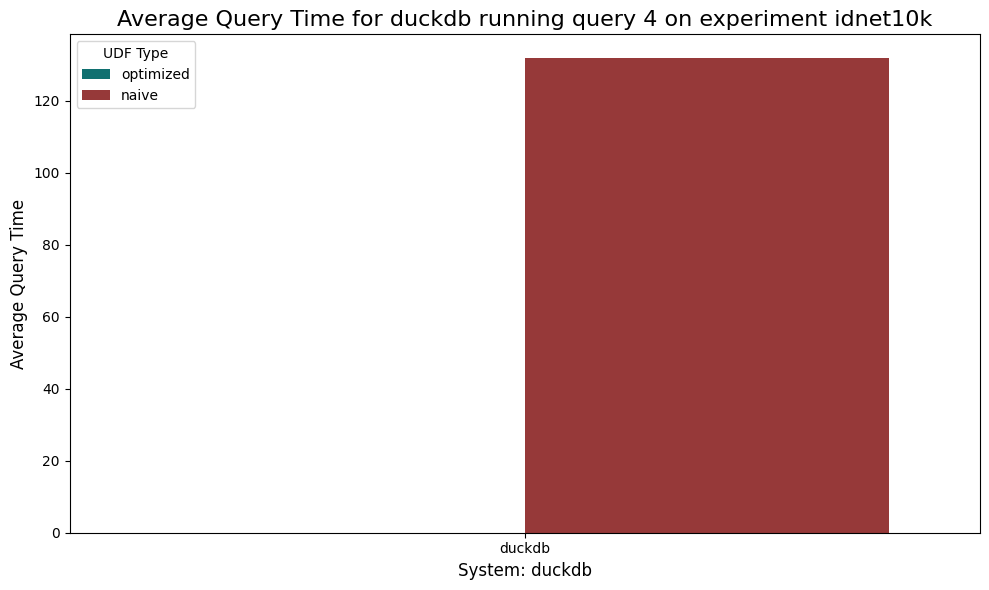

duckdb 5 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,5,naive,1088.1,51.114654,25.317050,7442420.1,9429675.7,1909465.7,0.0,0.0,48.774933,0.112060,0.0,0.000149,3.896410,0.0,11.501994,35.720142
1,idnet10k,duckdb,5,optimized,379.9,55.186003,51.191516,1954906.7,1724629.3,459250.6,0.0,0.0,44.152269,0.660745,0.0,0.000089,5.208884,0.0,21.458723,28.442445


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


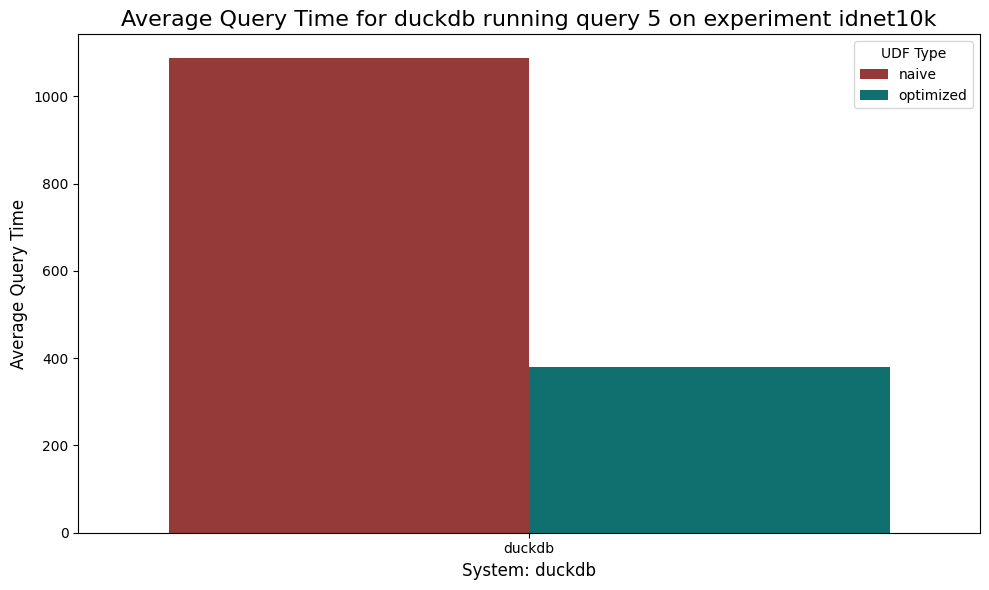

duckdb 6 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


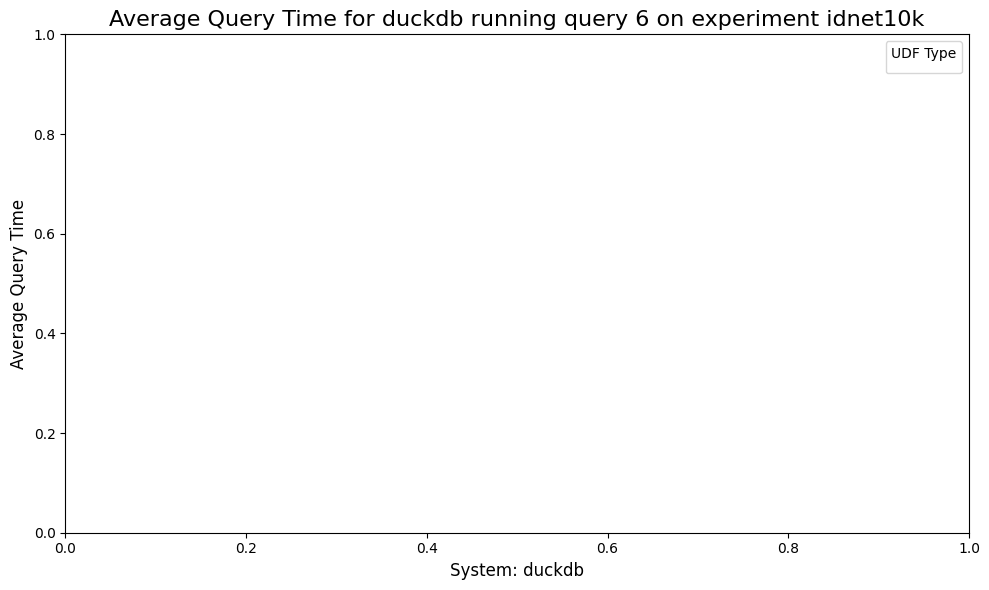

duckdb 7 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


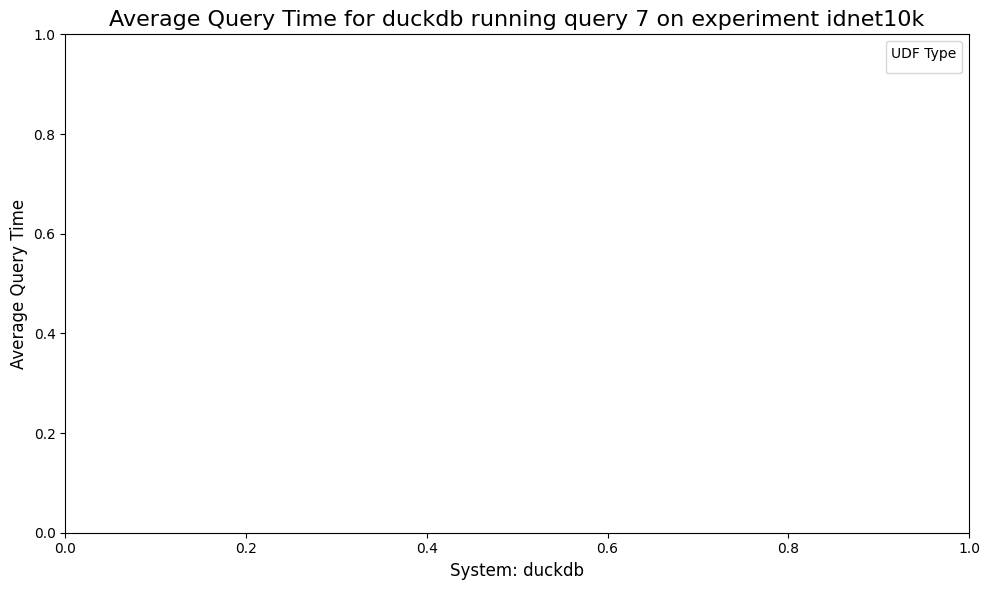

duckdb 8 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


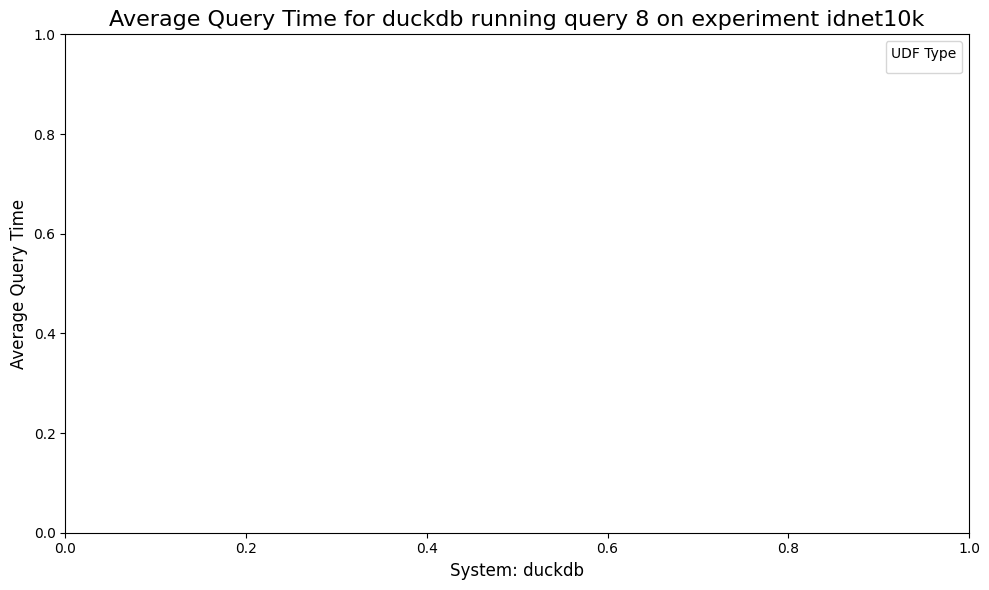

duckdb 9 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


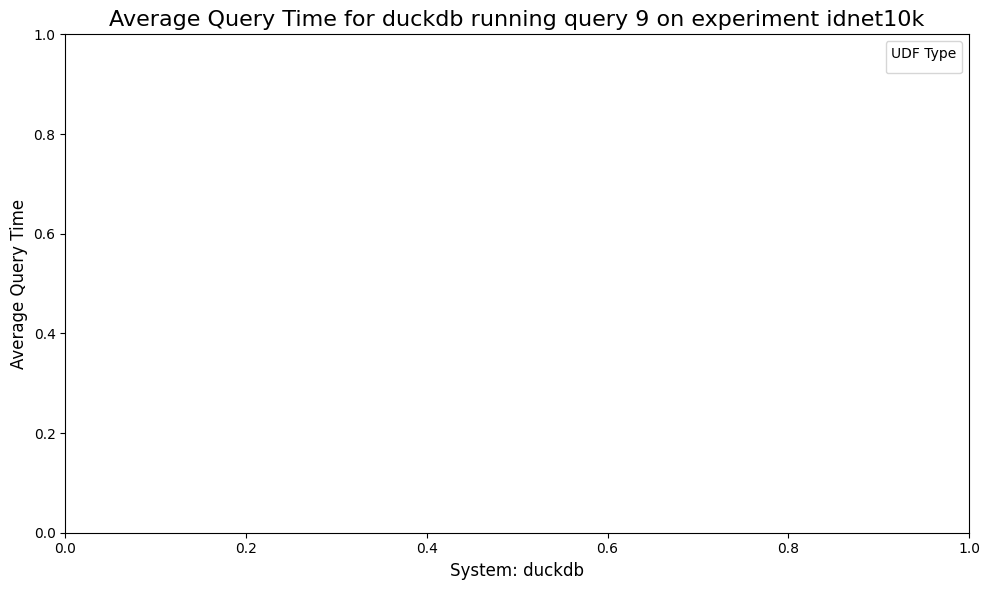

duckdb 10 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


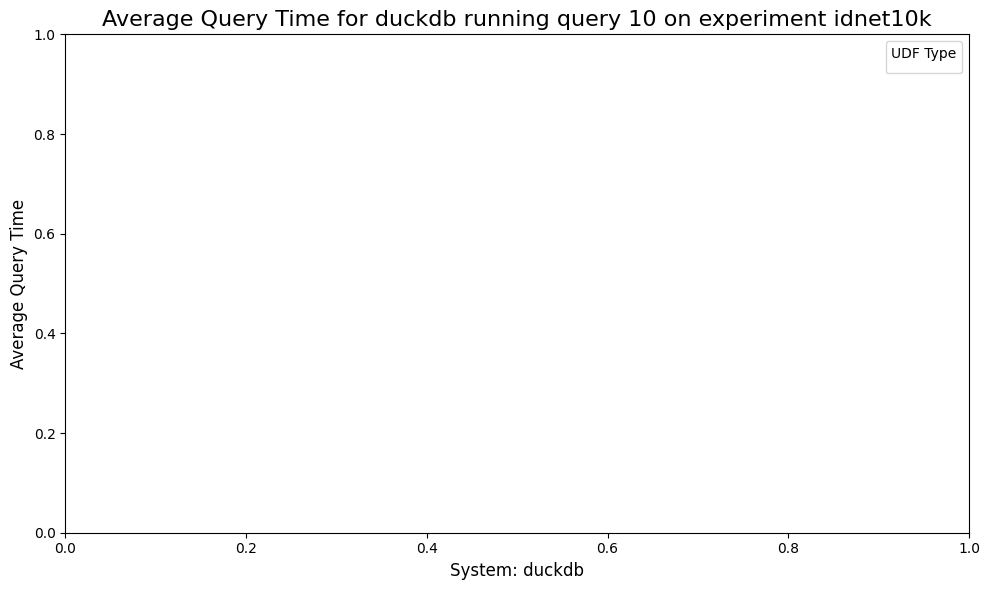

duckdb 11 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


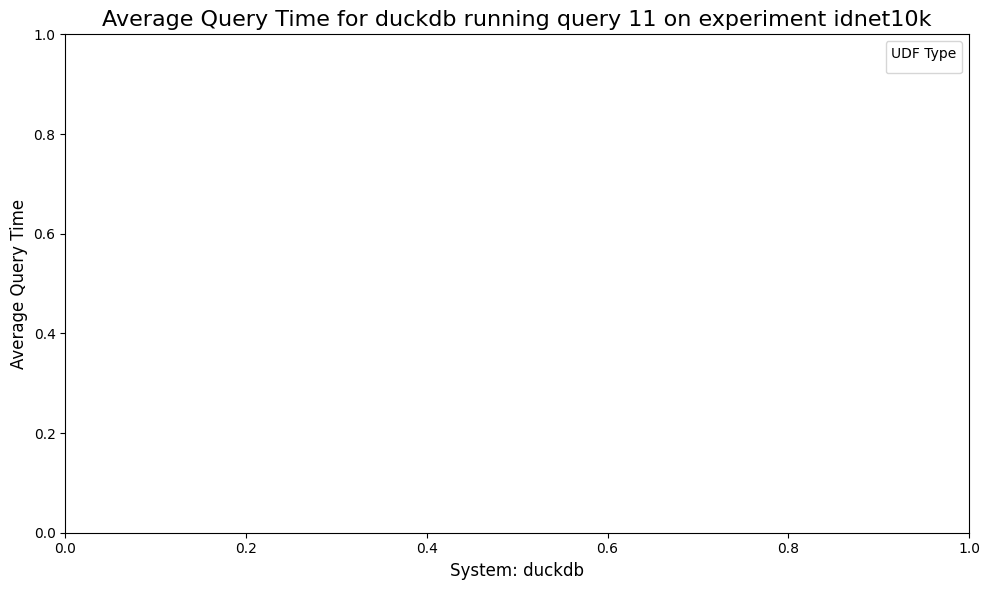

duckdb 12 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


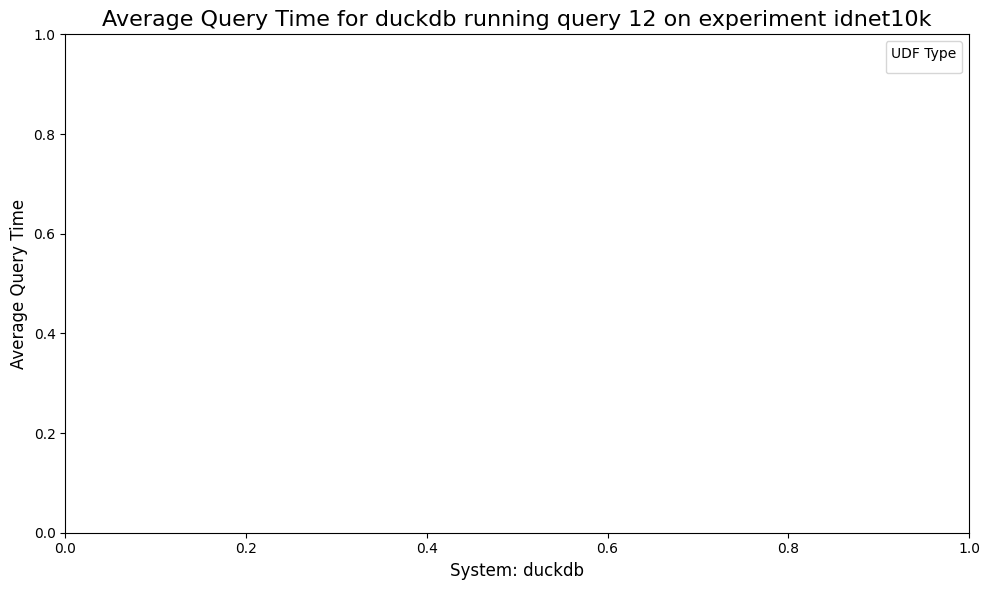

duckdb 13 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


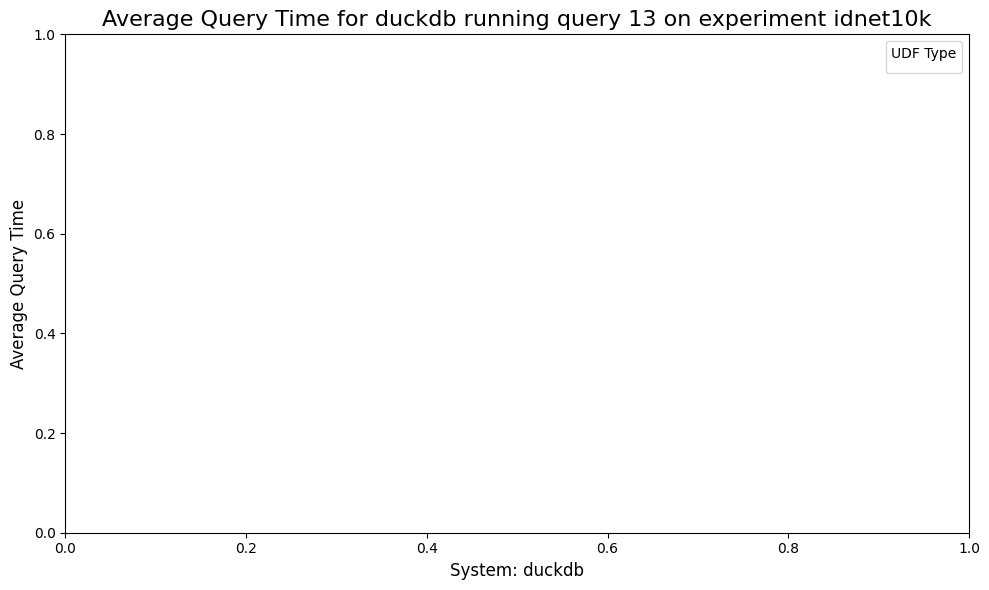

duckdb 14 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


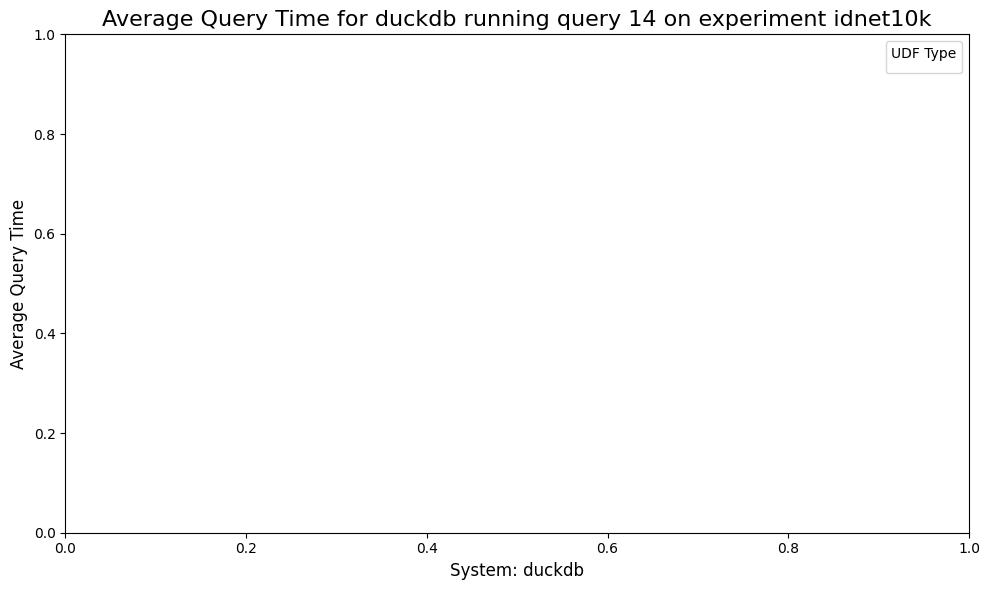

clickhouse 1 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,1,naive,349.8,97.425973,10.81523,1197248.3,880885.8,255644.9,0.0,0.0,2.552671,0.004065,0.0,0.0,10.786266,0.0,16.696877,69.945499


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


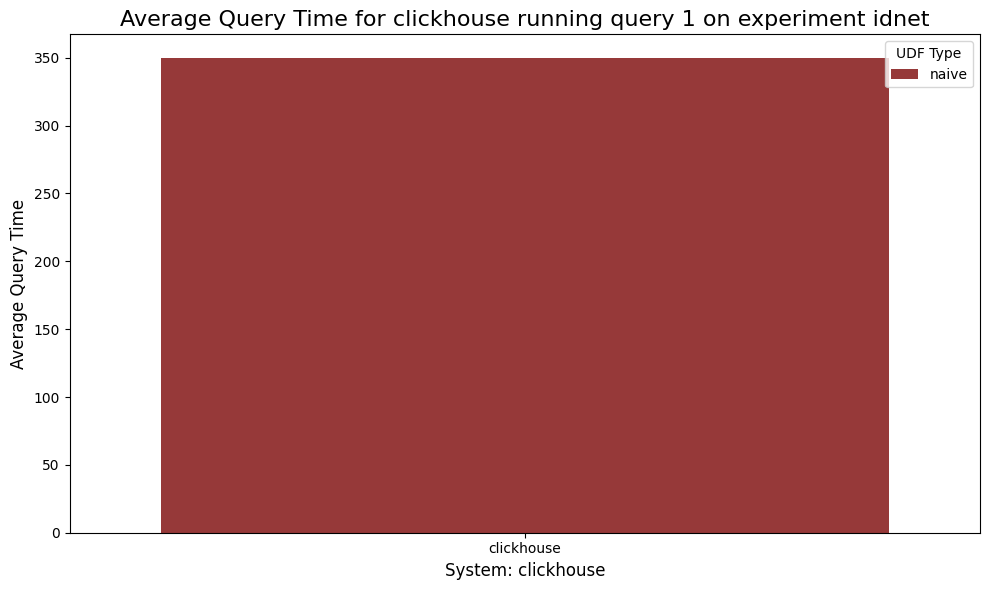

clickhouse 2 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,2,naive,321.9,97.320697,10.758608,1090202.3,801401.0,233715.4,0.0,0.0,2.673281,0.005848,0.0,0.000669,10.8206,0.0,16.890413,69.607452


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


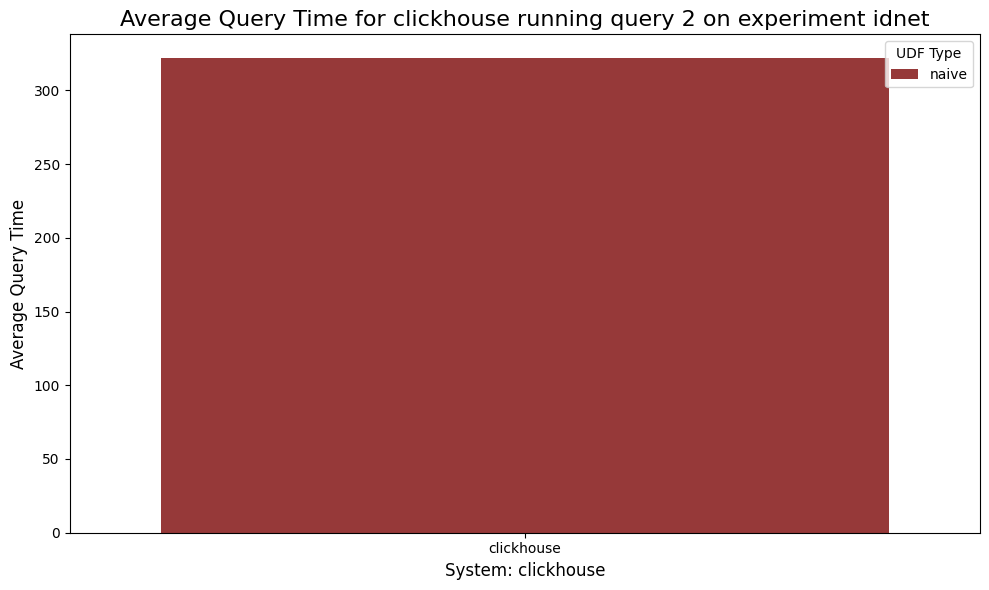

clickhouse 3 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,3,naive,23.6,92.528198,10.246066,78501.0,144885.7,15516.8,0.0,0.0,7.443241,0.027027,0.0,0.0,9.207791,0.0,14.917174,68.36416


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


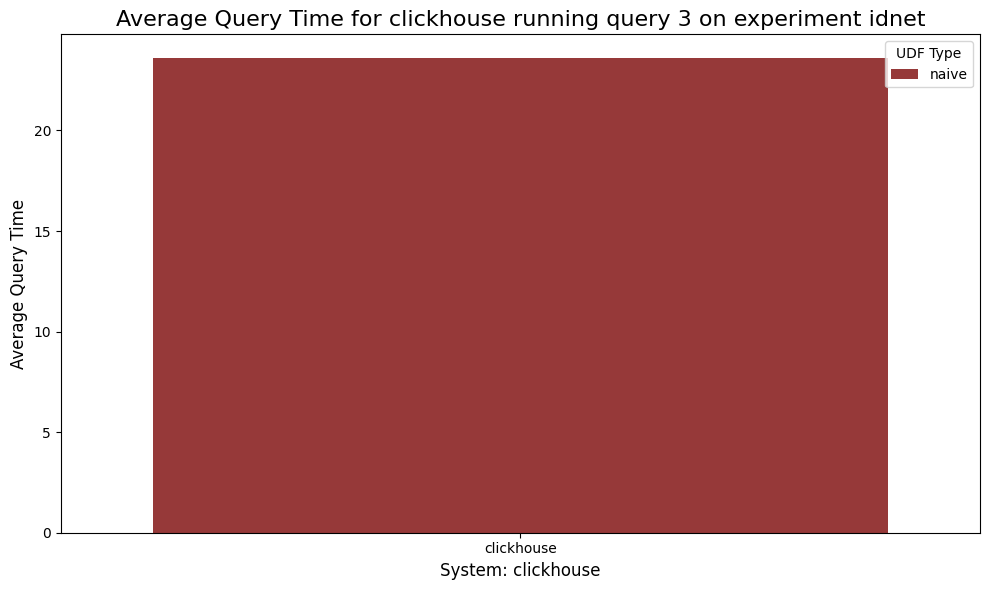

clickhouse 4 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,4,naive,24.4,93.573593,10.249225,82291.6,132161.6,16697.7,0.0,0.0,6.382019,0.011019,0.0,0.0,9.552145,0.0,15.393463,68.245392


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


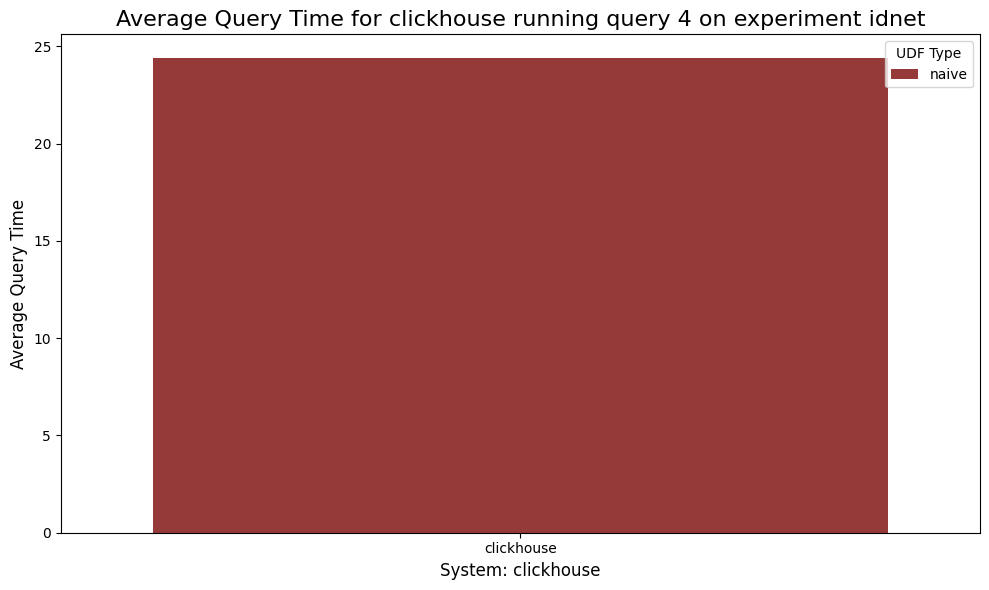

clickhouse 5 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,5,naive,187.9,96.55736,10.758731,641167.8,509108.7,139313.7,0.0,0.0,3.432941,0.009422,0.0,0.0,10.811961,0.0,16.726555,69.021449


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


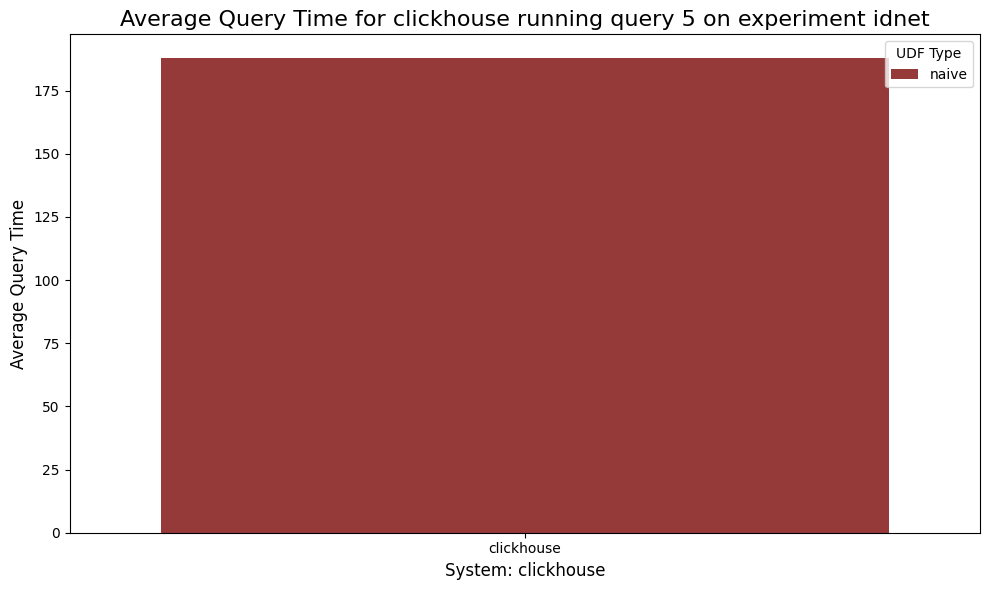

clickhouse 6 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,6,naive,5126.0,35.893718,17.15442,25340216.6,26115849.4,8499149.2,0.0,0.0,63.917391,0.175162,0.0,0.000131,3.651483,0.0,8.78887,23.452277


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


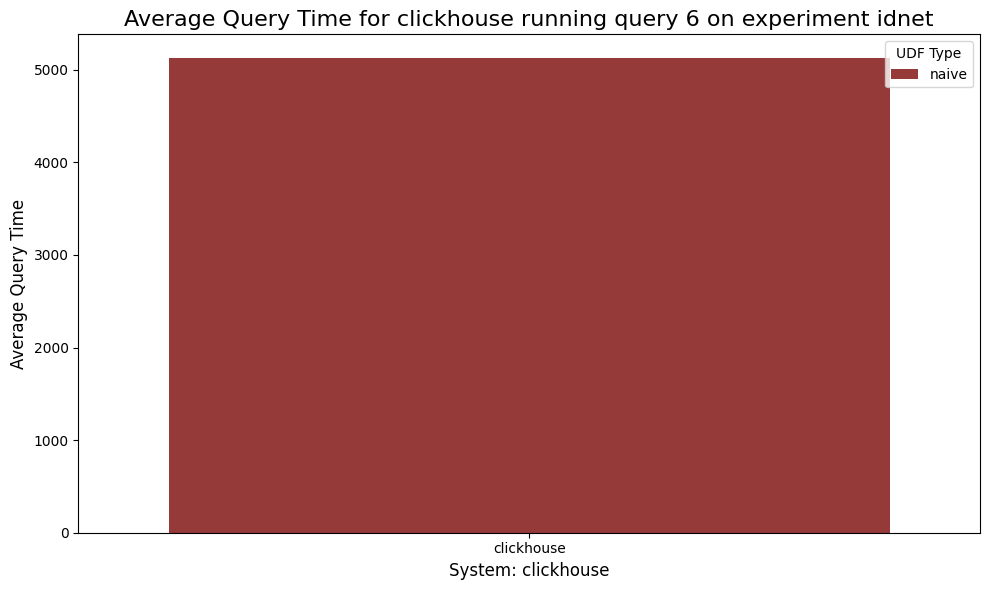

clickhouse 7 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,7,naive,3746.4,35.896852,18.073984,17396989.8,17733374.8,5348022.4,0.0,0.0,63.938772,0.160038,0.0,0.000041,3.805626,0.0,8.955144,23.134219


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


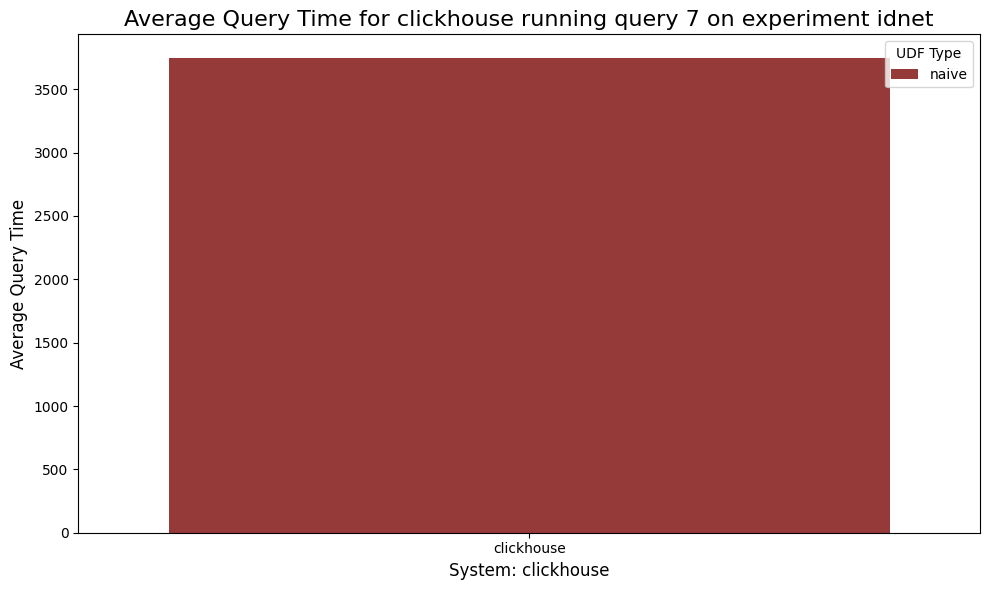

clickhouse 8 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,8,naive,1305.8,33.223114,18.248858,7426894.4,7432314.4,2984211.6,0.0,0.0,66.333497,0.442743,0.0,0.01091,3.033628,0.0,7.910709,22.267894


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


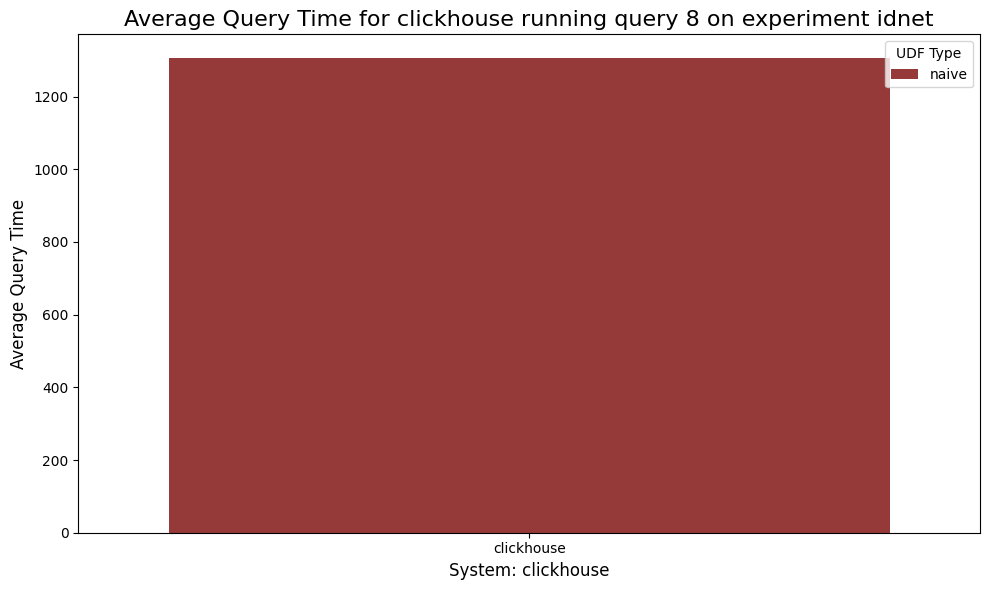

clickhouse 9 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,9,naive,3427.2,29.827977,18.743323,16519201.8,16780840.6,5118029.4,0.0,0.0,69.97302,0.199229,0.0,0.000047,3.004614,0.0,7.60706,19.216466


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


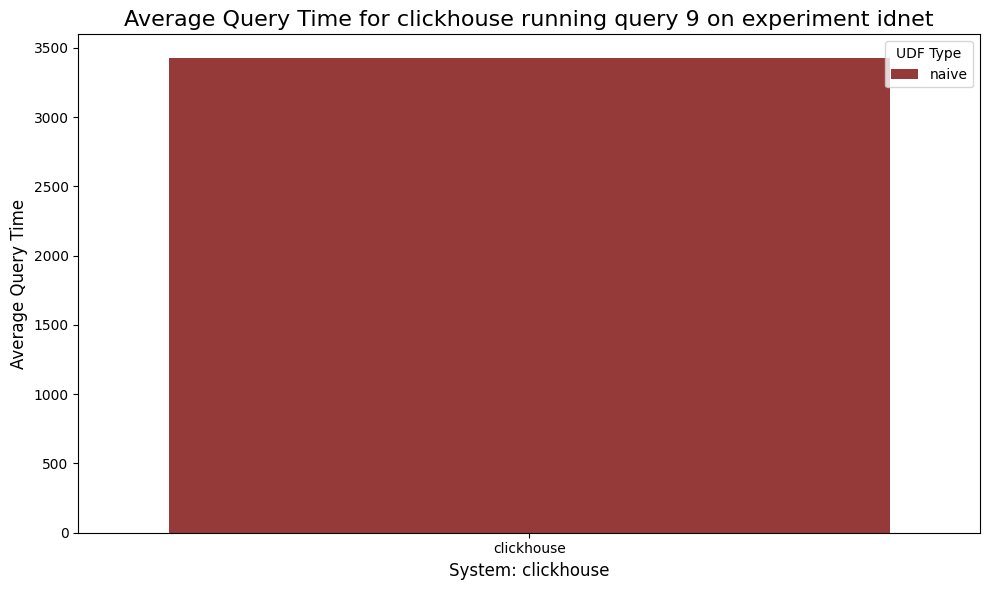

clickhouse 10 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,10,naive,1293.2,32.593659,18.949059,7329864.4,7335686.2,2948173.2,0.0,0.0,66.99639,0.409174,0.0,0.0,3.012766,0.0,7.823019,21.758359


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


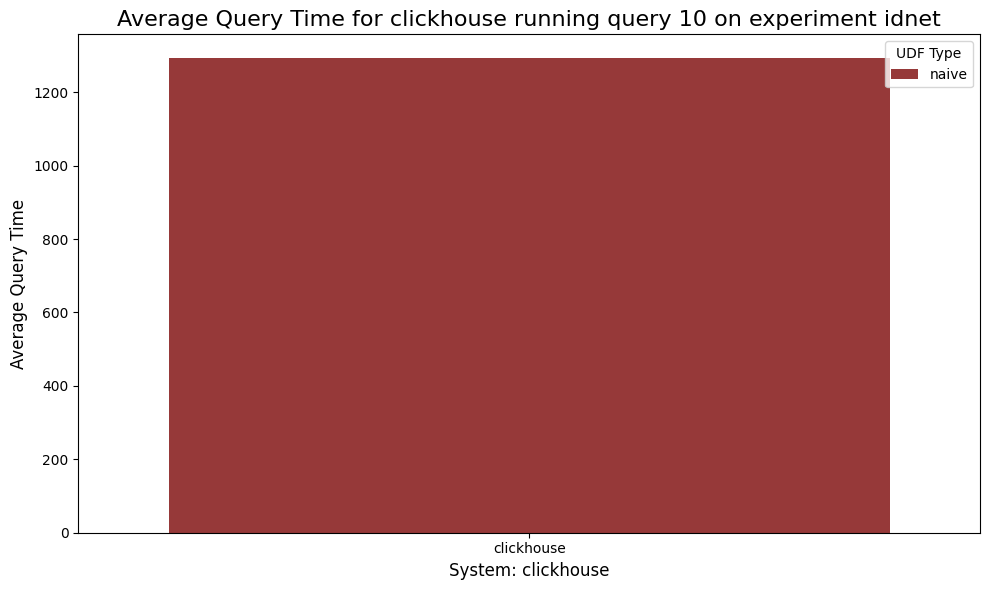

clickhouse 11 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,11,naive,845.4,99.383198,17.798691,2475539.6,2610193.0,594987.8,0.0,0.0,0.524118,0.002526,0.0,0.0004,13.938497,0.0,22.478253,62.751928


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


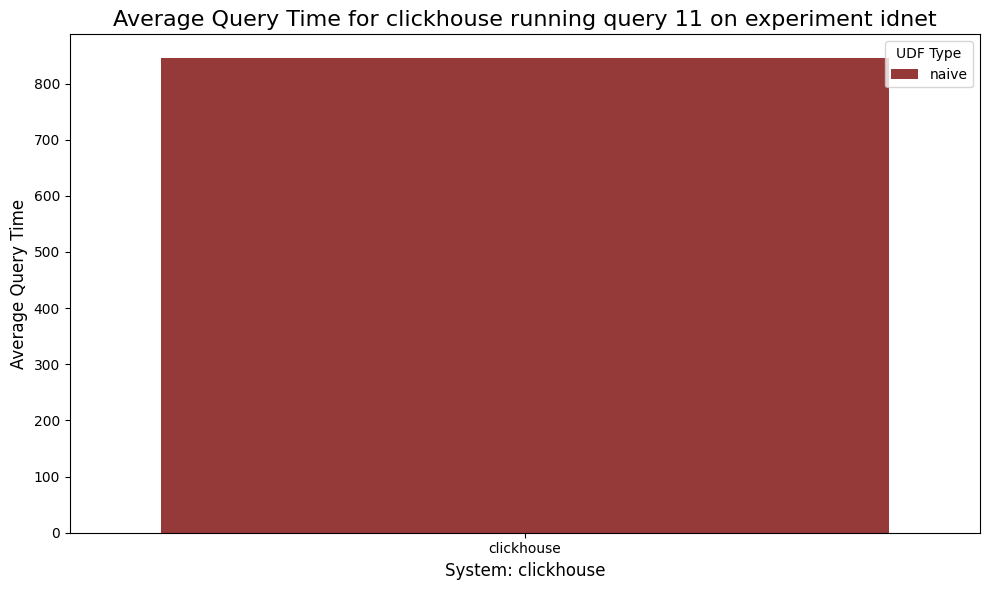

clickhouse 12 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,12,naive,16.6,82.339484,17.7525,50279.0,51940.8,11430.8,0.0,0.0,17.05746,0.041667,0.0,0.0,10.938452,0.0,24.781349,46.463849


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


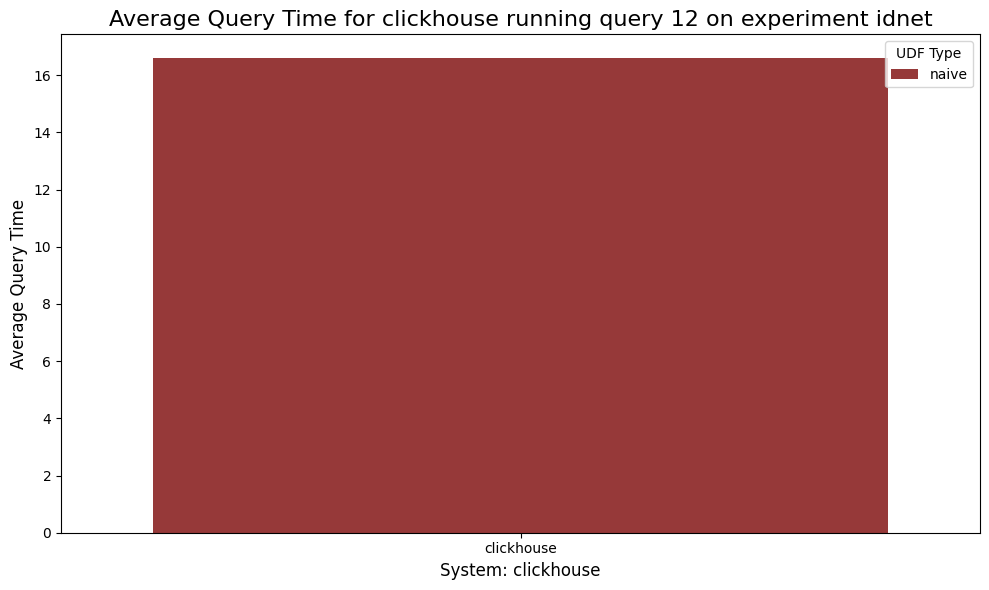

clickhouse 13 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,13,naive,3570.4,33.90166,20.651688,16888911.4,17277568.6,5192950.0,0.0,0.0,65.965136,0.133657,0.0,0.003707,3.490835,0.0,8.485146,21.919287


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


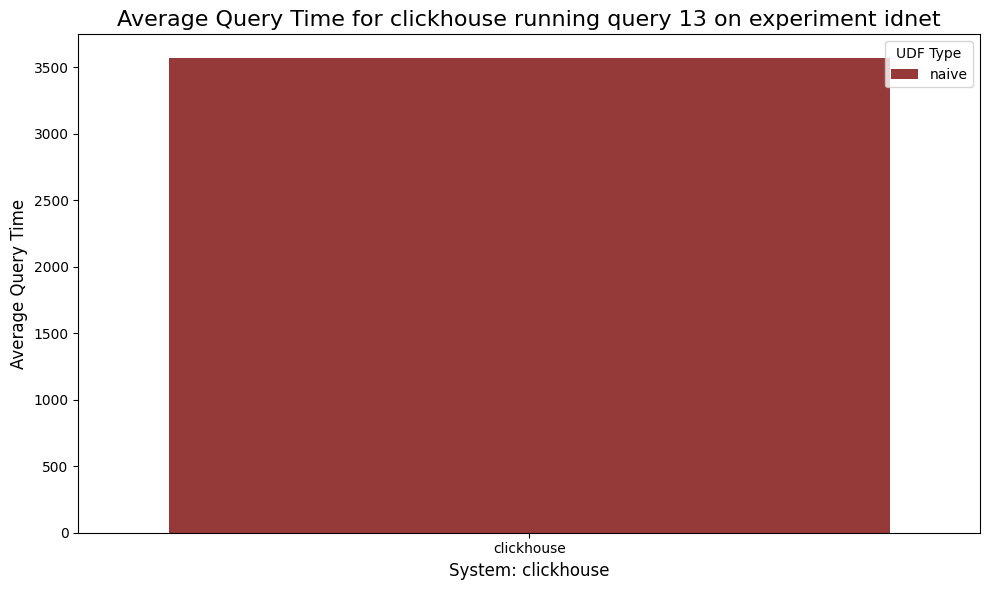

clickhouse 14 idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,14,naive,1272.8,32.3996,21.369794,7245571.0,7237411.2,2906458.2,0.0,0.0,67.436273,0.163661,0.0,0.0,2.893466,0.0,7.769025,21.736541


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


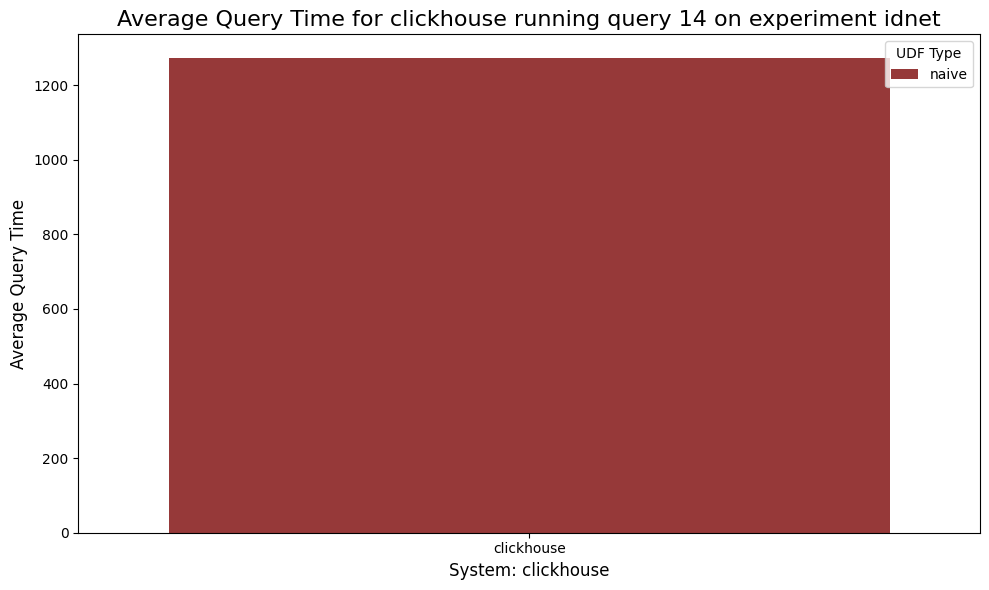

clickhouse 1 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,1,naive,5018.0,99.816777,12.258299,17039113.0,12020870.0,3.178413e+06,0.0,0.0,0.175261,0.000741,0.0,0.000442,10.517746,0.0,16.461805,72.773841


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


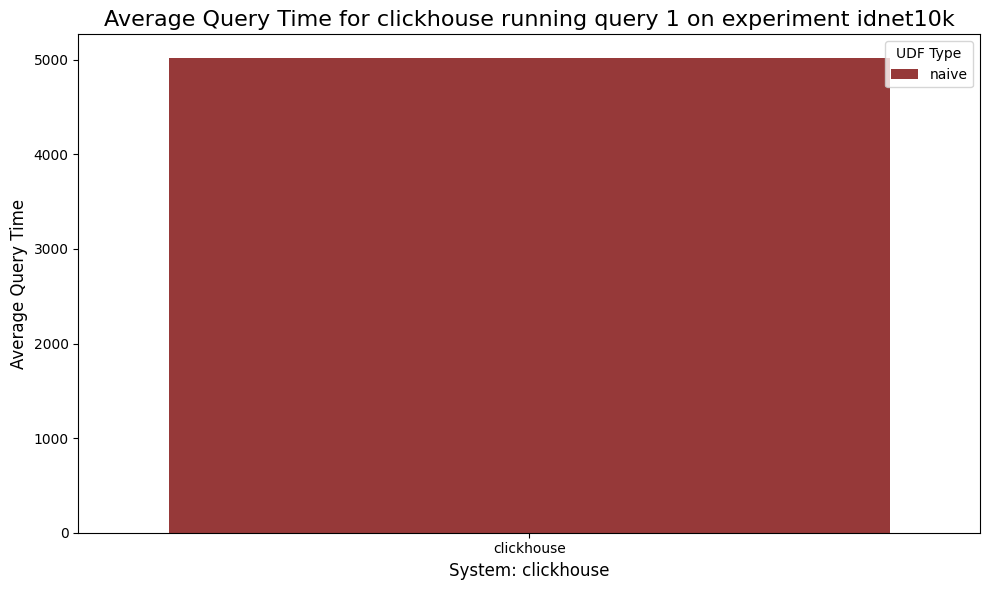

clickhouse 2 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,2,naive,4996.0,99.810085,12.268799,1.686558e+07,11916817.0,3.150743e+06,0.0,0.0,0.18956,0.000311,0.0,0.000254,10.648606,0.0,16.42073,72.680638


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


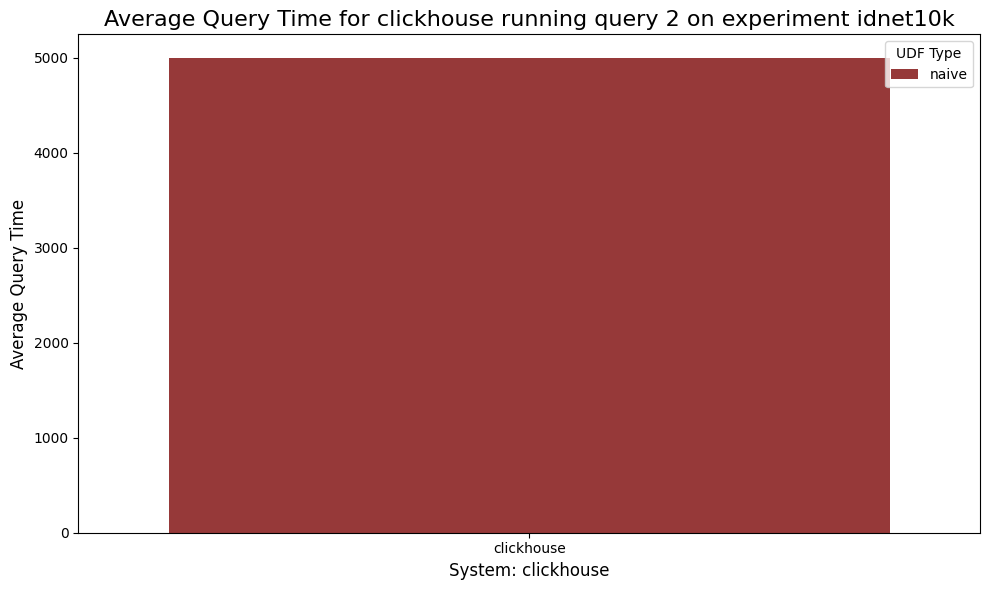

clickhouse 3 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,3,naive,489.0,99.719109,10.872539,1650575.0,1.510660e+06,306486.666667,0.0,0.0,0.276512,0.003188,0.0,0.000882,10.637814,0.0,15.676594,73.316474


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


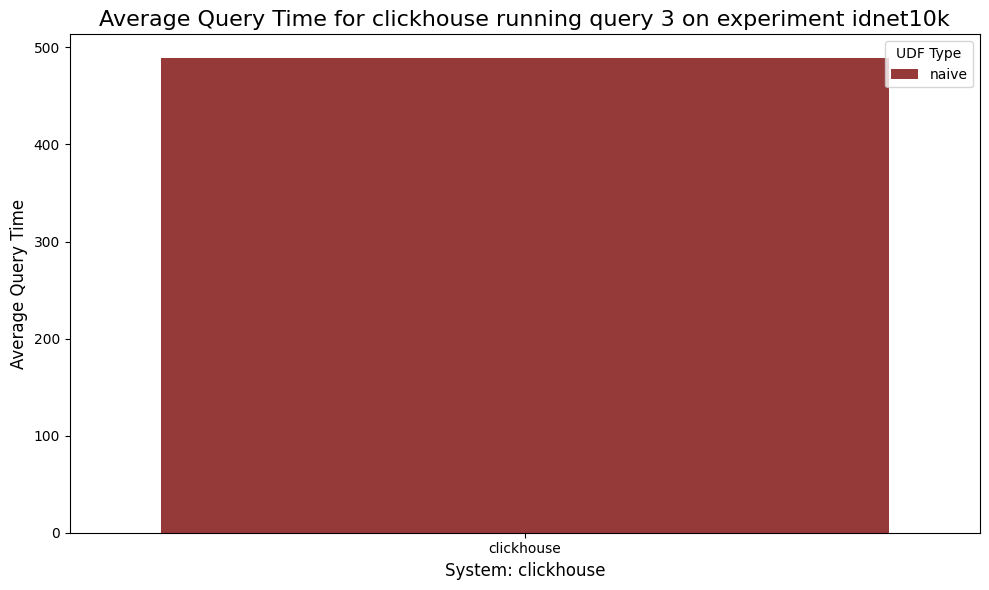

clickhouse 4 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,4,naive,487.666667,99.752054,10.855849,1.653261e+06,1473681.0,306989.0,0.0,0.0,0.247428,0.000518,0.0,0.0,10.521442,0.0,15.383061,73.77651


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


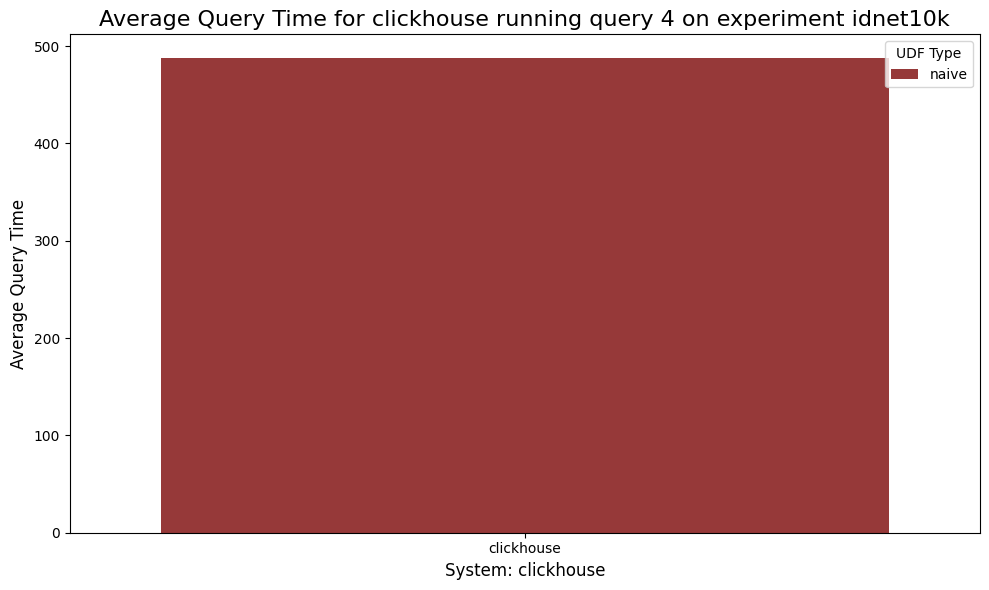

clickhouse 5 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,5,naive,3064.666667,99.904376,12.180184,1.049537e+07,7.567275e+06,1.989797e+06,0.0,0.0,0.095424,0.0002,0.0,0.000201,10.619406,0.0,16.241984,72.995742


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


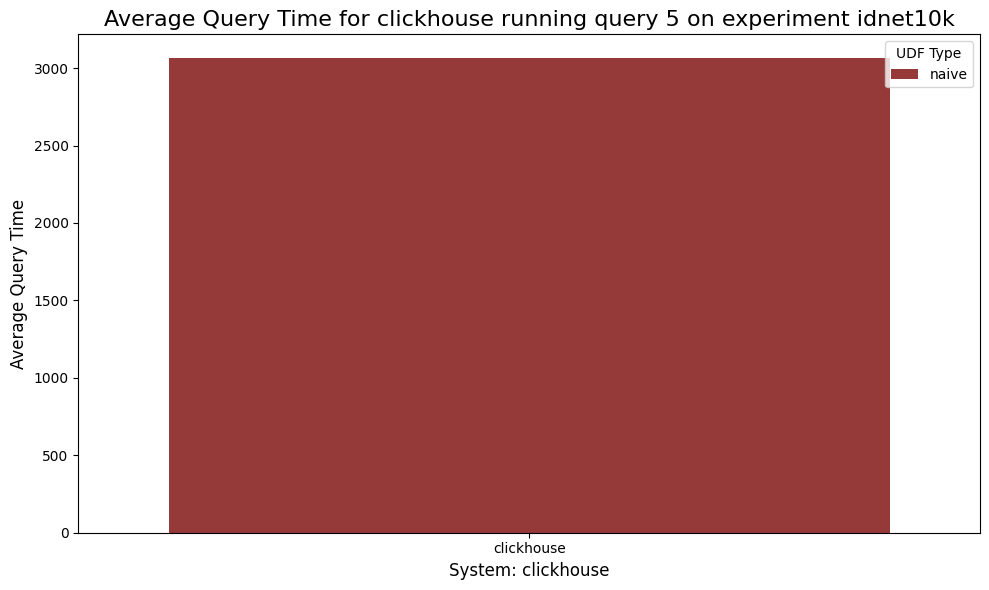

clickhouse 6 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,6,naive,17560.0,94.635951,15.545115,52822786.0,53532778.0,18791444.0,0.0,0.0,5.315681,0.037959,0.0,0.004477,14.823022,0.0,23.05499,56.448012


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


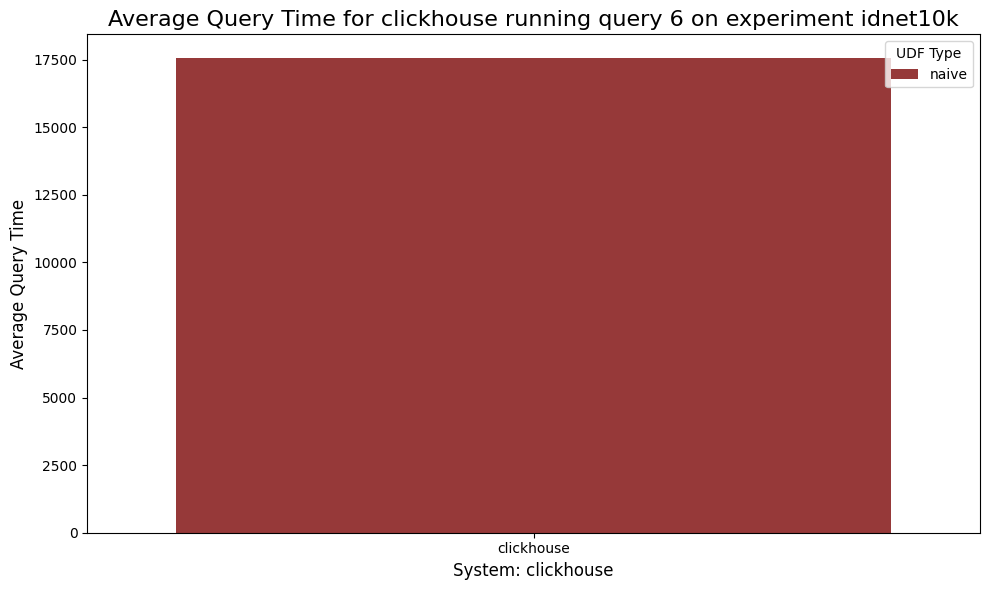

clickhouse 7 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,7,naive,11652.0,89.391022,60.297587,35078728.0,34488455.0,10339068.0,0.0,0.0,9.909403,0.692275,0.0,0.000393,13.700104,0.0,23.191353,52.041172


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


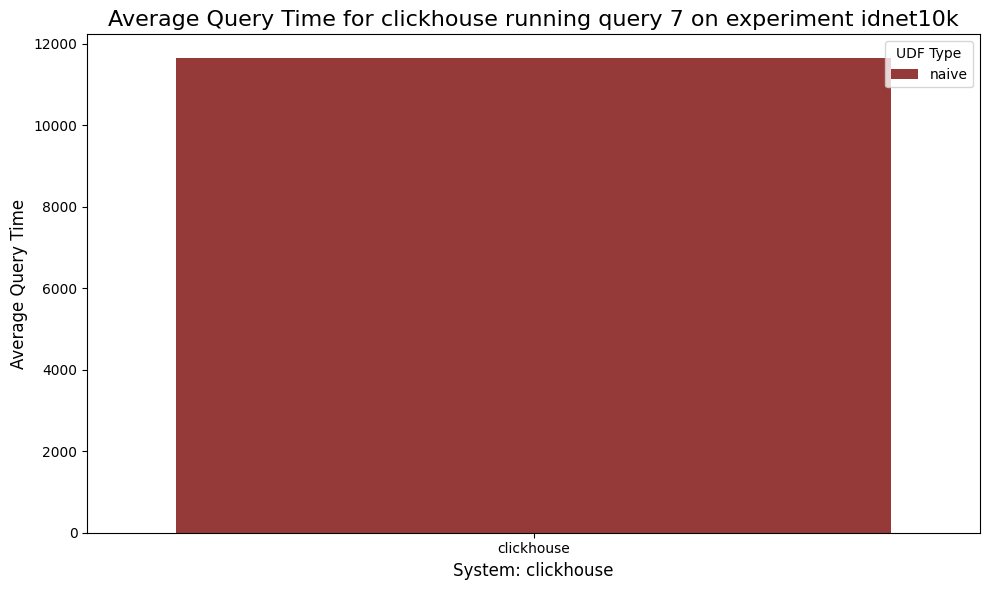

clickhouse 8 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,8,naive,6764.0,90.783726,59.235309,22502466.0,23542719.0,9905754.0,0.0,0.0,8.205896,1.009729,0.0,0.000325,14.500682,0.0,20.832435,55.375654


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


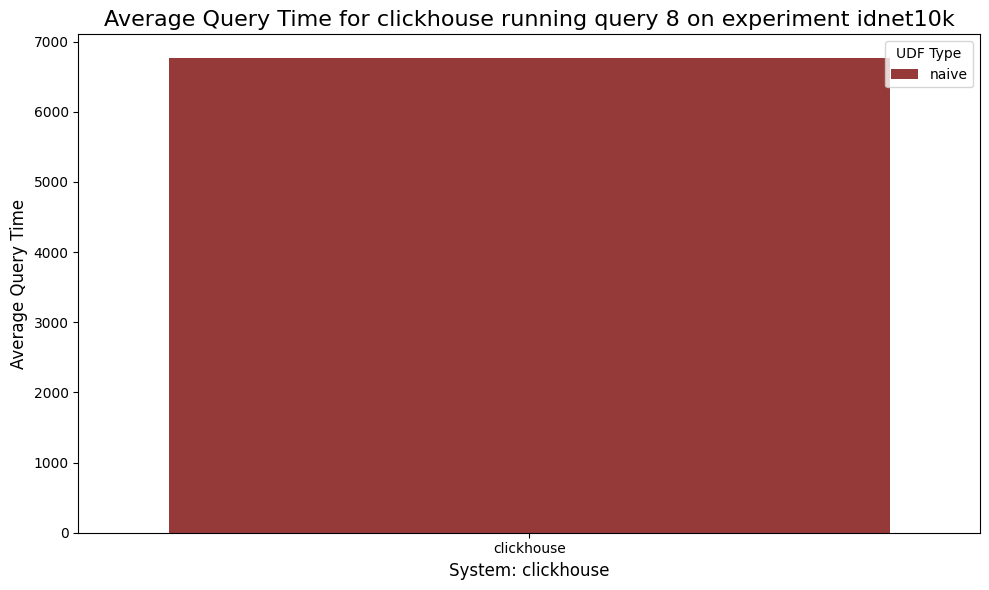

clickhouse 9 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,9,naive,11612.0,89.37424,60.916568,34930029.0,33630536.0,10234748.0,0.0,0.0,9.955929,0.665038,0.0,0.000311,13.620604,0.0,23.129868,52.218799


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


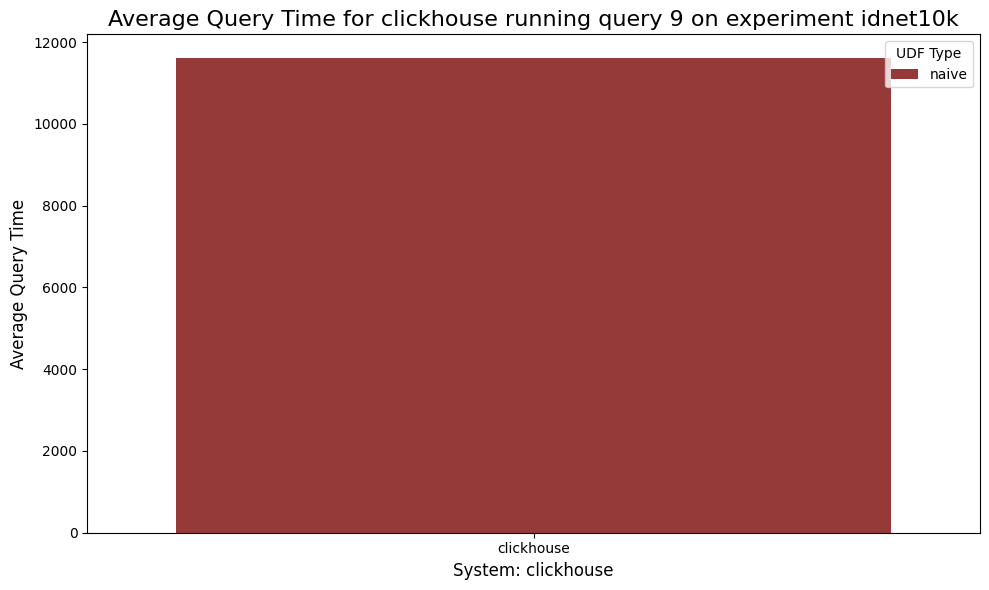

clickhouse 10 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,10,naive,6850.0,89.973914,60.017722,22943063.0,24074812.0,10051802.0,0.0,0.0,8.263676,1.762186,0.0,0.00032,14.423249,0.0,20.800128,54.680388


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


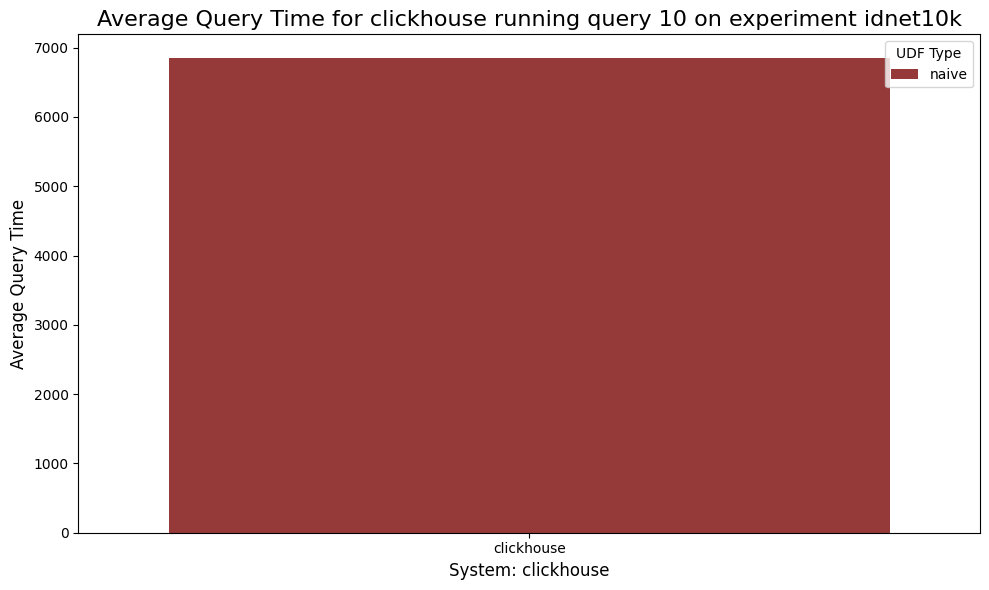

clickhouse 11 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,11,naive,856.0,99.678094,18.983215,2497353.0,2608349.0,605248.0,0.0,0.0,0.318065,0.0,0.0,0.000711,13.919346,0.0,22.587909,62.890896


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


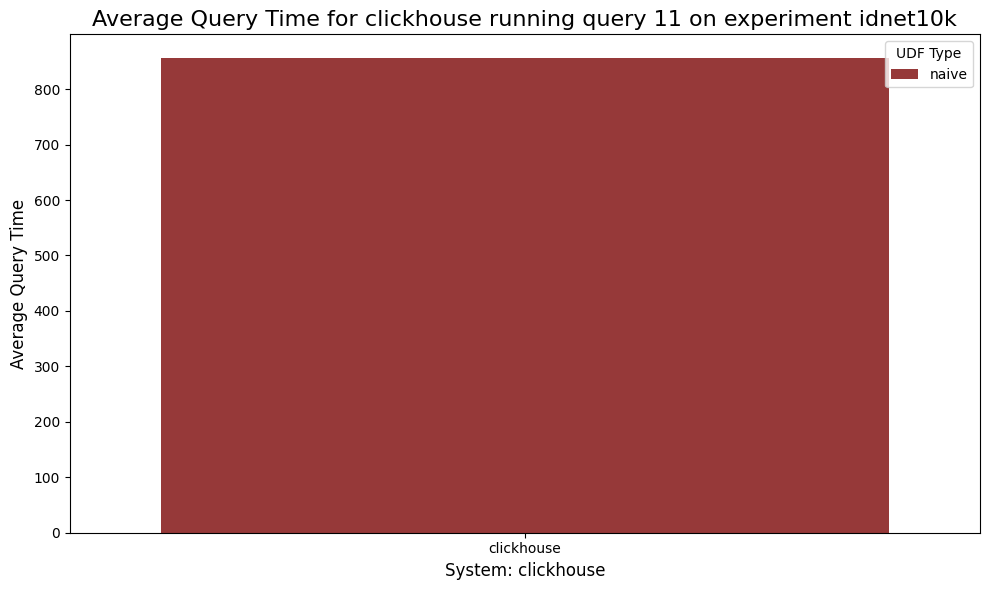

clickhouse 12 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)
/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='UDF Type')


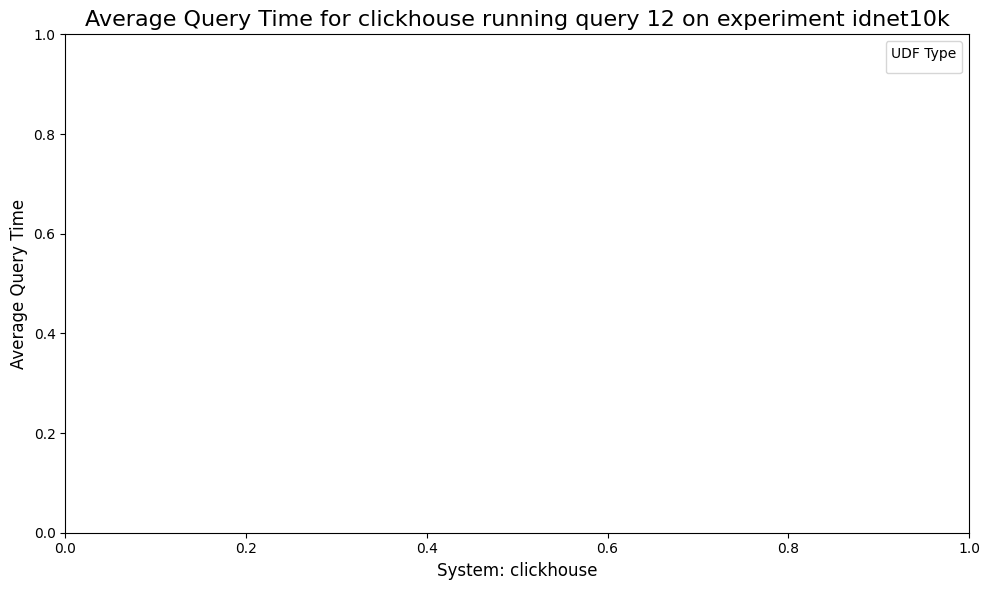

clickhouse 13 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,13,naive,12331.0,84.170554,65.141537,39044793.0,38277173.0,11451174.0,0.0,0.0,11.819621,4.005973,0.0,0.000584,12.791829,0.0,21.885379,49.080272


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


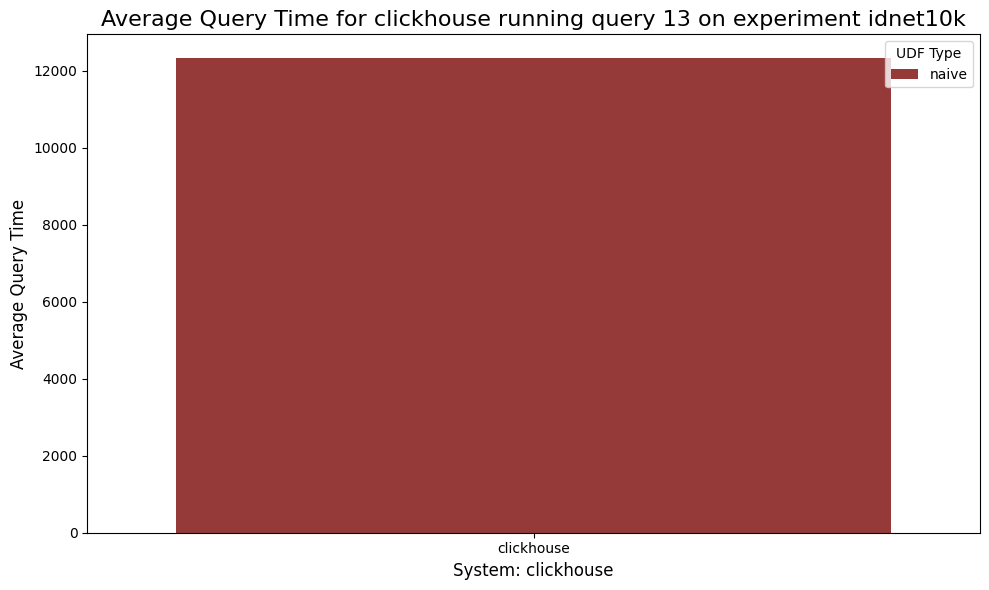

clickhouse 14 idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,14,naive,7318.0,84.572941,63.375721,25514083.0,27137456.0,10835454.0,0.0,0.0,12.1926,3.233981,0.0,0.000688,13.40595,0.0,19.628584,51.467379


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/3107041598.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)


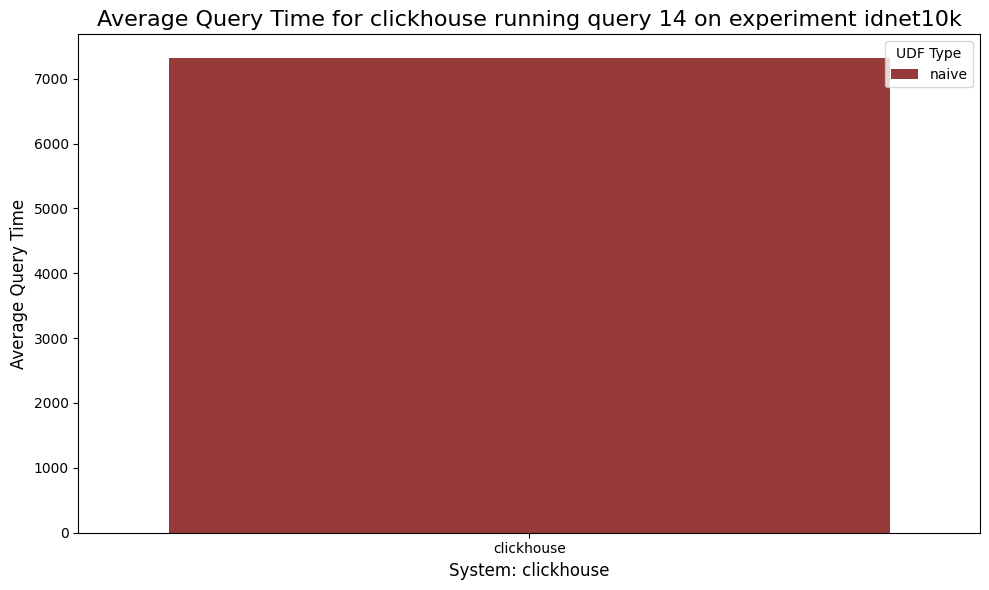

In [24]:
systems = ['spark', 'postgres', 'evadb', 'duckdb', 'clickhouse']
tables = ['idnet', 'idnet10k']

#systems = ['spark']
#tables = ['idnet']



for system in systems:
    for table in tables:
        for query in range(1,15):
            try:
                print(system, query, table)

                hues = {'optimized': 'teal', 'naive': 'brown'}
                #final.filter(f"system='{system}' and query={query} and experiment='{table}'").show()
                df = final.filter(f"system='{system}' and query={query} and experiment='{table}'").toPandas()
                display(df)
                # Use seaborn to create the grouped bar plot
                plt.figure(figsize=(10, 6)) # Set the figure size
                sns.barplot(data=df, x='system', y='query_time_avg', hue='udf', palette=hues, ci=None)

                # Add titles and labels for clarity
                plt.title(f'Average Query Time for {system} running query {query} on experiment {table}', fontsize=16)
                plt.xlabel(f'System: {system}', fontsize=12)
                plt.ylabel('Average Query Time', fontsize=12)
                plt.legend(title='UDF Type')

                # Display the plot
                plt.tight_layout()
                plt.show()
            except Exception as e:
                print(f'{system} {query} {table} failed')
                print(e)

spark idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,spark,1,optimized,35.100000,40.605718,43.153416,1.651876e+05,1.126201e+05,54593.000000,0.0,0.0,58.355117,0.981618,0.0,0.000000,3.368907,0.0,10.122058,26.879361
1,idnet,spark,10,optimized,10.900000,39.702455,41.886364,4.998330e+04,3.816880e+04,17223.300000,0.0,0.0,60.137273,0.159455,0.0,0.000000,3.737182,0.0,6.595182,29.371273
2,idnet,spark,4,optimized,4.200000,30.305500,41.013500,2.183350e+04,1.782750e+04,9426.400000,0.0,0.0,69.596500,0.096000,0.0,0.000000,2.920500,0.0,6.130500,21.262500
3,idnet,spark,13,optimized,434.500000,34.971539,43.119063,2.141638e+06,1.482201e+06,689522.500000,0.0,0.0,62.874495,2.155195,0.0,0.000048,2.709810,0.0,9.827675,22.437475
4,idnet,spark,6,optimized,221.300000,34.194399,42.903422,1.090179e+06,7.677745e+05,351110.300000,0.0,0.0,65.546807,0.261175,0.0,0.000000,2.585564,0.0,9.225125,22.388708
5,idnet,spark,8,naive,32.000000,33.903923,42.684403,1.520770e+05,1.090532e+05,44717.400000,0.0,0.0,65.971824,0.128869,0.0,0.000000,2.660363,0.0,3.897686,27.353834
6,idnet,spark,2,optimized,35.000000,39.950688,43.055421,1.675106e+05,1.150235e+05,56144.300000,0.0,0.0,59.820348,0.228705,0.0,0.000000,3.215830,0.0,9.921601,26.813999
7,idnet,spark,13,naive,334.400000,36.117135,42.586531,1.574185e+06,1.085999e+06,518016.400000,0.0,0.0,61.438330,2.446403,0.0,0.000066,2.732265,0.0,4.813661,28.573664
8,idnet,spark,1,naive,44.400000,31.456418,42.530890,2.251675e+05,1.806965e+05,82673.800000,0.0,0.0,51.683630,16.860365,0.0,0.000000,3.904796,0.0,5.989788,21.563876
9,idnet,spark,5,naive,19.300000,42.046333,42.222167,9.059990e+04,6.008770e+04,30836.700000,0.0,0.0,57.546927,0.407737,0.0,0.000000,3.454509,0.0,7.106287,31.482020


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


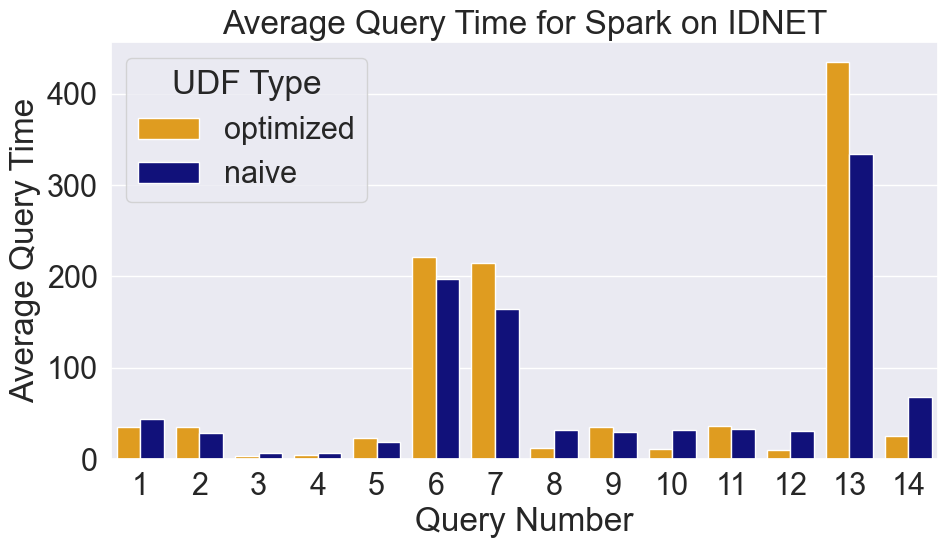

spark idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,spark,1,optimized,201.80,65.092408,33.892231,941160.30,603389.00,270875.90,0.0,0.0,34.525552,0.382157,0.0,0.000000,5.559773,0.0,16.791594,42.740289
1,idnet10k,spark,3,naive,26.30,56.913688,30.935065,125876.20,70952.70,31579.90,0.0,0.0,42.606903,0.479379,0.0,0.002159,4.042594,0.0,5.517388,47.350896
2,idnet10k,spark,4,naive,26.80,55.452491,29.151576,128097.50,71603.50,33160.40,0.0,0.0,43.979061,0.569656,0.0,0.000000,4.092165,0.0,5.722601,45.642739
3,idnet10k,spark,7,optimized,1159.00,55.520347,31.604739,4563312.50,1490973.00,1986423.75,0.0,0.0,44.026623,0.445884,0.0,0.000230,0.537201,0.0,15.346228,39.624997
4,idnet10k,spark,12,optimized,31.25,43.234777,23.846089,92228.50,37665.00,33787.25,0.0,0.0,56.684793,0.085893,0.0,0.000000,0.297472,0.0,1.443994,41.499609
5,idnet10k,spark,9,naive,149.00,35.048626,25.800610,248044.00,136445.40,164688.60,0.0,0.0,64.466639,0.335348,0.0,0.383238,0.501894,0.0,2.992355,30.685489
6,idnet10k,spark,4,optimized,10.90,51.738273,28.277636,53489.10,35514.80,17960.40,0.0,0.0,47.176000,1.085909,0.0,0.000000,4.417818,0.0,6.616273,40.700818
7,idnet10k,spark,14,naive,1266.60,14.011753,30.408252,4733952.60,4328684.80,2009856.40,0.0,0.0,56.394387,29.594029,0.0,0.000000,0.396627,0.0,3.273860,10.331818
8,idnet10k,spark,10,naive,136.20,40.776999,25.669274,294650.00,138413.40,96513.60,0.0,0.0,58.319905,0.745501,0.0,0.608298,0.351881,0.0,1.981694,37.733856
9,idnet10k,spark,11,naive,166.00,32.369469,26.822411,242755.20,174878.20,192028.80,0.0,0.0,54.211055,13.074812,0.0,0.943739,0.709570,0.0,4.935965,25.360075


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


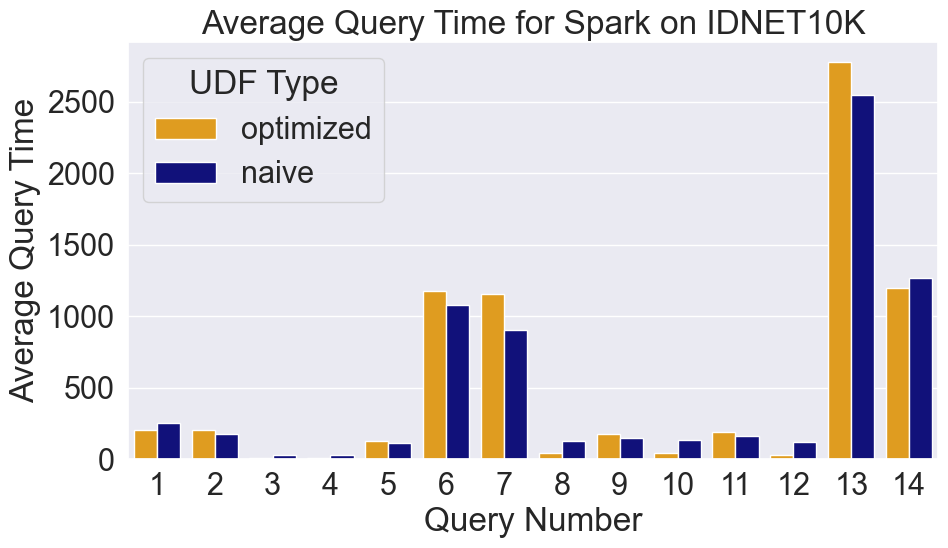

postgres idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,postgres,11,optimized,136.5,32.450607,40.282427,625442.4,473819.0,229260.3,0.0,0.0,67.437843,0.114465,0.0,0.000000,3.234890,0.0,4.569627,24.629111
1,idnet,postgres,6,naive,511.9,55.752137,35.236009,1933467.7,1387324.0,1061834.5,0.0,0.0,44.153692,0.094760,0.0,0.000513,6.710994,0.0,11.405982,37.634398
2,idnet,postgres,12,naive,13.6,81.983692,38.567311,44279.9,29671.8,10769.0,0.0,0.0,17.984527,0.031883,0.0,0.000000,8.962256,0.0,12.288515,60.719643
3,idnet,postgres,2,naive,71.1,45.071243,34.918272,302169.2,215439.2,101068.2,0.0,0.0,54.820118,0.109512,0.0,0.000375,4.891990,0.0,11.727611,28.449159
4,idnet,postgres,10,optimized,85.7,86.128287,40.042666,338625.4,308815.6,511259.6,0.0,0.0,13.834681,0.036754,0.0,0.000000,9.464003,0.0,13.712740,62.940509
5,idnet,postgres,4,optimized,10.1,82.080444,39.461972,34105.1,17730.0,7446.8,0.0,0.0,17.906222,0.006667,0.0,0.000000,8.777694,0.0,14.993500,58.120472
6,idnet,postgres,1,optimized,27.1,80.053963,40.123955,96466.8,60664.8,26980.2,0.0,0.0,19.901033,0.044257,0.0,0.000000,9.440527,0.0,13.168107,57.445337
7,idnet,postgres,3,naive,16.8,69.417630,34.991612,65241.1,51130.1,19761.3,0.0,0.0,27.478327,3.103140,0.0,0.000000,8.532558,0.0,11.471896,49.395315
8,idnet,postgres,3,optimized,10.4,82.205543,39.819737,35426.7,20498.5,7740.3,0.0,0.0,17.736336,0.056010,0.0,0.000000,8.646934,0.0,14.890250,58.669331
9,idnet,postgres,9,naive,73.1,43.852038,38.613852,318888.2,240219.8,483438.4,0.0,0.0,55.483649,0.664930,0.0,0.000400,5.207731,0.0,10.943381,27.702388


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


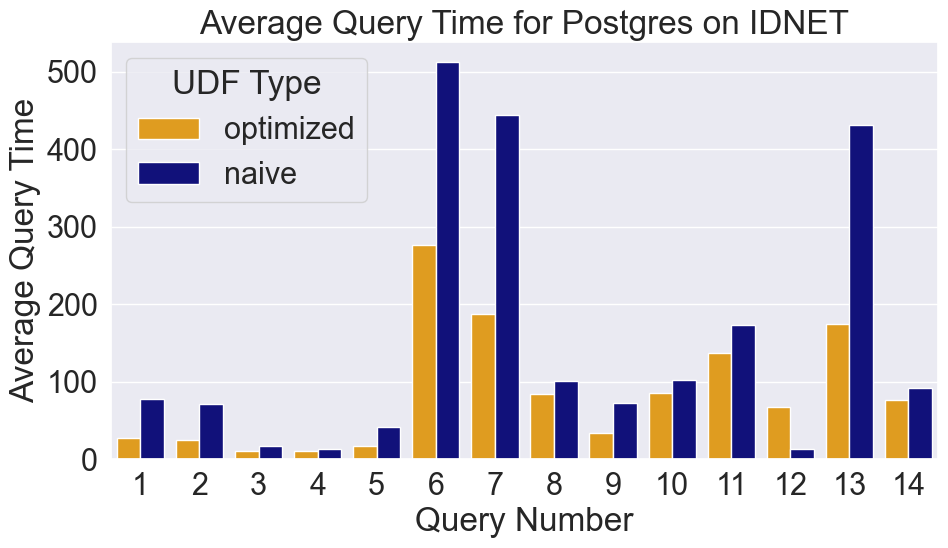

postgres idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,postgres,7,optimized,1559.8,76.791206,83.206696,4450295.8,4656391.6,6517796.2,0.0,0.0,21.888485,1.316112,0.0,0.000200,8.804574,0.0,9.017467,58.706005
1,idnet10k,postgres,4,optimized,99.8,94.609901,11.782196,288468.9,131006.3,47838.8,0.0,0.0,5.360701,0.017484,0.0,0.000000,9.300339,0.0,19.671388,65.150248
2,idnet10k,postgres,13,optimized,1617.8,78.211272,81.324223,4549257.4,2304168.4,6058664.0,0.0,0.0,19.532384,2.248778,0.0,0.000236,10.040787,0.0,10.628480,57.329372
3,idnet10k,postgres,1,optimized,277.4,90.019927,12.279158,927058.4,569487.0,252098.3,0.0,0.0,9.740877,0.230594,0.0,0.000465,10.440010,0.0,14.869784,64.546736
4,idnet10k,postgres,3,optimized,100.0,94.608905,12.003804,294021.7,129118.7,49194.7,0.0,0.0,5.368177,0.015901,0.0,0.000000,9.170596,0.0,19.864094,65.283486
5,idnet10k,postgres,12,optimized,508.2,92.406748,80.983751,1183173.6,288443.6,177678.2,0.0,0.0,6.695966,0.803281,0.0,0.000677,7.635715,0.0,11.298171,71.968332
6,idnet10k,postgres,9,optimized,346.6,53.017257,82.280012,1175599.0,1046023.0,4108347.6,0.0,0.0,44.216363,2.766273,0.0,0.000177,6.947640,0.0,8.181542,37.858771
7,idnet10k,postgres,2,naive,629.0,49.845188,27.083022,2672340.1,1844692.3,830667.7,0.0,0.0,49.954211,0.202018,0.0,0.000046,5.581605,0.0,11.671832,32.590144
8,idnet10k,postgres,1,naive,695.1,46.932389,26.774776,3178167.8,2210358.9,1023410.9,0.0,0.0,51.490762,1.575597,0.0,0.000186,5.159722,0.0,10.938005,30.832392
9,idnet10k,postgres,14,optimized,614.6,74.991383,81.682601,1643197.2,745635.0,4872154.8,0.0,0.0,22.064942,2.892305,0.0,0.000619,6.552939,0.0,10.004164,57.378041


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


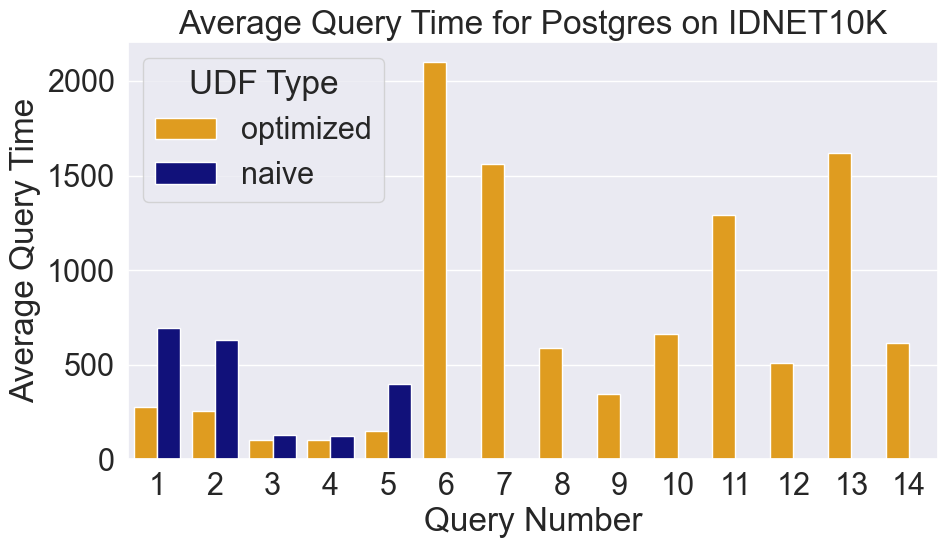

evadb idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,evadb,10,optimized,4.1,35.193000,13.114000,25501.0,28819.8,82725.7,0.0,0.0,64.655500,0.156500,0.0,0.0,5.713000,0.0,11.725500,17.744500
1,idnet,evadb,7,naive,3.0,27.533333,11.887500,20471.7,21779.3,75687.9,0.0,0.0,72.240833,0.223333,0.0,0.0,4.476667,0.0,11.121667,11.939167
2,idnet,evadb,3,optimized,2.7,29.768333,34.057500,18089.1,18545.7,73562.6,0.0,0.0,69.956667,0.283333,0.0,0.0,5.292500,0.0,9.224167,15.255000
3,idnet,evadb,8,optimized,3.3,25.519167,11.795833,21844.2,22413.1,79859.1,0.0,0.0,74.408333,0.075000,0.0,0.0,4.931667,0.0,9.966667,10.608333
4,idnet,evadb,10,naive,3.4,29.865000,13.520000,22272.3,23055.3,81662.2,0.0,0.0,70.005000,0.137500,0.0,0.0,4.940000,0.0,11.047500,13.890000
5,idnet,evadb,9,optimized,29.9,66.839792,13.942615,123954.8,90022.4,109846.4,0.0,0.0,33.098934,0.060695,0.0,0.0,7.836805,0.0,20.382528,38.615517
6,idnet,evadb,3,naive,3.5,30.630500,33.928667,21882.2,22849.4,78733.6,0.0,0.0,67.899167,1.464167,0.0,0.0,4.700333,0.0,9.275333,16.667833
7,idnet,evadb,1,naive,31.0,58.812761,33.372197,125580.6,88788.8,109517.9,0.0,0.0,38.652007,2.531197,0.0,0.0,7.720081,0.0,11.635766,39.455421
8,idnet,evadb,7,optimized,3.0,25.700833,11.826667,20389.5,21654.6,76451.7,0.0,0.0,74.152500,0.140000,0.0,0.0,4.969167,0.0,10.242500,10.492500
9,idnet,evadb,6,optimized,3.4,27.033167,12.509333,22616.6,24278.0,75961.6,0.0,0.0,72.896333,0.077667,0.0,0.0,4.718333,0.0,10.306333,12.012500


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


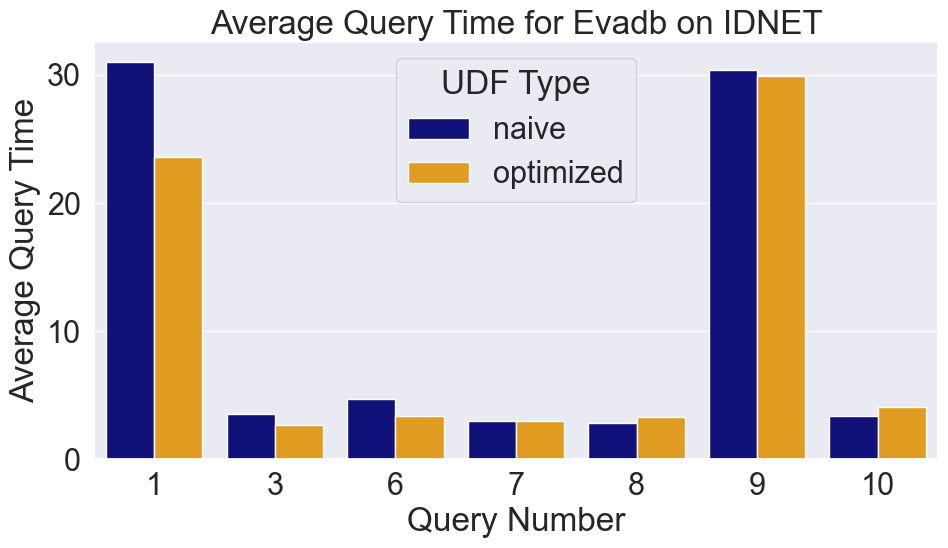

evadb idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,evadb,10,naive,27.2,31.483152,18.292645,200141.8,224399.2,807480.4,0.0,0.0,68.404928,0.116232,0.0,0.000000,7.171196,0.0,13.479638,10.829674
1,idnet10k,evadb,1,optimized,225.7,73.335090,32.312614,759210.3,470722.0,927829.9,0.0,0.0,26.364400,0.299526,0.0,0.001268,9.788604,0.0,12.996197,50.546404
2,idnet10k,evadb,9,naive,233.6,76.593044,24.799025,872147.0,705983.6,950579.4,0.0,0.0,23.290410,0.116246,0.0,0.000000,8.315670,0.0,20.798535,47.480150
3,idnet10k,evadb,7,naive,26.8,31.151700,18.287194,196899.0,220277.6,803363.4,0.0,0.0,68.696324,0.152806,0.0,0.000000,6.283874,0.0,14.134585,10.737708
4,idnet10k,evadb,7,optimized,24.2,25.755348,17.727527,143268.9,163836.5,799630.1,0.0,0.0,73.866978,0.379697,0.0,0.000000,6.212288,0.0,11.122126,8.423558
5,idnet10k,evadb,3,optimized,27.9,32.106559,27.094611,175765.2,185830.5,817920.0,0.0,0.0,67.478676,0.417269,0.0,0.000000,6.240763,0.0,11.710122,14.150914
6,idnet10k,evadb,8,optimized,23.8,25.612052,17.884807,141428.6,156966.1,814128.7,0.0,0.0,74.166668,0.225092,0.0,0.000000,5.753257,0.0,11.434952,8.423891
7,idnet10k,evadb,6,optimized,30.5,24.206667,17.175594,163933.1,174380.2,819153.2,0.0,0.0,74.491667,1.186663,0.0,0.000000,5.390688,0.0,10.826154,7.986451
8,idnet10k,evadb,8,naive,27.2,30.448300,18.438775,196583.2,225379.2,803070.8,0.0,0.0,69.419723,0.131067,0.0,0.000000,6.784822,0.0,13.443083,10.227273
9,idnet10k,evadb,10,optimized,23.9,25.920936,17.304016,140989.3,159237.6,805532.1,0.0,0.0,73.934807,0.147524,0.0,0.000000,5.414342,0.0,11.589408,8.915694


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


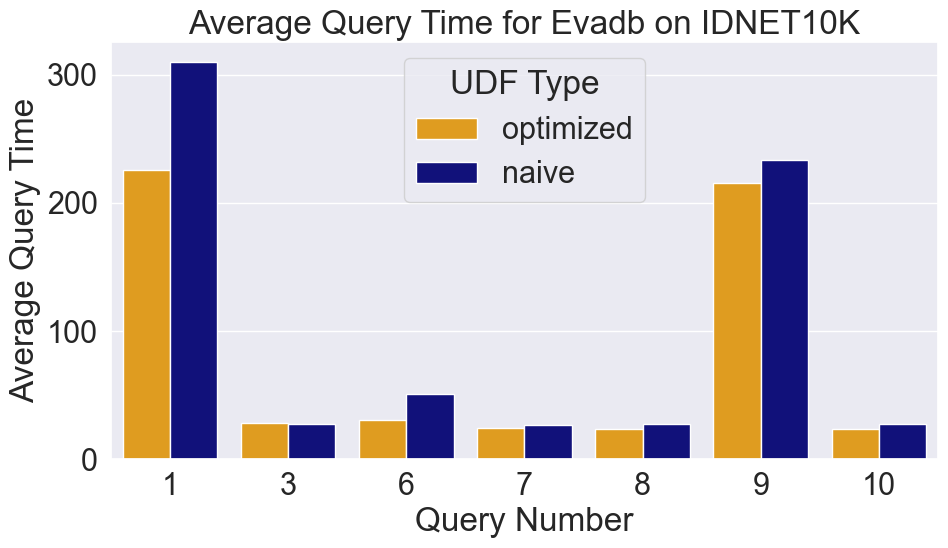

duckdb idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,duckdb,14,naive,117.4,33.652246,32.006545,945878.7,1277144.3,236229.2,0.0,0.0,66.230567,0.114189,0.0,0.000112,1.882034,0.0,9.992973,21.777488
1,idnet,duckdb,3,optimized,0.0,14.570000,32.920000,0.0,0.0,0.0,0.0,0.0,85.200000,0.250000,0.0,0.000000,1.720000,0.0,9.290000,3.550000
2,idnet,duckdb,10,naive,120.3,28.092172,31.732535,1014748.4,1399220.8,255147.2,0.0,0.0,71.777794,0.125192,0.0,0.000000,1.088499,0.0,8.950629,18.055497
3,idnet,duckdb,11,naive,648.2,41.042407,30.554925,5566711.6,8079373.1,1465510.5,0.0,0.0,58.834104,0.126959,0.0,0.000000,1.770165,0.0,11.021158,28.253936
4,idnet,duckdb,2,naive,113.0,48.939201,31.484663,756789.2,968238.0,199438.9,0.0,0.0,50.913964,0.148003,0.0,0.003636,3.542638,0.0,11.417025,33.979039
5,idnet,duckdb,9,optimized,40.8,51.765835,42.168022,202578.2,181869.9,51588.2,0.0,0.0,48.127185,0.108412,0.0,0.000000,4.346576,0.0,20.436475,26.985018
6,idnet,duckdb,13,optimized,266.1,49.173686,54.037026,1556833.3,1648714.0,407664.0,0.0,0.0,50.506194,0.320915,0.0,0.000000,3.663516,0.0,19.332105,26.161685
7,idnet,duckdb,12,optimized,0.0,16.600000,32.060000,0.0,0.0,0.0,0.0,0.0,81.890000,1.520000,0.0,0.000000,1.990000,0.0,10.740000,3.850000
8,idnet,duckdb,4,optimized,0.0,9.900000,32.790000,0.0,0.0,0.0,0.0,0.0,89.990000,0.110000,0.0,0.000000,1.770000,0.0,3.460000,4.670000
9,idnet,duckdb,9,naive,86.7,45.506774,29.488163,643281.0,868495.9,172784.2,0.0,0.0,54.386089,0.109594,0.0,0.000571,3.222671,0.0,11.000567,31.287161


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


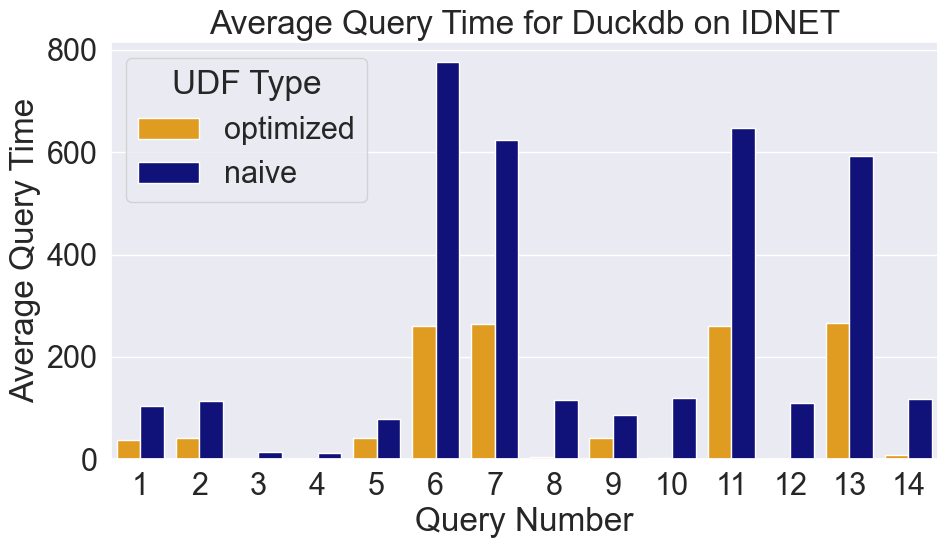

duckdb idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,duckdb,3,optimized,0.1,15.715000,22.610000,562.9,547.4,193.7,0.0,0.0,82.695000,1.610000,0.0,0.000000,1.830000,0.0,10.100000,3.770000
1,idnet10k,duckdb,2,naive,1177.8,46.484069,25.336598,8836262.7,11760843.5,2267444.6,0.0,0.0,53.257059,0.260834,0.0,0.000085,2.612794,0.0,11.194167,32.680833
2,idnet10k,duckdb,2,optimized,406.9,51.817068,50.529112,2271486.4,2161950.2,555125.4,0.0,0.0,47.041081,1.139224,0.0,0.000799,4.456005,0.0,19.557263,27.745149
3,idnet10k,duckdb,5,naive,1088.1,51.114654,25.317050,7442420.1,9429675.7,1909465.7,0.0,0.0,48.774933,0.112060,0.0,0.000149,3.896410,0.0,11.501994,35.720142
4,idnet10k,duckdb,4,optimized,0.0,15.580000,22.520000,0.0,0.0,0.0,0.0,0.0,81.030000,3.400000,0.0,0.000000,1.670000,0.0,4.460000,9.470000
5,idnet10k,duckdb,1,optimized,417.7,52.367579,50.844168,2247133.4,2070859.1,565953.4,0.0,0.0,44.998763,2.631104,0.0,0.000054,4.959938,0.0,19.958009,27.382703
6,idnet10k,duckdb,4,naive,131.8,60.576277,18.417512,862034.6,1063485.6,200377.1,0.0,0.0,39.320734,0.096133,0.0,0.000000,6.799111,0.0,14.457343,39.143915
7,idnet10k,duckdb,3,naive,124.4,67.073093,18.418590,752261.0,881757.3,170504.5,0.0,0.0,32.829751,0.094673,0.0,0.000417,7.741236,0.0,15.810034,43.500027
8,idnet10k,duckdb,1,naive,1060.5,53.248121,25.772979,6799003.6,8348743.8,1746571.7,0.0,0.0,46.480503,0.269767,0.0,0.000109,4.534091,0.0,11.224183,37.492224
9,idnet10k,duckdb,5,optimized,379.9,55.186003,51.191516,1954906.7,1724629.3,459250.6,0.0,0.0,44.152269,0.660745,0.0,0.000089,5.208884,0.0,21.458723,28.442445


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


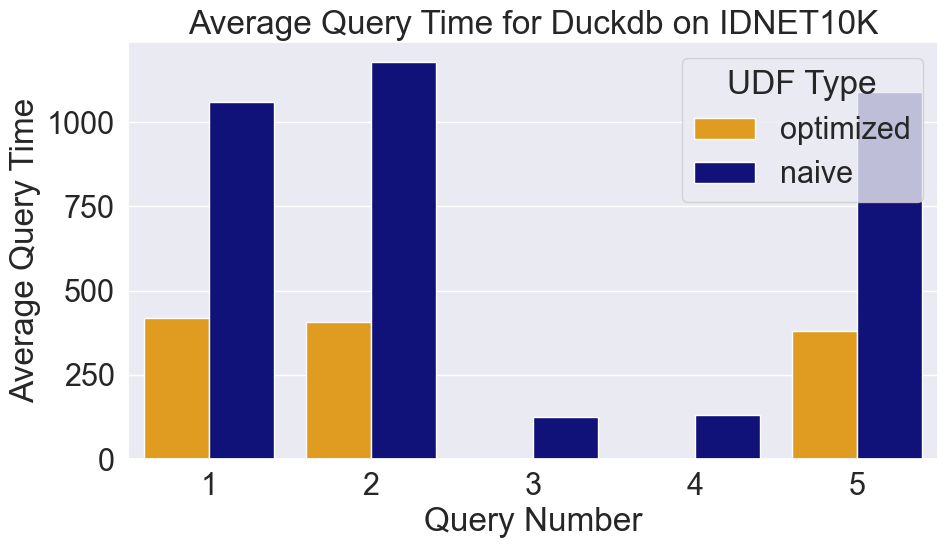

clickhouse idnet


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet,clickhouse,14,naive,1272.8,32.399600,21.369794,7245571.0,7237411.2,2906458.2,0.0,0.0,67.436273,0.163661,0.0,0.000000,2.893466,0.0,7.769025,21.736541
1,idnet,clickhouse,2,naive,321.9,97.320697,10.758608,1090202.3,801401.0,233715.4,0.0,0.0,2.673281,0.005848,0.0,0.000669,10.820600,0.0,16.890413,69.607452
2,idnet,clickhouse,1,naive,349.8,97.425973,10.815230,1197248.3,880885.8,255644.9,0.0,0.0,2.552671,0.004065,0.0,0.000000,10.786266,0.0,16.696877,69.945499
3,idnet,clickhouse,10,naive,1293.2,32.593659,18.949059,7329864.4,7335686.2,2948173.2,0.0,0.0,66.996390,0.409174,0.0,0.000000,3.012766,0.0,7.823019,21.758359
4,idnet,clickhouse,7,naive,3746.4,35.896852,18.073984,17396989.8,17733374.8,5348022.4,0.0,0.0,63.938772,0.160038,0.0,0.000041,3.805626,0.0,8.955144,23.134219
5,idnet,clickhouse,5,naive,187.9,96.557360,10.758731,641167.8,509108.7,139313.7,0.0,0.0,3.432941,0.009422,0.0,0.000000,10.811961,0.0,16.726555,69.021449
6,idnet,clickhouse,9,naive,3427.2,29.827977,18.743323,16519201.8,16780840.6,5118029.4,0.0,0.0,69.973020,0.199229,0.0,0.000047,3.004614,0.0,7.607060,19.216466
7,idnet,clickhouse,8,naive,1305.8,33.223114,18.248858,7426894.4,7432314.4,2984211.6,0.0,0.0,66.333497,0.442743,0.0,0.010910,3.033628,0.0,7.910709,22.267894
8,idnet,clickhouse,11,naive,845.4,99.383198,17.798691,2475539.6,2610193.0,594987.8,0.0,0.0,0.524118,0.002526,0.0,0.000400,13.938497,0.0,22.478253,62.751928
9,idnet,clickhouse,12,naive,16.6,82.339484,17.752500,50279.0,51940.8,11430.8,0.0,0.0,17.057460,0.041667,0.0,0.000000,10.938452,0.0,24.781349,46.463849


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


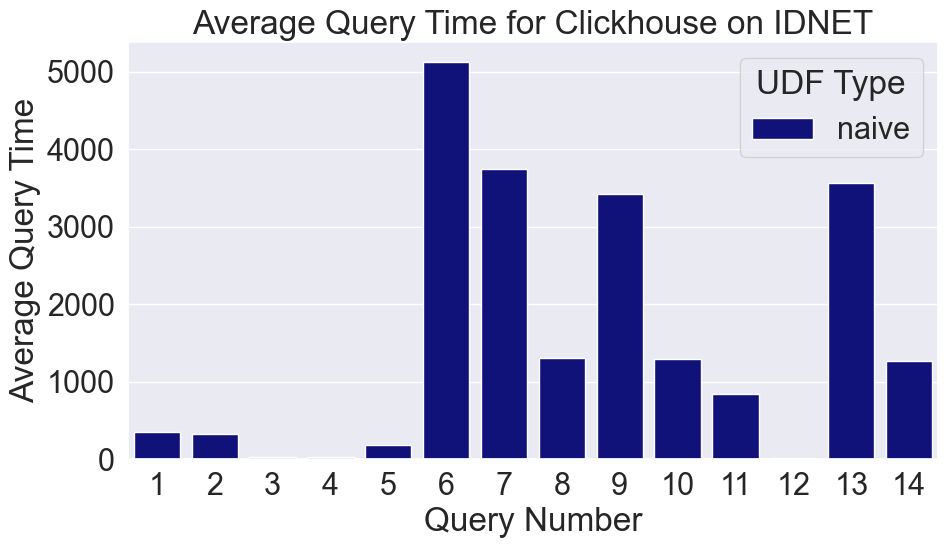

clickhouse idnet10k


,experiment,system,query,udf,query_time_avg,cpu_avg,mem_avg,avg_interrupts,avg_ctx_switch,avg_soft_interrupts,cpu_guest_nice_percent_avg,cpu_guest_percent_avg,cpu_idle_percent_avg,cpu_iowait1_percent_avg,cpu_irq_percent_avg,cpu_nice_percent_avg,cpu_softirq_percent_avg,cpu_steal_percent_avg,cpu_system_percent_avg,cpu_user_percent_avg
0,idnet10k,clickhouse,2,naive,4996.000000,99.810085,12.268799,1.686558e+07,1.191682e+07,3.150743e+06,0.0,0.0,0.189560,0.000311,0.0,0.000254,10.648606,0.0,16.420730,72.680638
1,idnet10k,clickhouse,14,naive,7318.000000,84.572941,63.375721,2.551408e+07,2.713746e+07,1.083545e+07,0.0,0.0,12.192600,3.233981,0.0,0.000688,13.405950,0.0,19.628584,51.467379
2,idnet10k,clickhouse,1,naive,5018.000000,99.816777,12.258299,1.703911e+07,1.202087e+07,3.178413e+06,0.0,0.0,0.175261,0.000741,0.0,0.000442,10.517746,0.0,16.461805,72.773841
3,idnet10k,clickhouse,9,naive,11612.000000,89.374240,60.916568,3.493003e+07,3.363054e+07,1.023475e+07,0.0,0.0,9.955929,0.665038,0.0,0.000311,13.620604,0.0,23.129868,52.218799
4,idnet10k,clickhouse,3,naive,489.000000,99.719109,10.872539,1.650575e+06,1.510660e+06,3.064867e+05,0.0,0.0,0.276512,0.003188,0.0,0.000882,10.637814,0.0,15.676594,73.316474
5,idnet10k,clickhouse,5,naive,3064.666667,99.904376,12.180184,1.049537e+07,7.567275e+06,1.989797e+06,0.0,0.0,0.095424,0.000200,0.0,0.000201,10.619406,0.0,16.241984,72.995742
6,idnet10k,clickhouse,8,naive,6764.000000,90.783726,59.235309,2.250247e+07,2.354272e+07,9.905754e+06,0.0,0.0,8.205896,1.009729,0.0,0.000325,14.500682,0.0,20.832435,55.375654
7,idnet10k,clickhouse,10,naive,6850.000000,89.973914,60.017722,2.294306e+07,2.407481e+07,1.005180e+07,0.0,0.0,8.263676,1.762186,0.0,0.000320,14.423249,0.0,20.800128,54.680388
8,idnet10k,clickhouse,6,naive,17560.000000,94.635951,15.545115,5.282279e+07,5.353278e+07,1.879144e+07,0.0,0.0,5.315681,0.037959,0.0,0.004477,14.823022,0.0,23.054990,56.448012
9,idnet10k,clickhouse,13,naive,12331.000000,84.170554,65.141537,3.904479e+07,3.827717e+07,1.145117e+07,0.0,0.0,11.819621,4.005973,0.0,0.000584,12.791829,0.0,21.885379,49.080272


/var/folders/hs/97vclz612rz8zrjjxdgzxglm0000gn/T/ipykernel_9910/1619248486.py:18: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)


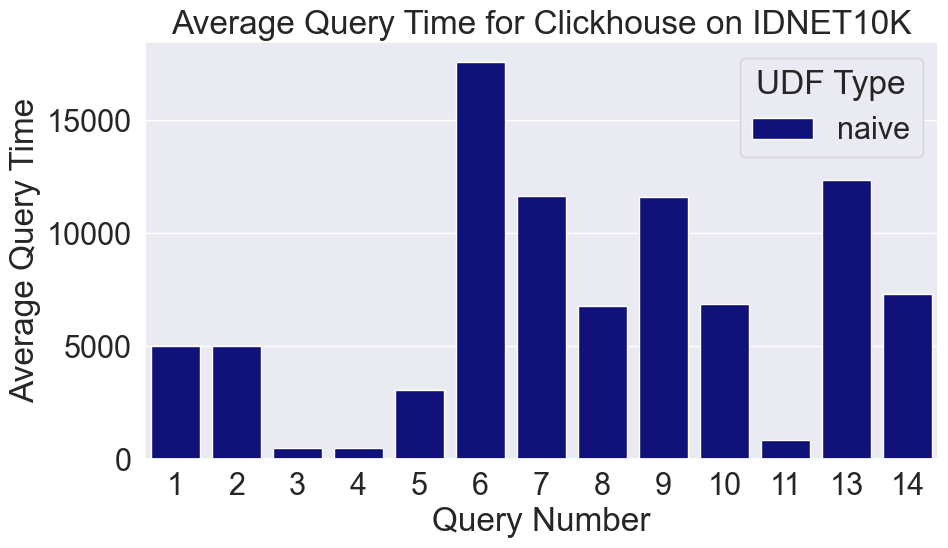

In [38]:
systems = ['spark', 'postgres', 'evadb', 'duckdb', 'clickhouse']
tables = ['idnet', 'idnet10k']

sns.set_theme(font_scale=2)
sns.set_context("notebook", font_scale=2)

for system in systems:
    for table in tables:
        try:
            print(system, table)

            hues = {'optimized': 'orange', 'naive': 'darkblue'}
            #final.filter(f"system='{system}'  and experiment='{table}'").show()
            df = final.filter(f"system='{system}' and experiment='{table}'").toPandas()
            display(df)
            # Use seaborn to create the grouped bar plot
            plt.figure(figsize=(10, 6)) # Set the figure size
            sns.barplot(data=df, x='query', y='query_time_avg', hue='udf', palette=hues, ci=None)

            # Add titles and labels for clarity
            plt.title(f'Average Query Time for {system.capitalize()} on {table.upper()}')
            plt.xlabel(f'Query Number')
            plt.ylabel('Average Query Time')
            plt.legend(title='UDF Type')

            plt.savefig(f'./pics/{system}{table}.png', transparent=False, bbox_inches='tight')
            # Display the plot
            plt.tight_layout()
            plt.show()


        except Exception as e:
            print(f'{system} {table} failed')
            print(e)

In [33]:
print('done')


done


In [34]:
util_df = spark.sql("select system, query, run, udf, cpu_percent, memory_percent, time from {output} where query=1 and run=2 and experiment='idnet'", output=output)

In [35]:
util_df.show()

+----------+-----+---+-----+-----------+--------------+--------------------+
|    system|query|run|  udf|cpu_percent|memory_percent|                time|
+----------+-----+---+-----+-----------+--------------+--------------------+
|clickhouse|    1|  2|naive|       12.3|          10.1|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       35.6|          10.7|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       63.5|          10.8|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       96.9|          10.8|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       98.8|          10.9|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       99.4|          10.9|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       99.4|          10.9|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       99.4|          10.9|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|      100.0|          10.9|2025-11-11 15:38:...|
|clickhouse|    1|  2|naive|       99.4|          10.9|2025-11-11 15:38:...|

In [36]:
util_df.printSchema()

root
 |-- system: string (nullable = true)
 |-- query: long (nullable = true)
 |-- run: long (nullable = true)
 |-- udf: string (nullable = true)
 |-- cpu_percent: double (nullable = true)
 |-- memory_percent: double (nullable = true)
 |-- time: string (nullable = true)



spark


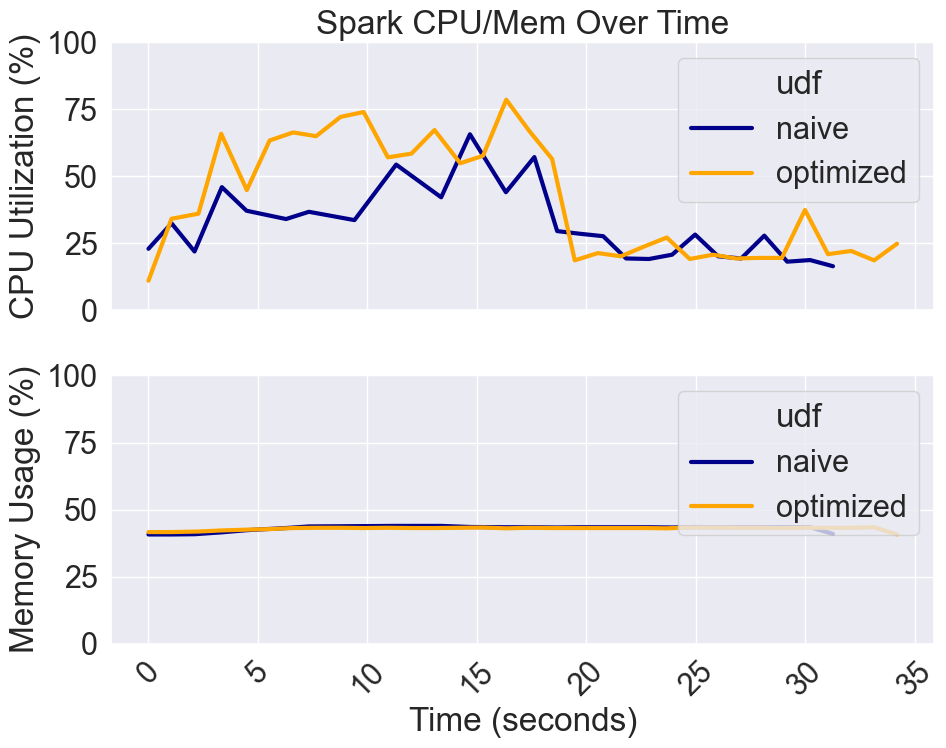

postgres


<Figure size 640x480 with 0 Axes>

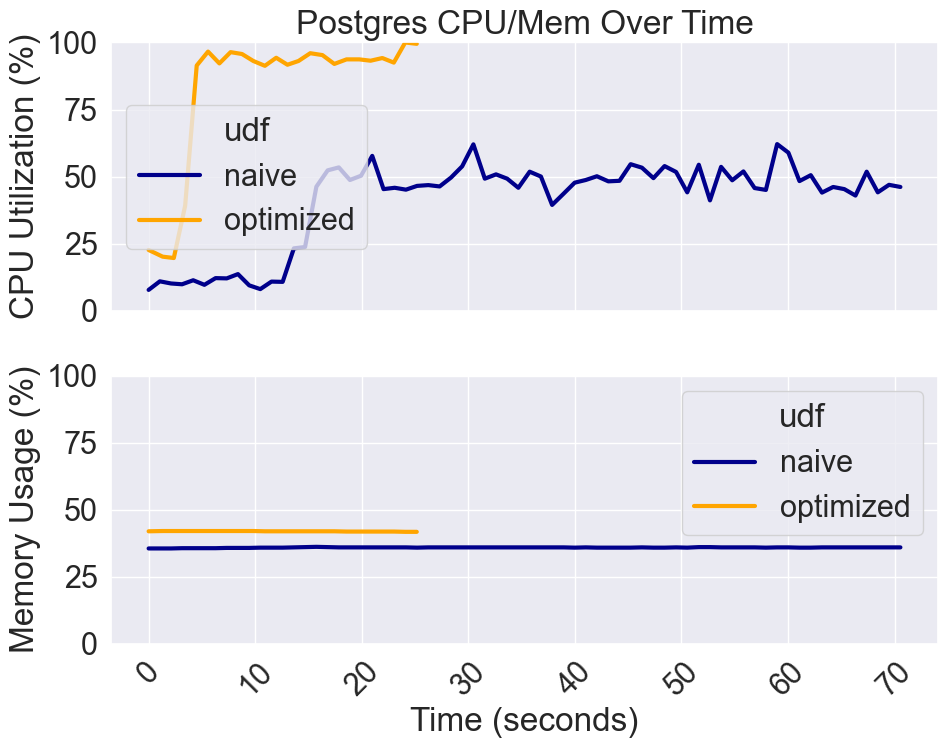

evadb


<Figure size 640x480 with 0 Axes>

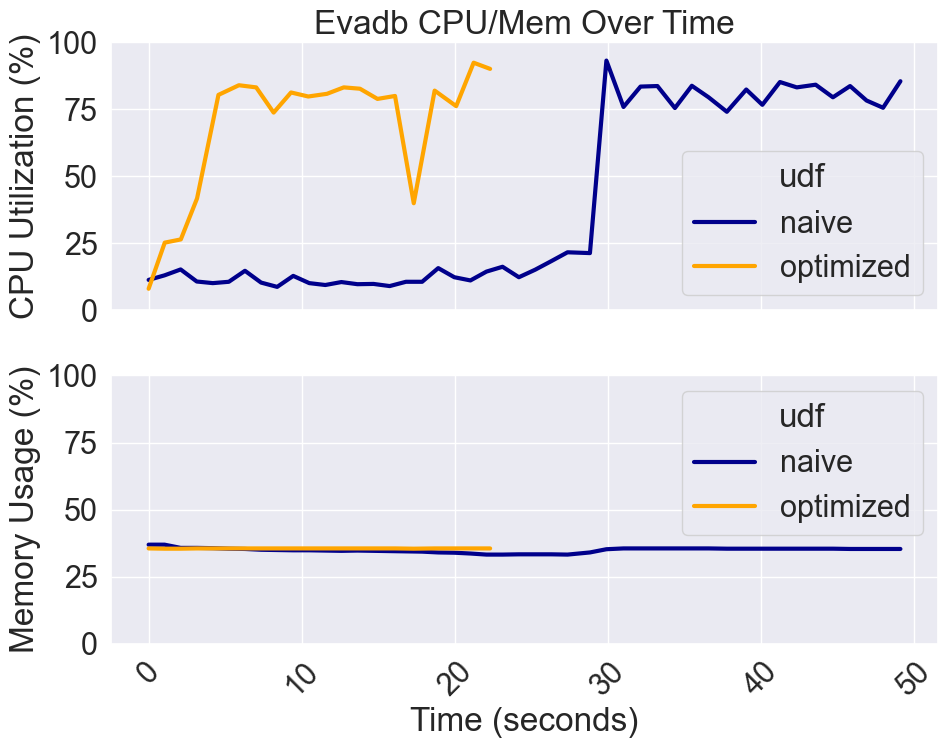

duckdb


<Figure size 640x480 with 0 Axes>

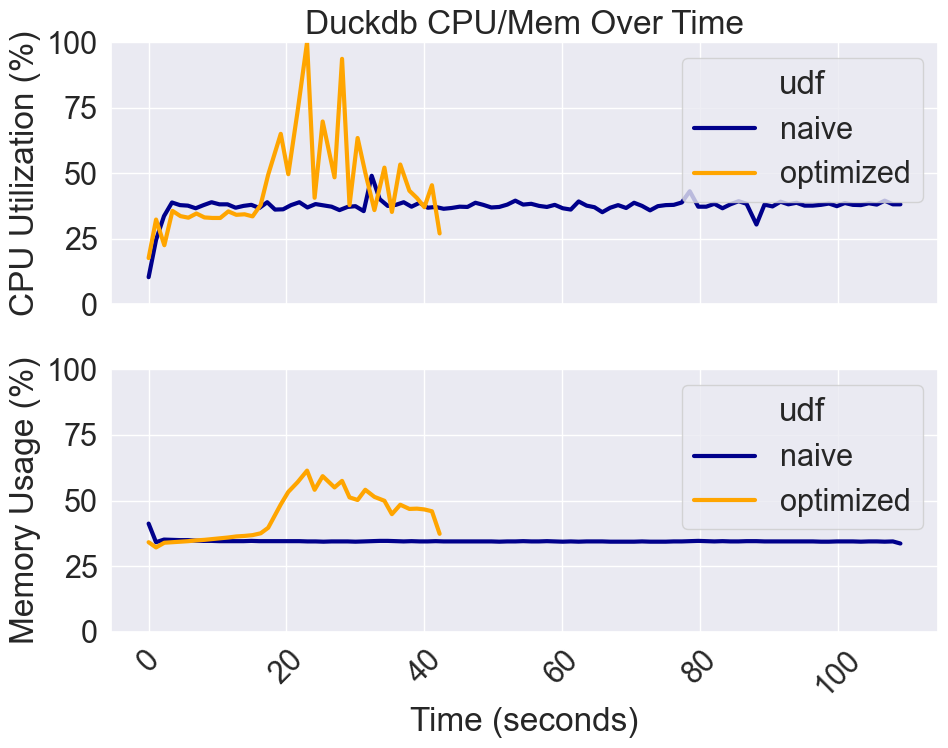

clickhouse


<Figure size 640x480 with 0 Axes>

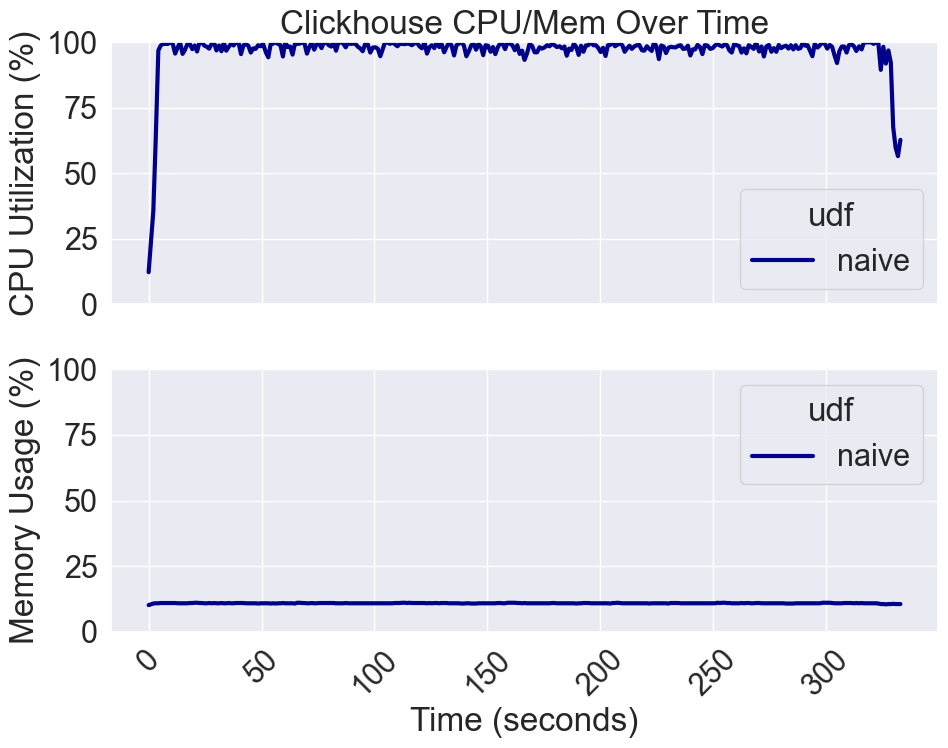

<Figure size 640x480 with 0 Axes>

In [39]:


hues = {'optimized': 'orange', 'naive': 'darkblue'}

systems = ['spark', 'postgres', 'evadb', 'duckdb', 'clickhouse']
#systems = ['postgres']

i=0
for system in systems:
    print(system)



    df_1 = spark.sql("select *, CAST(time AS TIMESTAMP) as elapsed_time from {util_df} where system = {system} and udf = 'naive'", util_df=util_df, system=system).toPandas()
    df_2 = spark.sql("select *, CAST(time AS TIMESTAMP) as elapsed_time from {util_df} where system = {system} and udf = 'optimized'", util_df=util_df, system=system).toPandas()

    df_1['elapsed'] = (df_1['elapsed_time'] - df_1['elapsed_time'].min()).dt.total_seconds()
    df_2['elapsed'] = (df_2['elapsed_time'] - df_2['elapsed_time'].min()).dt.total_seconds()

    df = pd.concat([df_1, df_2], ignore_index=True)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    # 3. Plot CPU usage (Top Graph)
    a = sns.lineplot(data=df, x='elapsed', y='cpu_percent', hue='udf', palette=hues, ax=ax1, color='blue', linewidth=3)
    ax1.set_ylabel('CPU Utilization (%)')
    ax1.set_title(f'{system.capitalize()} CPU/Mem Over Time')
    ax1.set_ylim(0, 100)

    # 4. Plot Memory usage (Bottom Graph)
    b = sns.lineplot(data=df, x='elapsed', y='memory_percent', hue='udf', palette=hues, ax=ax2, color='red', linewidth=3)
    ax2.set_ylabel('Memory Usage (%)')
    ax2.set_xlabel('Time (seconds)')
    ax2.set_ylim(0, 100)

    # 5. Optimize layout
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f'./util_pics/{system}.png', transparent=False, bbox_inches='tight')
    plt.show()
    plt.clf()
